In [1]:
import mne
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

In [60]:
example_data = "/Users/qmoreau/Documents/ERN_sim/ernpipeline/sub-AU09GE22/sub-AU09GE22_desc-epochs_eeg.fif"
# load epochs
epochs = mne.read_epochs(example_data, preload=True)

epochs

Reading /Users/qmoreau/Documents/ERN_sim/ernpipeline/sub-AU09GE22/sub-AU09GE22_desc-epochs_eeg.fif ...
    Found the data of interest:
        t =   -5000.00 ...    5000.00 ms
        0 CTF compensation matrices available
Not setting metadata
228 matching events found
No baseline correction applied
0 projection items activated


Number of events,228
Events,107: 11109: 27117: 30119: 12127: 25129: 10137: 102139: 11
Time range,-5.000 – 5.000 s
Baseline,-0.200 – 0.000 s


Number of error trials: 60


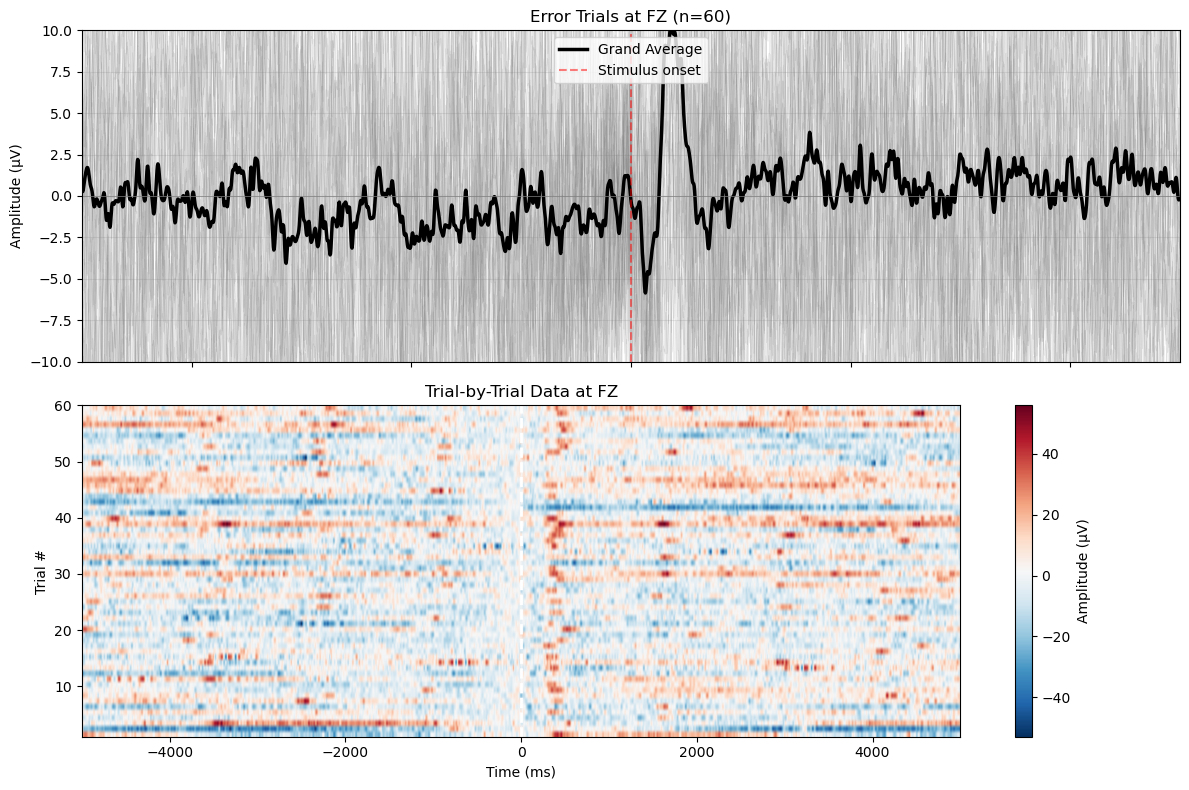

In [62]:
# Extract incorrect trials
incorrect_codes = ['108', '109', '118', '119', '128', '129', '138', '139']
epochs_incorrect = epochs[incorrect_codes]

print(f"Number of error trials: {len(epochs_incorrect)}")

channel = 'FZ'

# Get data: trials x times
data = epochs_incorrect.copy().pick([channel]).get_data()[:, 0, :]  # (n_trials, n_times)
times = epochs_incorrect.times
grand_avg = data.mean(axis=0)

# Convert to microvolts
data_uv = data * 1e6
grand_avg_uv = grand_avg * 1e6

# Plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Single trials
ax1.plot(times * 1000, data_uv.T, 'gray', alpha=0.15, linewidth=0.5)
ax1.plot(times * 1000, grand_avg_uv, 'k', linewidth=2.5, label='Grand Average')
ax1.axvline(0, color='r', linestyle='--', alpha=0.5, label='Stimulus onset')
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'Error Trials at {channel} (n={len(epochs_incorrect)})')
ax1.legend()
ax1.grid(alpha=0.3)
ax1.set_xlim([times[0] * 1000, times[-1] * 1000])
ax1.set_ylim([-10, 10])

# Image of all trials
im = ax2.imshow(data_uv, aspect='auto', origin='lower',
                extent=[times[0] * 1000, times[-1] * 1000, 1, len(epochs_incorrect)],
                cmap='RdBu_r')
ax2.axvline(0, color='white', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Trial #')
ax2.set_title(f'Trial-by-Trial Data at {channel}')
plt.colorbar(im, ax=ax2, label='Amplitude (µV)')

plt.tight_layout()
plt.show()

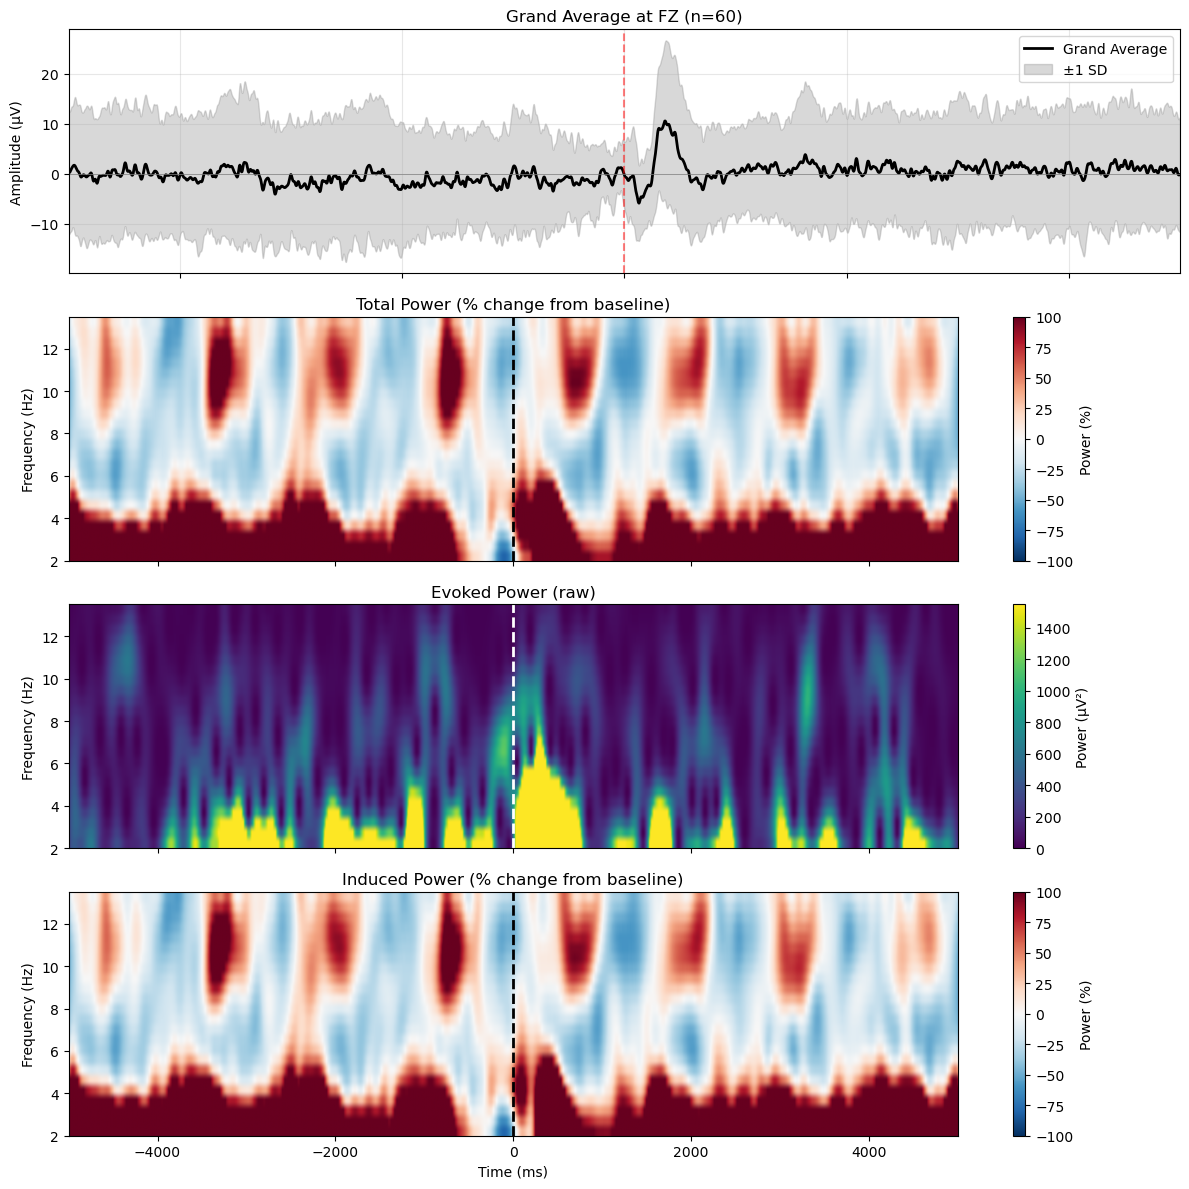

In [63]:
# Time-Frequency Analysis
freqs = np.arange(2, 14, 0.5)  # 2-14 Hz
n_cycles = freqs / 2.0
n_trials = len(data_uv)

sfreq = epochs_incorrect.info['sfreq']
grand_avg = data_uv.mean(axis=0)
sd = data_uv.std(axis=0)

# EVOKED POWER (TFR of averaged signal)
tfr_evoked = np.zeros((len(freqs), len(times)))
for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
    wavelet_duration = min(3 * n_cycle / freq, 0.5)
    wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
    wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
    convolved = np.convolve(grand_avg, wavelet, mode='same')
    tfr_evoked[idx, :] = np.abs(convolved) ** 2

# TOTAL POWER (average of single-trial TFRs)
tfr_total = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(data_uv[trial, :], wavelet, mode='same')
        tfr_total[idx, :] += np.abs(convolved) ** 2
tfr_total /= n_trials

# INDUCED POWER = Total - Evoked
tfr_induced = tfr_total - tfr_evoked

# BASELINE CORRECTION (% change) - only for total and induced
# Define baseline period: -500 to -200 ms
baseline_mask = (times >= -0.5) & (times <= -0.2)

# Compute baseline mean for each frequency
baseline_total = tfr_total[:, baseline_mask].mean(axis=1, keepdims=True)
baseline_induced = tfr_induced[:, baseline_mask].mean(axis=1, keepdims=True)

# Convert to % change (only total and induced)
tfr_total_pct = ((tfr_total - baseline_total) / baseline_total) * 100
tfr_induced_pct = ((tfr_induced - baseline_induced) / baseline_induced) * 100

# Save raw results
tfr_total_raw_pct = tfr_total_pct.copy()
tfr_induced_raw_pct = tfr_induced_pct.copy()

# Plot
fig, axes = plt.subplots(4, 1, figsize=(12, 12), sharex=True)

# Grand average ERP with SD
axes[0].plot(times * 1000, grand_avg, 'k', linewidth=2, label='Grand Average')
axes[0].fill_between(times * 1000, grand_avg - sd, grand_avg + sd, 
                      color='gray', alpha=0.3, label='±1 SD')
axes[0].axvline(0, color='r', linestyle='--', alpha=0.5)
axes[0].axhline(0, color='gray', linestyle='-', linewidth=0.5)
axes[0].set_ylabel('Amplitude (µV)')
axes[0].set_title(f'Grand Average at {channel} (n={n_trials})')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Total Power (baseline corrected)
im1 = axes[1].imshow(tfr_total_pct, aspect='auto', origin='lower', 
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[1].axvline(0, color='black', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('Total Power (% change from baseline)')
plt.colorbar(im1, ax=axes[1], label='Power (%)')

# Evoked Power (NOT baseline corrected)
vmax_evoked = np.percentile(tfr_evoked, 95)
im2 = axes[2].imshow(tfr_evoked, aspect='auto', origin='lower', 
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=vmax_evoked, cmap='viridis')
axes[2].axvline(0, color='white', linestyle='--', linewidth=2)
axes[2].set_ylabel('Frequency (Hz)')
axes[2].set_title('Evoked Power (raw)')
plt.colorbar(im2, ax=axes[2], label='Power (µV²)')

# Induced Power (baseline corrected)
im3 = axes[3].imshow(tfr_induced_pct, aspect='auto', origin='lower', 
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[3].axvline(0, color='black', linestyle='--', linewidth=2)
axes[3].set_xlabel('Time (ms)')
axes[3].set_ylabel('Frequency (Hz)')
axes[3].set_title('Induced Power (% change from baseline)')
plt.colorbar(im3, ax=axes[3], label='Power (%)')

plt.tight_layout()
plt.show()

Alignment lags: mean=-20.6 ms, std=174.0 ms
Lag range: [-400.0, 400.0] ms


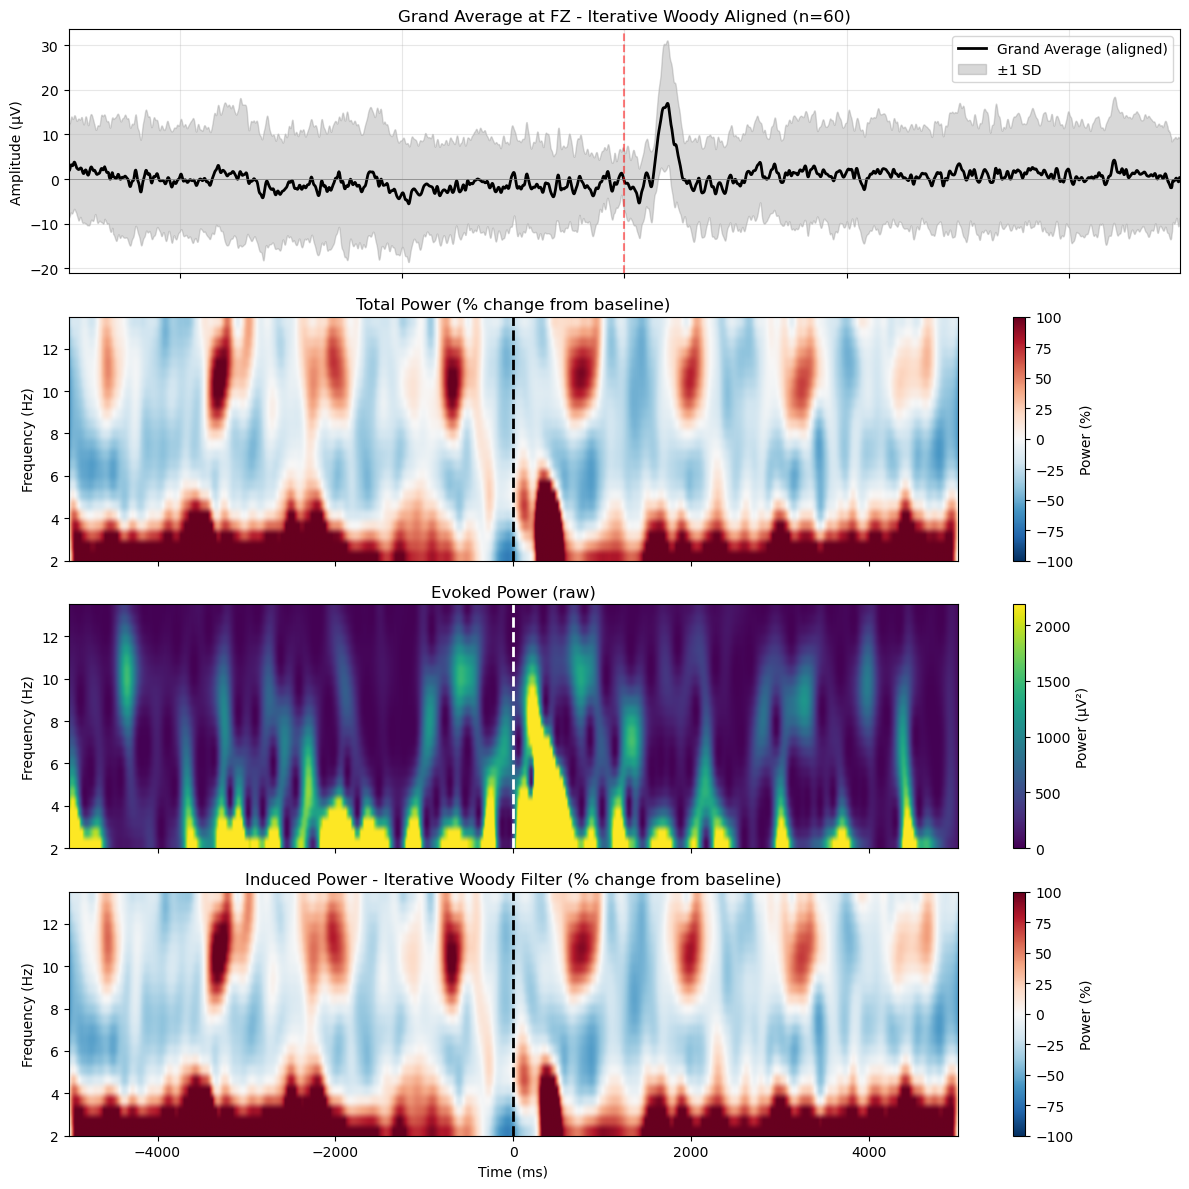

In [64]:
from scipy import signal
from woody_filter import woody

# Transpose to correct shape: (n_timepoints, n_trials)
data_T = data_uv.T

# Apply proper iterative Woody filter
aligned_avg, detected_lags = woody(
    data_T,
    tol=0.1,
    max_it=100,
    est_mthd='woody',
    xcorr_mthd='unbiased',
    max_shift=100
)

# Reconstruct individual aligned trials
n_trials, n_times = data_uv.shape
aligned_trials = np.zeros_like(data_uv)

for i in range(n_trials):
    lag = detected_lags[i]
    if lag > 0:
        # Positive lag: trial is delayed, shift left
        aligned_trials[i, :] = np.concatenate([data_uv[i, lag:], np.zeros(lag)])
    elif lag < 0:
        # Negative lag: trial is early, shift right
        aligned_trials[i, :] = np.concatenate([np.zeros(-lag), data_uv[i, :lag]])
    else:
        aligned_trials[i, :] = data_uv[i, :]

# Convert lags to milliseconds for reporting
lags_ms = detected_lags / sfreq * 1000

print(f"Alignment lags: mean={lags_ms.mean():.1f} ms, std={lags_ms.std():.1f} ms")
print(f"Lag range: [{lags_ms.min():.1f}, {lags_ms.max():.1f}] ms")

# Time-Frequency Analysis
freqs = np.arange(2, 14, 0.5)  # 2-14 Hz
n_cycles = freqs / 2.0
n_trials = len(aligned_trials)

sfreq = epochs_incorrect.info['sfreq']

# Grand average from ALIGNED trials
grand_avg_aligned = aligned_trials.mean(axis=0)
sd_aligned = aligned_trials.std(axis=0)

# EVOKED POWER (TFR of aligned averaged signal)
tfr_evoked = np.zeros((len(freqs), len(times)))
for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
    wavelet_duration = min(3 * n_cycle / freq, 0.5)
    wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
    wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
    convolved = np.convolve(grand_avg_aligned, wavelet, mode='same')
    tfr_evoked[idx, :] = np.abs(convolved) ** 2

# TOTAL POWER (average of single-trial TFRs from aligned trials)
tfr_total = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(aligned_trials[trial, :], wavelet, mode='same')
        tfr_total[idx, :] += np.abs(convolved) ** 2
tfr_total /= n_trials

# INDUCED POWER: Subtract aligned ERP from aligned trials, then compute TFR
tfr_induced_woody = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    # Subtract aligned grand average ERP from this aligned trial
    residual = aligned_trials[trial, :] - grand_avg_aligned
    
    # Compute TFR on residual
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(residual, wavelet, mode='same')
        tfr_induced_woody[idx, :] += np.abs(convolved) ** 2
tfr_induced_woody /= n_trials

# BASELINE CORRECTION (% change)
baseline_mask = (times >= -0.5) & (times <= -0.2)

baseline_total = tfr_total[:, baseline_mask].mean(axis=1, keepdims=True)
baseline_induced = tfr_induced_woody[:, baseline_mask].mean(axis=1, keepdims=True)

tfr_total_pct = ((tfr_total - baseline_total) / baseline_total) * 100
tfr_induced_pct = ((tfr_induced_woody - baseline_induced) / baseline_induced) * 100

# Save woody results
tfr_total_woody_pct = tfr_total_pct.copy()
tfr_induced_woody_pct = tfr_induced_pct.copy()

# Plot
fig, axes = plt.subplots(4, 1, figsize=(12, 12), sharex=True)

# Grand average ERP with SD (from aligned trials)
axes[0].plot(times * 1000, grand_avg_aligned, 'k', linewidth=2, label='Grand Average (aligned)')
axes[0].fill_between(times * 1000, grand_avg_aligned - sd_aligned, grand_avg_aligned + sd_aligned, 
                      color='gray', alpha=0.3, label='±1 SD')
axes[0].axvline(0, color='r', linestyle='--', alpha=0.5)
axes[0].axhline(0, color='gray', linestyle='-', linewidth=0.5)
axes[0].set_ylabel('Amplitude (µV)')
axes[0].set_title(f'Grand Average at {channel} - Iterative Woody Aligned (n={n_trials})')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Total Power (baseline corrected)
im1 = axes[1].imshow(tfr_total_pct, aspect='auto', origin='lower', 
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[1].axvline(0, color='black', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('Total Power (% change from baseline)')
plt.colorbar(im1, ax=axes[1], label='Power (%)')

# Evoked Power (NOT baseline corrected)
vmax_evoked = np.percentile(tfr_evoked, 95)
im2 = axes[2].imshow(tfr_evoked, aspect='auto', origin='lower', 
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=vmax_evoked, cmap='viridis')
axes[2].axvline(0, color='white', linestyle='--', linewidth=2)
axes[2].set_ylabel('Frequency (Hz)')
axes[2].set_title('Evoked Power (raw)')
plt.colorbar(im2, ax=axes[2], label='Power (µV²)')

# Induced Power with Woody Filter (baseline corrected)
im3 = axes[3].imshow(tfr_induced_pct, aspect='auto', origin='lower', 
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[3].axvline(0, color='black', linestyle='--', linewidth=2)
axes[3].set_xlabel('Time (ms)')
axes[3].set_ylabel('Frequency (Hz)')
axes[3].set_title('Induced Power - Iterative Woody Filter (% change from baseline)')
plt.colorbar(im3, ax=axes[3], label='Power (%)')

plt.tight_layout()
plt.show()

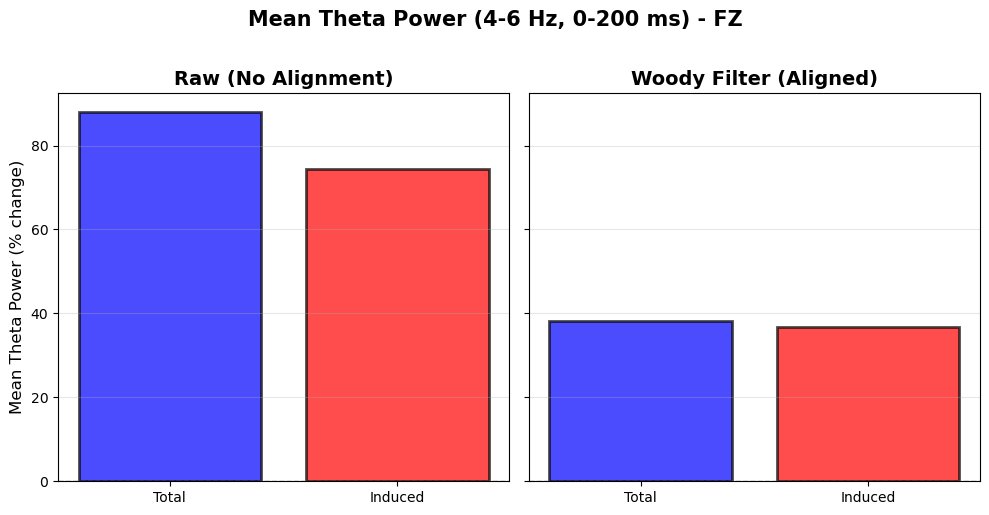

Raw - Total: 88.04%, Induced: 74.51%
Woody - Total: 38.08%, Induced: 36.66%


In [65]:
# Extract theta band (4-6 Hz) and average over 0-200 ms
theta_mask = (freqs >= 4) & (freqs <= 6)
time_mask = (times >= 0) & (times <= 0.20)

# Calculate mean theta power
# From Raw analysis
mean_theta_total_raw = tfr_total_raw_pct[theta_mask, :][:, time_mask].mean()
mean_theta_induced_raw = tfr_induced_raw_pct[theta_mask, :][:, time_mask].mean()

# From Woody analysis  
mean_theta_total_woody = tfr_total_woody_pct[theta_mask, :][:, time_mask].mean()
mean_theta_induced_woody = tfr_induced_woody_pct[theta_mask, :][:, time_mask].mean()

# Plot with shared y-axis
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), sharey=True)

# Raw
conditions_raw = ['Total', 'Induced']
values_raw = [mean_theta_total_raw, mean_theta_induced_raw]
colors_raw = ['blue', 'red']
ax1.bar(conditions_raw, values_raw, color=colors_raw, alpha=0.7, edgecolor='black', linewidth=2)
ax1.axhline(0, color='gray', linestyle='--', linewidth=1)
ax1.set_ylabel('Mean Theta Power (% change)', fontsize=12)
ax1.set_title('Raw (No Alignment)', fontsize=14, fontweight='bold')
ax1.grid(alpha=0.3, axis='y')

# Woody
conditions_woody = ['Total', 'Induced']
values_woody = [mean_theta_total_woody, mean_theta_induced_woody]
colors_woody = ['blue', 'red']
ax2.bar(conditions_woody, values_woody, color=colors_woody, alpha=0.7, edgecolor='black', linewidth=2)
ax2.axhline(0, color='gray', linestyle='--', linewidth=1)
ax2.set_title('Woody Filter (Aligned)', fontsize=14, fontweight='bold')
ax2.grid(alpha=0.3, axis='y')

plt.suptitle(f'Mean Theta Power (4-6 Hz, 0-200 ms) - {channel}', 
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f"Raw - Total: {mean_theta_total_raw:.2f}%, Induced: {mean_theta_induced_raw:.2f}%")
print(f"Woody - Total: {mean_theta_total_woody:.2f}%, Induced: {mean_theta_induced_woody:.2f}%")

Processing subjects: 100%|██████████| 221/221 [01:29<00:00,  2.46it/s]


141 subjects analyzed successfully


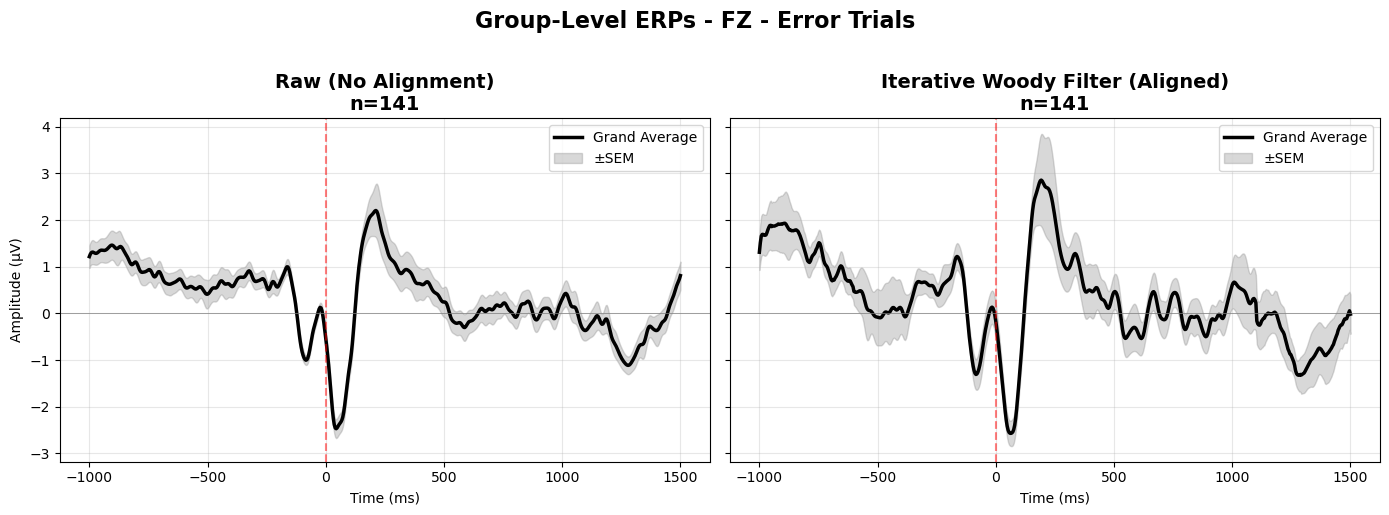

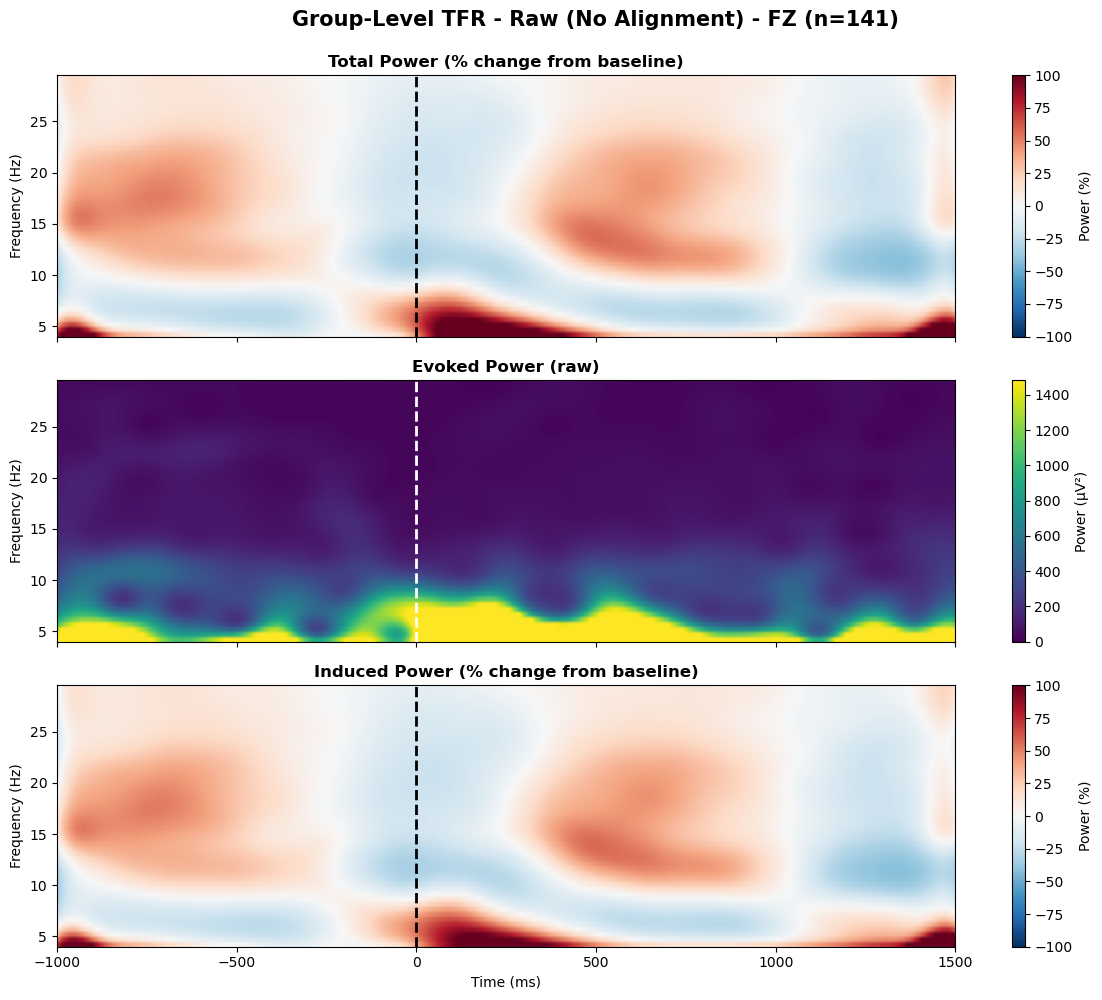

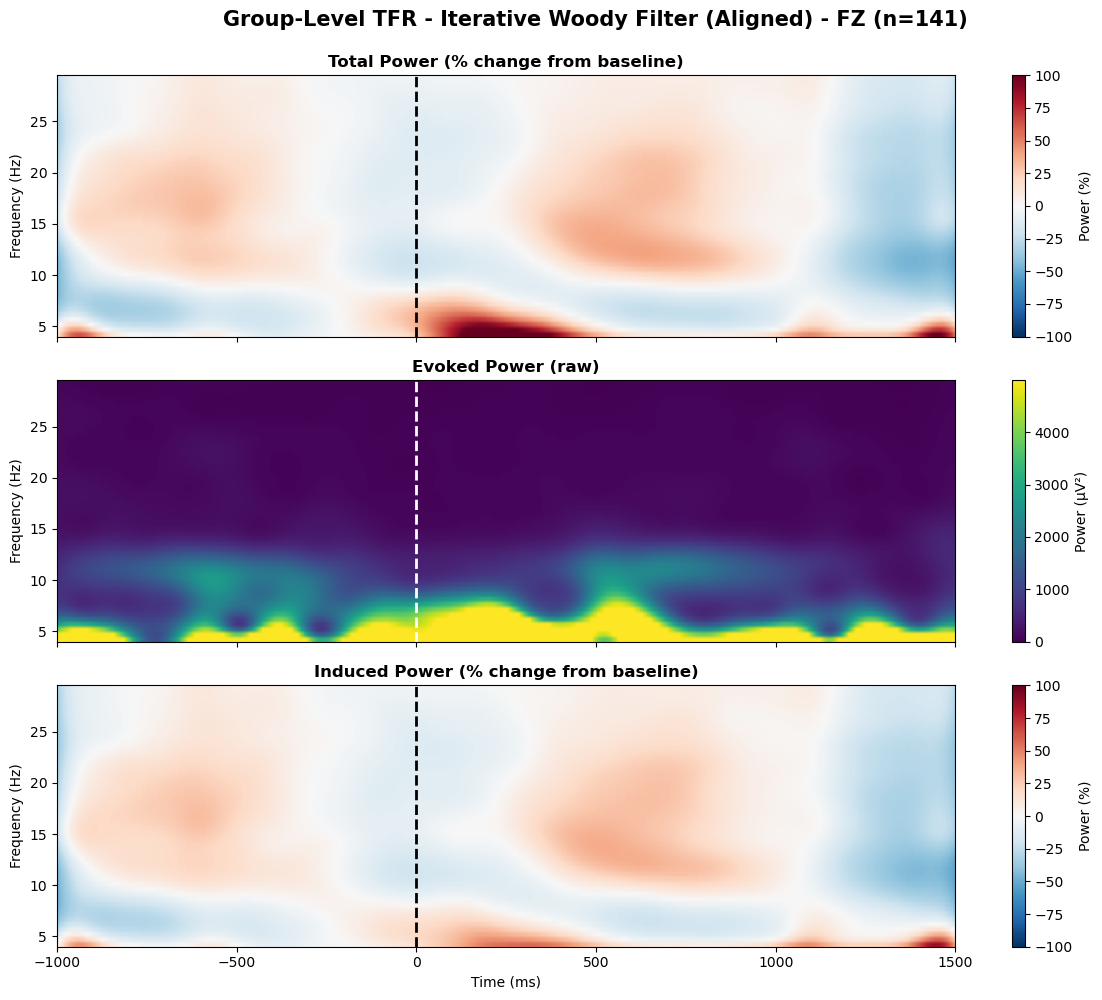

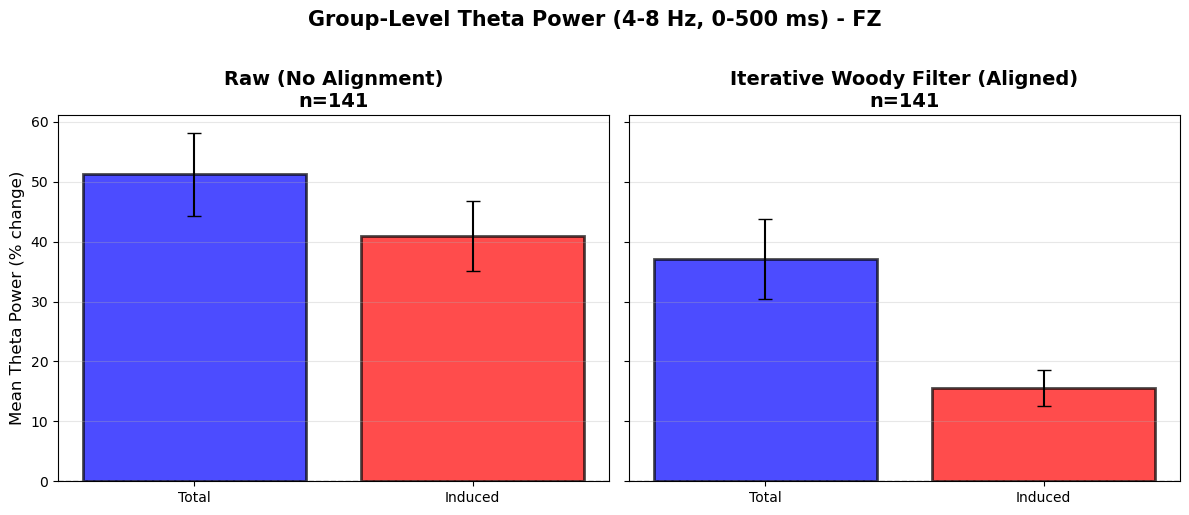


=== SUMMARY STATISTICS ===
Raw - Total: 51.21±6.95%, Induced: 40.97±5.82%
Woody - Total: 37.08±6.74%, Induced: 15.55±2.98%

Results saved to 'theta_analysis_results.csv'


In [7]:
import mne
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import pandas as pd
from pathlib import Path
from tqdm import tqdm
import warnings
from woody_filter import woody

# Suppress warnings
warnings.filterwarnings('ignore')

def analyze_subject(epochs_path, channel='FZ', theta_range=(4, 8), time_window=(0, 0.5)):
    """Analyze one subject: compute Raw and Woody TFR."""
    
    # Load epochs
    epochs = mne.read_epochs(epochs_path, preload=True, verbose=False)
    
    # Extract incorrect trials
    incorrect_codes = ['108', '109', '118', '119', '128', '129', '138', '139']
    epochs_incorrect = epochs[incorrect_codes]
    
    n_trials = len(epochs_incorrect)
    if n_trials < 5:
        return None
    
    # Get data
    data = epochs_incorrect.copy().pick([channel]).get_data()[:, 0, :]
    times = epochs_incorrect.times
    data_uv = data * 1e6
    sfreq = epochs_incorrect.info['sfreq']
    
    # TFR parameters
    freqs = np.arange(4, 30, 0.5)
    n_cycles = freqs / 2.0
    baseline_mask = (times >= -0.5) & (times <= 0)  # -500 to 0 ms baseline
    
    # === RAW ANALYSIS ===
    grand_avg_raw = data_uv.mean(axis=0)
    sd_raw = data_uv.std(axis=0)
    
    # Raw - Total Power
    tfr_total_raw = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(data_uv[trial, :], wavelet, mode='same')
            tfr_total_raw[idx, :] += np.abs(convolved) ** 2
    tfr_total_raw /= n_trials
    
    # Raw - Evoked Power
    tfr_evoked_raw = np.zeros((len(freqs), len(times)))
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(grand_avg_raw, wavelet, mode='same')
        tfr_evoked_raw[idx, :] = np.abs(convolved) ** 2
    
    # Raw - Induced Power
    tfr_induced_raw = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        residual = data_uv[trial, :] - grand_avg_raw
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(residual, wavelet, mode='same')
            tfr_induced_raw[idx, :] += np.abs(convolved) ** 2
    tfr_induced_raw /= n_trials
    
    # Baseline correction
    bl_total_raw = tfr_total_raw[:, baseline_mask].mean(axis=1, keepdims=True)
    bl_induced_raw = tfr_induced_raw[:, baseline_mask].mean(axis=1, keepdims=True)
    tfr_total_raw_pct = ((tfr_total_raw - bl_total_raw) / bl_total_raw) * 100
    tfr_induced_raw_pct = ((tfr_induced_raw - bl_induced_raw) / bl_induced_raw) * 100
    
    # === WOODY ANALYSIS ===
    # Transpose to correct shape: (n_timepoints, n_trials)
    data_T = data_uv.T
    
    # Apply proper iterative Woody filter
    aligned_avg, detected_lags = woody(
        data_T,
        tol=0.1,
        max_it=100,
        est_mthd='woody',
        xcorr_mthd='unbiased',
        max_shift=100
    )
    
    # Reconstruct individual aligned trials
    n_trials_data, n_times = data_uv.shape
    aligned_trials = np.zeros_like(data_uv)
    
    for i in range(n_trials_data):
        lag = detected_lags[i]
        if lag > 0:
            # Positive lag: trial is delayed, shift left
            aligned_trials[i, :] = np.concatenate([data_uv[i, lag:], np.zeros(lag)])
        elif lag < 0:
            # Negative lag: trial is early, shift right
            aligned_trials[i, :] = np.concatenate([np.zeros(-lag), data_uv[i, :lag]])
        else:
            aligned_trials[i, :] = data_uv[i, :]
    
    grand_avg_woody = aligned_trials.mean(axis=0)
    sd_woody = aligned_trials.std(axis=0)
    
    # Woody - Total Power
    tfr_total_woody = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(aligned_trials[trial, :], wavelet, mode='same')
            tfr_total_woody[idx, :] += np.abs(convolved) ** 2
    tfr_total_woody /= n_trials
    
    # Woody - Evoked Power
    tfr_evoked_woody = np.zeros((len(freqs), len(times)))
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(grand_avg_woody, wavelet, mode='same')
        tfr_evoked_woody[idx, :] = np.abs(convolved) ** 2
    
    # Woody - Induced Power
    tfr_induced_woody = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        residual = aligned_trials[trial, :] - grand_avg_woody
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(residual, wavelet, mode='same')
            tfr_induced_woody[idx, :] += np.abs(convolved) ** 2
    tfr_induced_woody /= n_trials
    
    # Baseline correction
    bl_total_woody = tfr_total_woody[:, baseline_mask].mean(axis=1, keepdims=True)
    bl_induced_woody = tfr_induced_woody[:, baseline_mask].mean(axis=1, keepdims=True)
    tfr_total_woody_pct = ((tfr_total_woody - bl_total_woody) / bl_total_woody) * 100
    tfr_induced_woody_pct = ((tfr_induced_woody - bl_induced_woody) / bl_induced_woody) * 100
    
    # === EXTRACT THETA ===
    theta_mask = (freqs >= theta_range[0]) & (freqs <= theta_range[1])
    time_mask = (times >= time_window[0]) & (times <= time_window[1])
    
    results = {
        'n_trials': n_trials,
        'mean_lag': detected_lags.mean(),
        'std_lag': detected_lags.std(),
        'theta_total_raw': tfr_total_raw_pct[theta_mask, :][:, time_mask].mean(),
        'theta_induced_raw': tfr_induced_raw_pct[theta_mask, :][:, time_mask].mean(),
        'theta_total_woody': tfr_total_woody_pct[theta_mask, :][:, time_mask].mean(),
        'theta_induced_woody': tfr_induced_woody_pct[theta_mask, :][:, time_mask].mean(),
        'erp_raw': grand_avg_raw,
        'sd_raw': sd_raw,
        'erp_woody': grand_avg_woody,
        'sd_woody': sd_woody,
        'tfr_total_raw_pct': tfr_total_raw_pct,
        'tfr_evoked_raw': tfr_evoked_raw,
        'tfr_induced_raw_pct': tfr_induced_raw_pct,
        'tfr_total_woody_pct': tfr_total_woody_pct,
        'tfr_evoked_woody': tfr_evoked_woody,
        'tfr_induced_woody_pct': tfr_induced_woody_pct,
        'times': times,
        'freqs': freqs
    }
    
    return results

# === MAIN ANALYSIS ===
subjects = [
    "sub-AH17AR05", "sub-AI09ID16", "sub-AL07NK06", "sub-AL08AS02",
    "sub-AR06AS06", "sub-AR10IO04", "sub-AT06ED25", "sub-AU09GE22",
    "sub-CH04ER19", "sub-CH05NK28", "sub-CH06UT07", "sub-CH07AD15",
    "sub-CH07NK17", "sub-CH07RK18", "sub-CH10NG24", "sub-CK04NS18",
    "sub-CK05EN08", "sub-CK06ED08", "sub-CK06US15", "sub-CK07NK21",
    "sub-DADARE11", "sub-DS08NK08", "sub-DT05AH09", "sub-DT05EV26",
    "sub-DT07ES22", "sub-DTINTZ10", "sub-EA06ER02", "sub-EK05AN14",
    "sub-EK06ER26", "sub-EK07CH24", "sub-EL04AM03", "sub-EL05JO26",
    "sub-EL06EL11", "sub-EL06LD17", "sub-EL06ST21", "sub-EL07EL14",
    "sub-EN04ER01", "sub-EN04ER14", "sub-EN05AN02", "sub-EN05ED14",
    "sub-EN05KT02", "sub-EN05US05", "sub-EN06AN21", "sub-EN08CH27",
    "sub-EP05EN09", "sub-ER03ER09", "sub-ER03LF17", "sub-ER04CH03",
    "sub-ER04ER12", "sub-ER04RT24", "sub-ER04ST03", "sub-ER05AN13",
    "sub-ER05AR27", "sub-ER05AS20", "sub-ER05AV01", "sub-ER05EL09",
    "sub-ER05EL26", "sub-ER05ER07", "sub-ER05IM29", "sub-ER05MA17",
    "sub-ER05NG11", "sub-ER05RI09", "sub-ER05RK06", "sub-ER05RT24",
    "sub-ER06AN07", "sub-ER06AN28", "sub-ER06EF14", "sub-ER06EL06",
    "sub-ER06EN03", "sub-ER06EN27", "sub-ER06ET15", "sub-ER06IM15",
    "sub-ER06IS22", "sub-ER06KR20", "sub-ER06NK09", "sub-ER06US24",
    "sub-ER07AS24", "sub-ER07EF15", "sub-ER07EN04", "sub-ER07ER23",
    "sub-ER07ER30", "sub-ER07ND12", "sub-ER07RL02", "sub-ER08AH23",
    "sub-ER08AS28", "sub-ER08EN05", "sub-ER08ER03", "sub-ER08RT29",
    "sub-ER09DO22", "sub-ER09NK30", "sub-ER09NZ11", "sub-ER10IG12",
    "sub-ES06ER27", "sub-ES06NK11", "sub-EV06AN16", "sub-EZ04SE15",
    "sub-FA04HU23", "sub-FE06AN24", "sub-GA04LI18", "sub-GA06OF10",
    "sub-GY06LO26", "sub-HEERLD19", "sub-HL09AN11", "sub-HR07ED31",
    "sub-IA05NS20", "sub-ID07EN28", "sub-IG06LF01", "sub-IG06NS07",
    "sub-IG06WE03", "sub-IG07RT16", "sub-IK06ET06", "sub-IK09LD05",
    "sub-IN05ED23", "sub-IN06AS14", "sub-IN07ET30", "sub-IR04ET20",
    "sub-IS06RG09", "sub-IT08ND26", "sub-JA06AS11", "sub-JU05IN24",
    "sub-KA04LF11", "sub-KE04NI10", "sub-KE05AN23", "sub-KE06EL16",
    "sub-KE07AN05", "sub-KE07ER04", "sub-KE08AS23", "sub-KI05US17",
    "sub-KN05EN09", "sub-KO07EL16", "sub-LA08RE26", "sub-LE04ON09",
    "sub-LF04AS01", "sub-LF07RT29", "sub-LO06RE10", "sub-LY07EL23",
    "sub-MA06LO21", "sub-ME05NS04", "sub-MI07AH25", "sub-NA04AV25",
    "sub-NA04OV25", "sub-ND05NG06", "sub-ND06EF01", "sub-NE06AS01",
    "sub-NE06AS31", "sub-NE06EL01", "sub-NG03YI17", "sub-NG05AS30",
    "sub-NG06NI21", "sub-NG06UL04", "sub-NG07AN22", "sub-NK06AS24",
    "sub-NK06RG30", "sub-NN04AN24", "sub-NN05AN05", "sub-NN05IR17",
    "sub-NN06TH16", "sub-NN06US23", "sub-NN07EN14", "sub-NN07ID18",
    "sub-NN08AS03", "sub-NN08EL29", "sub-NN08ER22", "sub-NN08LM06",
    "sub-NN09LM18", "sub-NN09NS31", "sub-NO05RT22", "sub-NS05RO15",
    "sub-NS09EL05", "sub-NY04DT26", "sub-NZ04EN16", "sub-NZ09ER04",
    "sub-OH05NK29", "sub-ON05EL22", "sub-ON06US07", "sub-OW07RK26",
    "sub-PP07AS29", "sub-RASUAN07", "sub-RF09EL18", "sub-RG05AS08",
    "sub-RG06AS09", "sub-RG07US04", "sub-RN10AN23", "sub-RS06RS22",
    "sub-RS07LF20", "sub-RT04KE01", "sub-RT05EL10", "sub-RT06AN02",
    "sub-RT07LD06", "sub-RZ05ND19", "sub-SE05EN28", "sub-SE05ZI24",
    "sub-SE06AM29", "sub-SE06NS17", "sub-SS04PH05", "sub-ST03ED03",
    "sub-ST07NK15", "sub-TA03RL11", "sub-TE03AS11", "sub-TE05AS09",
    "sub-TE05NS01", "sub-TE08IO29", "sub-TE10AN12", "sub-TH07AR12",
    "sub-TL08AN16", "sub-TT08NS17", "sub-TZ08US31", "sub-UN07AS25",
    "sub-US05RK06", "sub-US07US10", "sub-US08KE27", "sub-VA03ER17",
    "sub-VA05AS27", "sub-VA05ER28", "sub-VA05OR26", "sub-VA06EY24",
    "sub-VA06NZ29", "sub-VA06OV12", "sub-WA04EJ22", "sub-WA05EJ08",
    "sub-XX04AS28"
]

data_dir = Path("/Users/qmoreau/Documents/Work/flanker_bursts/PreprocessedData/ernpipeline/")

# Analyze all subjects with progress bar
all_results = []
for sub_id in tqdm(subjects, desc="Processing subjects"):
    sub_file = data_dir / sub_id / f"{sub_id}_desc-epochs_eeg.fif"
    
    if not sub_file.exists():
        continue
    
    try:
        results = analyze_subject(sub_file, channel='FZ', theta_range=(4, 8), time_window=(0, 0.5))
        if results is not None:
            results['subject'] = sub_id
            all_results.append(results)
    except:
        continue

print(f"\n{len(all_results)} subjects analyzed successfully")

# === COMPUTE GROUP AVERAGES ===
times = all_results[0]['times']
freqs = all_results[0]['freqs']

erp_raw_all = np.array([r['erp_raw'] for r in all_results])
erp_woody_all = np.array([r['erp_woody'] for r in all_results])
erp_raw_mean = erp_raw_all.mean(axis=0)
erp_raw_sem = erp_raw_all.std(axis=0) / np.sqrt(len(all_results))
erp_woody_mean = erp_woody_all.mean(axis=0)
erp_woody_sem = erp_woody_all.std(axis=0) / np.sqrt(len(all_results))

tfr_total_raw_all = np.array([r['tfr_total_raw_pct'] for r in all_results])
tfr_evoked_raw_all = np.array([r['tfr_evoked_raw'] for r in all_results])
tfr_induced_raw_all = np.array([r['tfr_induced_raw_pct'] for r in all_results])
tfr_total_woody_all = np.array([r['tfr_total_woody_pct'] for r in all_results])
tfr_evoked_woody_all = np.array([r['tfr_evoked_woody'] for r in all_results])
tfr_induced_woody_all = np.array([r['tfr_induced_woody_pct'] for r in all_results])

tfr_total_raw_mean = tfr_total_raw_all.mean(axis=0)
tfr_evoked_raw_mean = tfr_evoked_raw_all.mean(axis=0)
tfr_induced_raw_mean = tfr_induced_raw_all.mean(axis=0)
tfr_total_woody_mean = tfr_total_woody_all.mean(axis=0)
tfr_evoked_woody_mean = tfr_evoked_woody_all.mean(axis=0)
tfr_induced_woody_mean = tfr_induced_woody_all.mean(axis=0)

# === PLOT 1: ERPs ===
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

ax1.plot(times * 1000, erp_raw_mean, 'k', linewidth=2.5, label='Grand Average')
ax1.fill_between(times * 1000, erp_raw_mean - erp_raw_sem, erp_raw_mean + erp_raw_sem,
                  color='gray', alpha=0.3, label='±SEM')
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'Raw (No Alignment)\nn={len(all_results)}', fontsize=14, fontweight='bold')
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(times * 1000, erp_woody_mean, 'k', linewidth=2.5, label='Grand Average')
ax2.fill_between(times * 1000, erp_woody_mean - erp_woody_sem, erp_woody_mean + erp_woody_sem,
                  color='gray', alpha=0.3, label='±SEM')
ax2.axvline(0, color='r', linestyle='--', alpha=0.5)
ax2.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax2.set_xlabel('Time (ms)')
ax2.set_title(f'Iterative Woody Filter (Aligned)\nn={len(all_results)}', fontsize=14, fontweight='bold')
ax2.legend()
ax2.grid(alpha=0.3)

plt.suptitle('Group-Level ERPs - FZ - Error Trials', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# === PLOT 2: TFRs RAW ===
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

im1 = axes[0].imshow(tfr_total_raw_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[0].axvline(0, color='black', linestyle='--', linewidth=2)
axes[0].set_ylabel('Frequency (Hz)')
axes[0].set_title('Total Power (% change from baseline)', fontweight='bold')
plt.colorbar(im1, ax=axes[0], label='Power (%)')

vmax_evoked = np.percentile(tfr_evoked_raw_mean, 95)
im2 = axes[1].imshow(tfr_evoked_raw_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=vmax_evoked, cmap='viridis')
axes[1].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('Evoked Power (raw)', fontweight='bold')
plt.colorbar(im2, ax=axes[1], label='Power (µV²)')

im3 = axes[2].imshow(tfr_induced_raw_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[2].axvline(0, color='black', linestyle='--', linewidth=2)
axes[2].set_xlabel('Time (ms)')
axes[2].set_ylabel('Frequency (Hz)')
axes[2].set_title('Induced Power (% change from baseline)', fontweight='bold')
plt.colorbar(im3, ax=axes[2], label='Power (%)')

plt.suptitle(f'Group-Level TFR - Raw (No Alignment) - FZ (n={len(all_results)})',
             fontsize=15, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

# === PLOT 3: TFRs WOODY ===
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

im1 = axes[0].imshow(tfr_total_woody_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[0].axvline(0, color='black', linestyle='--', linewidth=2)
axes[0].set_ylabel('Frequency (Hz)')
axes[0].set_title('Total Power (% change from baseline)', fontweight='bold')
plt.colorbar(im1, ax=axes[0], label='Power (%)')

vmax_evoked = np.percentile(tfr_evoked_woody_mean, 95)
im2 = axes[1].imshow(tfr_evoked_woody_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=vmax_evoked, cmap='viridis')
axes[1].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('Evoked Power (raw)', fontweight='bold')
plt.colorbar(im2, ax=axes[1], label='Power (µV²)')

im3 = axes[2].imshow(tfr_induced_woody_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[2].axvline(0, color='black', linestyle='--', linewidth=2)
axes[2].set_xlabel('Time (ms)')
axes[2].set_ylabel('Frequency (Hz)')
axes[2].set_title('Induced Power (% change from baseline)', fontweight='bold')
plt.colorbar(im3, ax=axes[2], label='Power (%)')

plt.suptitle(f'Group-Level TFR - Iterative Woody Filter (Aligned) - FZ (n={len(all_results)})',
             fontsize=15, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

# === PLOT 4: THETA BARPLOTS ===
df = pd.DataFrame([{k: v for k, v in r.items() if k not in ['erp_raw', 'sd_raw', 'erp_woody', 'sd_woody',
                                                               'tfr_total_raw_pct', 'tfr_evoked_raw', 'tfr_induced_raw_pct',
                                                               'tfr_total_woody_pct', 'tfr_evoked_woody', 'tfr_induced_woody_pct',
                                                               'times', 'freqs']} for r in all_results])

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

raw_means = [df['theta_total_raw'].mean(), df['theta_induced_raw'].mean()]
raw_sems = [df['theta_total_raw'].sem(), df['theta_induced_raw'].sem()]
x_pos = np.arange(len(raw_means))
axes[0].bar(x_pos, raw_means, yerr=raw_sems, color=['blue', 'red'],
            alpha=0.7, edgecolor='black', linewidth=2, capsize=5)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(['Total', 'Induced'])
axes[0].axhline(0, color='gray', linestyle='--', linewidth=1)
axes[0].set_ylabel('Mean Theta Power (% change)', fontsize=12)
axes[0].set_title(f'Raw (No Alignment)\nn={len(df)}', fontsize=14, fontweight='bold')
axes[0].grid(alpha=0.3, axis='y')

woody_means = [df['theta_total_woody'].mean(), df['theta_induced_woody'].mean()]
woody_sems = [df['theta_total_woody'].sem(), df['theta_induced_woody'].sem()]
axes[1].bar(x_pos, woody_means, yerr=woody_sems, color=['blue', 'red'],
            alpha=0.7, edgecolor='black', linewidth=2, capsize=5)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(['Total', 'Induced'])
axes[1].axhline(0, color='gray', linestyle='--', linewidth=1)
axes[1].set_title(f'Iterative Woody Filter (Aligned)\nn={len(df)}', fontsize=14, fontweight='bold')
axes[1].grid(alpha=0.3, axis='y')

plt.suptitle('Group-Level Theta Power (4-8 Hz, 0-500 ms) - FZ',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n=== SUMMARY STATISTICS ===")
print(f"Raw - Total: {raw_means[0]:.2f}±{raw_sems[0]:.2f}%, Induced: {raw_means[1]:.2f}±{raw_sems[1]:.2f}%")
print(f"Woody - Total: {woody_means[0]:.2f}±{woody_sems[0]:.2f}%, Induced: {woody_means[1]:.2f}±{woody_sems[1]:.2f}%")

df.to_csv('theta_analysis_results.csv', index=False)
print("\nResults saved to 'theta_analysis_results.csv'")

In [ ]:
times_str = df['incong_grand_avg_raw'].iloc[0]
print("First few characters:", times_str[:100])
print("Type:", type(times_str))


First few characters: [3.74374191 3.69821095 3.51430073 ... 4.37961826 4.41411206 4.37617885]
Type: <class 'str'>


Processing subjects: 100%|██████████| 221/221 [05:27<00:00,  1.48s/it]


142 subjects analyzed successfully


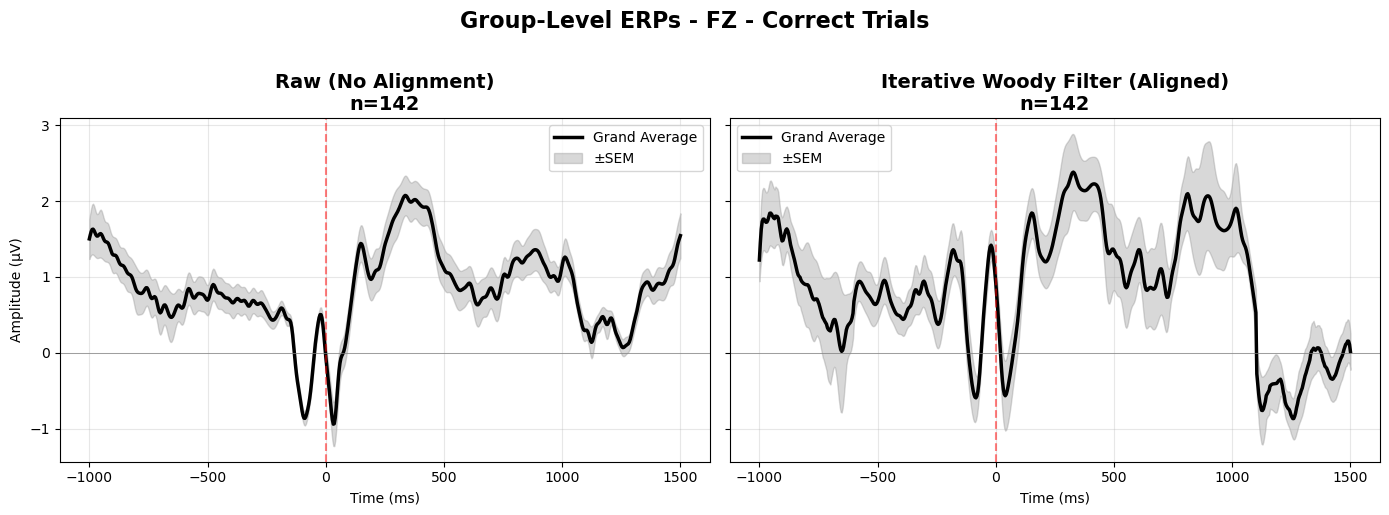

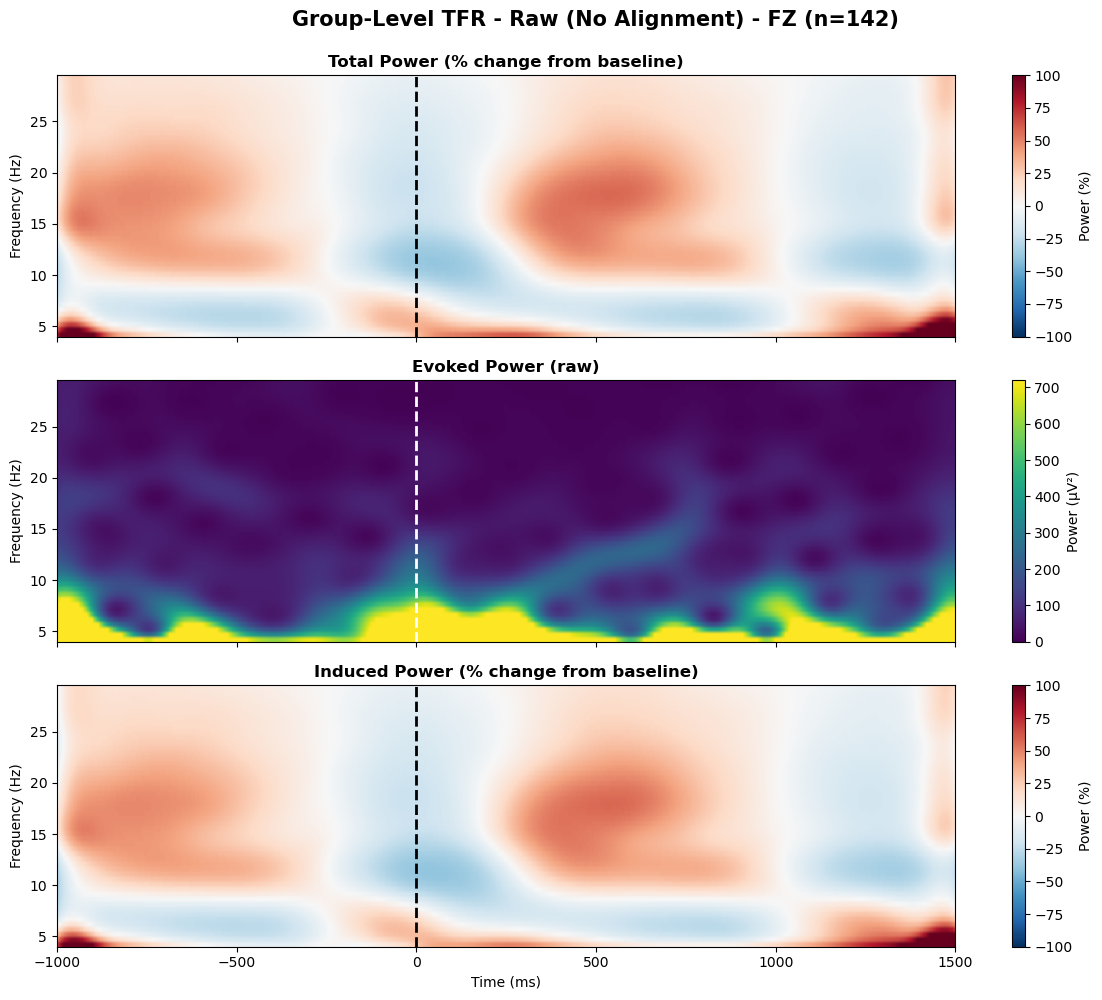

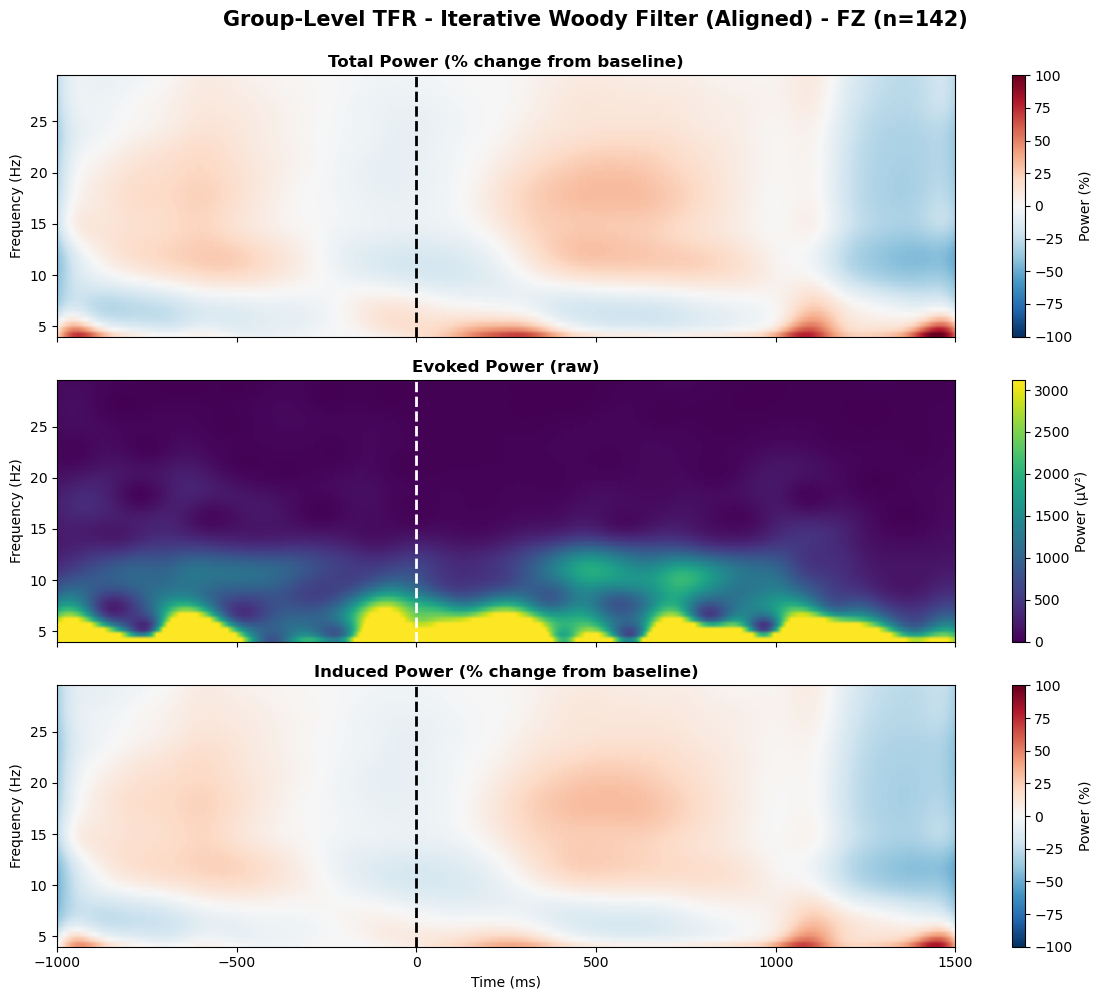

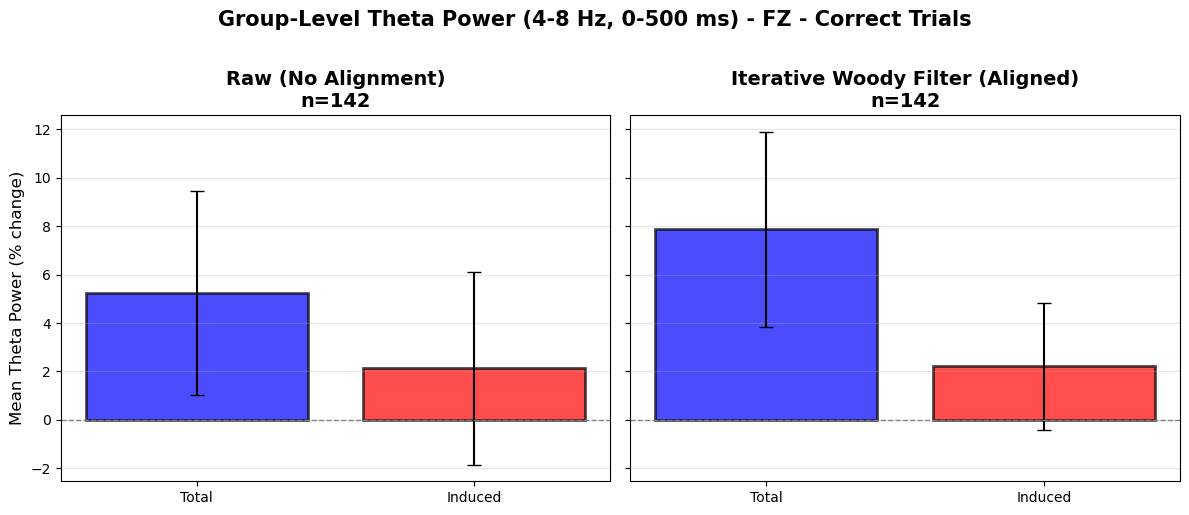


=== SUMMARY STATISTICS ===
Raw - Total: 5.24±4.22%, Induced: 2.13±3.98%
Woody - Total: 7.86±4.02%, Induced: 2.21±2.64%

Results saved to 'theta_analysis_correct.csv'


In [ ]:
# Suppress warnings
warnings.filterwarnings('ignore')
from woody_filter import woody

def analyze_subject(epochs_path, channel='FZ', theta_range=(4, 8), time_window=(0, 0.5)):
    """Analyze one subject: compute Raw and Woody TFR."""
    
    # Load epochs
    epochs = mne.read_epochs(epochs_path, preload=True, verbose=False)
    
    # Extract correct trials
    correct_codes = ['106', '107', '116', '117', '126', '127', '136', '137']
    epochs_correct = epochs[correct_codes]
    
    n_trials = len(epochs_correct)
    if n_trials < 5:
        return None
    
    # Get data
    data = epochs_correct.copy().pick([channel]).get_data()[:, 0, :]
    times = epochs_correct.times
    data_uv = data * 1e6
    sfreq = epochs_correct.info['sfreq']
    
    # TFR parameters
    freqs = np.arange(, 30, 0.5)
    n_cycles = freqs / 2.0
    baseline_mask = (times >= -0.5) & (times <= 0)  # -500 to 0 ms baseline
    
    # === RAW ANALYSIS ===
    grand_avg_raw = data_uv.mean(axis=0)
    sd_raw = data_uv.std(axis=0)
    
    # Raw - Total Power
    tfr_total_raw = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(data_uv[trial, :], wavelet, mode='same')
            tfr_total_raw[idx, :] += np.abs(convolved) ** 2
    tfr_total_raw /= n_trials
    
    # Raw - Evoked Power
    tfr_evoked_raw = np.zeros((len(freqs), len(times)))
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(grand_avg_raw, wavelet, mode='same')
        tfr_evoked_raw[idx, :] = np.abs(convolved) ** 2
    
    # Raw - Induced Power
    tfr_induced_raw = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        residual = data_uv[trial, :] - grand_avg_raw
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(residual, wavelet, mode='same')
            tfr_induced_raw[idx, :] += np.abs(convolved) ** 2
    tfr_induced_raw /= n_trials
    
    # Baseline correction
    bl_total_raw = tfr_total_raw[:, baseline_mask].mean(axis=1, keepdims=True)
    bl_induced_raw = tfr_induced_raw[:, baseline_mask].mean(axis=1, keepdims=True)
    tfr_total_raw_pct = ((tfr_total_raw - bl_total_raw) / bl_total_raw) * 100
    tfr_induced_raw_pct = ((tfr_induced_raw - bl_induced_raw) / bl_induced_raw) * 100
    
    # === WOODY ANALYSIS ===
    # Transpose to correct shape: (n_timepoints, n_trials)
    data_T = data_uv.T
    
    # Apply proper iterative Woody filter
    aligned_avg, detected_lags = woody(
        data_T,
        tol=0.1,
        max_it=100,
        est_mthd='woody',
        xcorr_mthd='unbiased',
        max_shift=100
    )
    
    # Reconstruct individual aligned trials
    n_trials_data, n_times = data_uv.shape
    aligned_trials = np.zeros_like(data_uv)
    
    for i in range(n_trials_data):
        lag = detected_lags[i]
        if lag > 0:
            # Positive lag: trial is delayed, shift left
            aligned_trials[i, :] = np.concatenate([data_uv[i, lag:], np.zeros(lag)])
        elif lag < 0:
            # Negative lag: trial is early, shift right
            aligned_trials[i, :] = np.concatenate([np.zeros(-lag), data_uv[i, :lag]])
        else:
            aligned_trials[i, :] = data_uv[i, :]
    
    grand_avg_woody = aligned_trials.mean(axis=0)
    sd_woody = aligned_trials.std(axis=0)
    
    # Woody - Total Power
    tfr_total_woody = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(aligned_trials[trial, :], wavelet, mode='same')
            tfr_total_woody[idx, :] += np.abs(convolved) ** 2
    tfr_total_woody /= n_trials
    
    # Woody - Evoked Power
    tfr_evoked_woody = np.zeros((len(freqs), len(times)))
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(grand_avg_woody, wavelet, mode='same')
        tfr_evoked_woody[idx, :] = np.abs(convolved) ** 2
    
    # Woody - Induced Power
    tfr_induced_woody = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        residual = aligned_trials[trial, :] - grand_avg_woody
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(residual, wavelet, mode='same')
            tfr_induced_woody[idx, :] += np.abs(convolved) ** 2
    tfr_induced_woody /= n_trials
    
    # Baseline correction
    bl_total_woody = tfr_total_woody[:, baseline_mask].mean(axis=1, keepdims=True)
    bl_induced_woody = tfr_induced_woody[:, baseline_mask].mean(axis=1, keepdims=True)
    tfr_total_woody_pct = ((tfr_total_woody - bl_total_woody) / bl_total_woody) * 100
    tfr_induced_woody_pct = ((tfr_induced_woody - bl_induced_woody) / bl_induced_woody) * 100
    
    # === EXTRACT THETA ===
    theta_mask = (freqs >= theta_range[0]) & (freqs <= theta_range[1])
    time_mask = (times >= time_window[0]) & (times <= time_window[1])
    
    results = {
        'n_trials': n_trials,
        'mean_lag': detected_lags.mean(),
        'std_lag': detected_lags.std(),
        'theta_total_raw': tfr_total_raw_pct[theta_mask, :][:, time_mask].mean(),
        'theta_induced_raw': tfr_induced_raw_pct[theta_mask, :][:, time_mask].mean(),
        'theta_total_woody': tfr_total_woody_pct[theta_mask, :][:, time_mask].mean(),
        'theta_induced_woody': tfr_induced_woody_pct[theta_mask, :][:, time_mask].mean(),
        'erp_raw': grand_avg_raw,
        'sd_raw': sd_raw,
        'erp_woody': grand_avg_woody,
        'sd_woody': sd_woody,
        'tfr_total_raw_pct': tfr_total_raw_pct,
        'tfr_evoked_raw': tfr_evoked_raw,
        'tfr_induced_raw_pct': tfr_induced_raw_pct,
        'tfr_total_woody_pct': tfr_total_woody_pct,
        'tfr_evoked_woody': tfr_evoked_woody,
        'tfr_induced_woody_pct': tfr_induced_woody_pct,
        'times': times,
        'freqs': freqs
    }
    
    return results

# === MAIN ANALYSIS ===
subjects = [
    "sub-AH17AR05", "sub-AI09ID16", "sub-AL07NK06", "sub-AL08AS02",
    "sub-AR06AS06", "sub-AR10IO04", "sub-AT06ED25", "sub-AU09GE22",
    "sub-CH04ER19", "sub-CH05NK28", "sub-CH06UT07", "sub-CH07AD15",
    "sub-CH07NK17", "sub-CH07RK18", "sub-CH10NG24", "sub-CK04NS18",
    "sub-CK05EN08", "sub-CK06ED08", "sub-CK06US15", "sub-CK07NK21",
    "sub-DADARE11", "sub-DS08NK08", "sub-DT05AH09", "sub-DT05EV26",
    "sub-DT07ES22", "sub-DTINTZ10", "sub-EA06ER02", "sub-EK05AN14",
    "sub-EK06ER26", "sub-EK07CH24", "sub-EL04AM03", "sub-EL05JO26",
    "sub-EL06EL11", "sub-EL06LD17", "sub-EL06ST21", "sub-EL07EL14",
    "sub-EN04ER01", "sub-EN04ER14", "sub-EN05AN02", "sub-EN05ED14",
    "sub-EN05KT02", "sub-EN05US05", "sub-EN06AN21", "sub-EN08CH27",
    "sub-EP05EN09", "sub-ER03ER09", "sub-ER03LF17", "sub-ER04CH03",
    "sub-ER04ER12", "sub-ER04RT24", "sub-ER04ST03", "sub-ER05AN13",
    "sub-ER05AR27", "sub-ER05AS20", "sub-ER05AV01", "sub-ER05EL09",
    "sub-ER05EL26", "sub-ER05ER07", "sub-ER05IM29", "sub-ER05MA17",
    "sub-ER05NG11", "sub-ER05RI09", "sub-ER05RK06", "sub-ER05RT24",
    "sub-ER06AN07", "sub-ER06AN28", "sub-ER06EF14", "sub-ER06EL06",
    "sub-ER06EN03", "sub-ER06EN27", "sub-ER06ET15", "sub-ER06IM15",
    "sub-ER06IS22", "sub-ER06KR20", "sub-ER06NK09", "sub-ER06US24",
    "sub-ER07AS24", "sub-ER07EF15", "sub-ER07EN04", "sub-ER07ER23",
    "sub-ER07ER30", "sub-ER07ND12", "sub-ER07RL02", "sub-ER08AH23",
    "sub-ER08AS28", "sub-ER08EN05", "sub-ER08ER03", "sub-ER08RT29",
    "sub-ER09DO22", "sub-ER09NK30", "sub-ER09NZ11", "sub-ER10IG12",
    "sub-ES06ER27", "sub-ES06NK11", "sub-EV06AN16", "sub-EZ04SE15",
    "sub-FA04HU23", "sub-FE06AN24", "sub-GA04LI18", "sub-GA06OF10",
    "sub-GY06LO26", "sub-HEERLD19", "sub-HL09AN11", "sub-HR07ED31",
    "sub-IA05NS20", "sub-ID07EN28", "sub-IG06LF01", "sub-IG06NS07",
    "sub-IG06WE03", "sub-IG07RT16", "sub-IK06ET06", "sub-IK09LD05",
    "sub-IN05ED23", "sub-IN06AS14", "sub-IN07ET30", "sub-IR04ET20",
    "sub-IS06RG09", "sub-IT08ND26", "sub-JA06AS11", "sub-JU05IN24",
    "sub-KA04LF11", "sub-KE04NI10", "sub-KE05AN23", "sub-KE06EL16",
    "sub-KE07AN05", "sub-KE07ER04", "sub-KE08AS23", "sub-KI05US17",
    "sub-KN05EN09", "sub-KO07EL16", "sub-LA08RE26", "sub-LE04ON09",
    "sub-LF04AS01", "sub-LF07RT29", "sub-LO06RE10", "sub-LY07EL23",
    "sub-MA06LO21", "sub-ME05NS04", "sub-MI07AH25", "sub-NA04AV25",
    "sub-NA04OV25", "sub-ND05NG06", "sub-ND06EF01", "sub-NE06AS01",
    "sub-NE06AS31", "sub-NE06EL01", "sub-NG03YI17", "sub-NG05AS30",
    "sub-NG06NI21", "sub-NG06UL04", "sub-NG07AN22", "sub-NK06AS24",
    "sub-NK06RG30", "sub-NN04AN24", "sub-NN05AN05", "sub-NN05IR17",
    "sub-NN06TH16", "sub-NN06US23", "sub-NN07EN14", "sub-NN07ID18",
    "sub-NN08AS03", "sub-NN08EL29", "sub-NN08ER22", "sub-NN08LM06",
    "sub-NN09LM18", "sub-NN09NS31", "sub-NO05RT22", "sub-NS05RO15",
    "sub-NS09EL05", "sub-NY04DT26", "sub-NZ04EN16", "sub-NZ09ER04",
    "sub-OH05NK29", "sub-ON05EL22", "sub-ON06US07", "sub-OW07RK26",
    "sub-PP07AS29", "sub-RASUAN07", "sub-RF09EL18", "sub-RG05AS08",
    "sub-RG06AS09", "sub-RG07US04", "sub-RN10AN23", "sub-RS06RS22",
    "sub-RS07LF20", "sub-RT04KE01", "sub-RT05EL10", "sub-RT06AN02",
    "sub-RT07LD06", "sub-RZ05ND19", "sub-SE05EN28", "sub-SE05ZI24",
    "sub-SE06AM29", "sub-SE06NS17", "sub-SS04PH05", "sub-ST03ED03",
    "sub-ST07NK15", "sub-TA03RL11", "sub-TE03AS11", "sub-TE05AS09",
    "sub-TE05NS01", "sub-TE08IO29", "sub-TE10AN12", "sub-TH07AR12",
    "sub-TL08AN16", "sub-TT08NS17", "sub-TZ08US31", "sub-UN07AS25",
    "sub-US05RK06", "sub-US07US10", "sub-US08KE27", "sub-VA03ER17",
    "sub-VA05AS27", "sub-VA05ER28", "sub-VA05OR26", "sub-VA06EY24",
    "sub-VA06NZ29", "sub-VA06OV12", "sub-WA04EJ22", "sub-WA05EJ08",
    "sub-XX04AS28"
]

data_dir = Path("/Users/qmoreau/Documents/Work/flanker_bursts/PreprocessedData/ernpipeline/")

# Analyze all subjects with progress bar
all_results = []
for sub_id in tqdm(subjects, desc="Processing subjects"):
    sub_file = data_dir / sub_id / f"{sub_id}_desc-epochs_eeg.fif"
    
    if not sub_file.exists():
        continue
    
    try:
        results = analyze_subject(sub_file, channel='FZ', theta_range=(4, 8), time_window=(0, 0.5))
        if results is not None:
            results['subject'] = sub_id
            all_results.append(results)
    except:
        continue

print(f"\n{len(all_results)} subjects analyzed successfully")

# === COMPUTE GROUP AVERAGES ===
times = all_results[0]['times']
freqs = all_results[0]['freqs']

erp_raw_all = np.array([r['erp_raw'] for r in all_results])
erp_woody_all = np.array([r['erp_woody'] for r in all_results])
erp_raw_mean = erp_raw_all.mean(axis=0)
erp_raw_sem = erp_raw_all.std(axis=0) / np.sqrt(len(all_results))
erp_woody_mean = erp_woody_all.mean(axis=0)
erp_woody_sem = erp_woody_all.std(axis=0) / np.sqrt(len(all_results))

tfr_total_raw_all = np.array([r['tfr_total_raw_pct'] for r in all_results])
tfr_evoked_raw_all = np.array([r['tfr_evoked_raw'] for r in all_results])
tfr_induced_raw_all = np.array([r['tfr_induced_raw_pct'] for r in all_results])
tfr_total_woody_all = np.array([r['tfr_total_woody_pct'] for r in all_results])
tfr_evoked_woody_all = np.array([r['tfr_evoked_woody'] for r in all_results])
tfr_induced_woody_all = np.array([r['tfr_induced_woody_pct'] for r in all_results])

tfr_total_raw_mean = tfr_total_raw_all.mean(axis=0)
tfr_evoked_raw_mean = tfr_evoked_raw_all.mean(axis=0)
tfr_induced_raw_mean = tfr_induced_raw_all.mean(axis=0)
tfr_total_woody_mean = tfr_total_woody_all.mean(axis=0)
tfr_evoked_woody_mean = tfr_evoked_woody_all.mean(axis=0)
tfr_induced_woody_mean = tfr_induced_woody_all.mean(axis=0)

# === PLOT 1: ERPs ===
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

ax1.plot(times * 1000, erp_raw_mean, 'k', linewidth=2.5, label='Grand Average')
ax1.fill_between(times * 1000, erp_raw_mean - erp_raw_sem, erp_raw_mean + erp_raw_sem,
                  color='gray', alpha=0.3, label='±SEM')
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'Raw (No Alignment)\nn={len(all_results)}', fontsize=14, fontweight='bold')
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(times * 1000, erp_woody_mean, 'k', linewidth=2.5, label='Grand Average')
ax2.fill_between(times * 1000, erp_woody_mean - erp_woody_sem, erp_woody_mean + erp_woody_sem,
                  color='gray', alpha=0.3, label='±SEM')
ax2.axvline(0, color='r', linestyle='--', alpha=0.5)
ax2.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax2.set_xlabel('Time (ms)')
ax2.set_title(f'Iterative Woody Filter (Aligned)\nn={len(all_results)}', fontsize=14, fontweight='bold')
ax2.legend()
ax2.grid(alpha=0.3)

plt.suptitle('Group-Level ERPs - FZ - Correct Trials', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# === PLOT 2: TFRs RAW ===
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

im1 = axes[0].imshow(tfr_total_raw_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[0].axvline(0, color='black', linestyle='--', linewidth=2)
axes[0].set_ylabel('Frequency (Hz)')
axes[0].set_title('Total Power (% change from baseline)', fontweight='bold')
plt.colorbar(im1, ax=axes[0], label='Power (%)')

vmax_evoked = np.percentile(tfr_evoked_raw_mean, 95)
im2 = axes[1].imshow(tfr_evoked_raw_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=vmax_evoked, cmap='viridis')
axes[1].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('Evoked Power (raw)', fontweight='bold')
plt.colorbar(im2, ax=axes[1], label='Power (µV²)')

im3 = axes[2].imshow(tfr_induced_raw_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[2].axvline(0, color='black', linestyle='--', linewidth=2)
axes[2].set_xlabel('Time (ms)')
axes[2].set_ylabel('Frequency (Hz)')
axes[2].set_title('Induced Power (% change from baseline)', fontweight='bold')
plt.colorbar(im3, ax=axes[2], label='Power (%)')

plt.suptitle(f'Group-Level TFR - Raw (No Alignment) - FZ (n={len(all_results)})',
             fontsize=15, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

# === PLOT 3: TFRs WOODY ===
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

im1 = axes[0].imshow(tfr_total_woody_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[0].axvline(0, color='black', linestyle='--', linewidth=2)
axes[0].set_ylabel('Frequency (Hz)')
axes[0].set_title('Total Power (% change from baseline)', fontweight='bold')
plt.colorbar(im1, ax=axes[0], label='Power (%)')

vmax_evoked = np.percentile(tfr_evoked_woody_mean, 95)
im2 = axes[1].imshow(tfr_evoked_woody_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=vmax_evoked, cmap='viridis')
axes[1].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('Evoked Power (raw)', fontweight='bold')
plt.colorbar(im2, ax=axes[1], label='Power (µV²)')

im3 = axes[2].imshow(tfr_induced_woody_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[2].axvline(0, color='black', linestyle='--', linewidth=2)
axes[2].set_xlabel('Time (ms)')
axes[2].set_ylabel('Frequency (Hz)')
axes[2].set_title('Induced Power (% change from baseline)', fontweight='bold')
plt.colorbar(im3, ax=axes[2], label='Power (%)')

plt.suptitle(f'Group-Level TFR - Iterative Woody Filter (Aligned) - FZ (n={len(all_results)})',
             fontsize=15, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

# === PLOT 4: THETA BARPLOTS ===
df = pd.DataFrame([{k: v for k, v in r.items() if k not in ['erp_raw', 'sd_raw', 'erp_woody', 'sd_woody',
                                                               'tfr_total_raw_pct', 'tfr_evoked_raw', 'tfr_induced_raw_pct',
                                                               'tfr_total_woody_pct', 'tfr_evoked_woody', 'tfr_induced_woody_pct',
                                                               'times', 'freqs']} for r in all_results])

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

raw_means = [df['theta_total_raw'].mean(), df['theta_induced_raw'].mean()]
raw_sems = [df['theta_total_raw'].sem(), df['theta_induced_raw'].sem()]
x_pos = np.arange(len(raw_means))
axes[0].bar(x_pos, raw_means, yerr=raw_sems, color=['blue', 'red'],
            alpha=0.7, edgecolor='black', linewidth=2, capsize=5)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(['Total', 'Induced'])
axes[0].axhline(0, color='gray', linestyle='--', linewidth=1)
axes[0].set_ylabel('Mean Theta Power (% change)', fontsize=12)
axes[0].set_title(f'Raw (No Alignment)\nn={len(df)}', fontsize=14, fontweight='bold')
axes[0].grid(alpha=0.3, axis='y')

woody_means = [df['theta_total_woody'].mean(), df['theta_induced_woody'].mean()]
woody_sems = [df['theta_total_woody'].sem(), df['theta_induced_woody'].sem()]
axes[1].bar(x_pos, woody_means, yerr=woody_sems, color=['blue', 'red'],
            alpha=0.7, edgecolor='black', linewidth=2, capsize=5)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(['Total', 'Induced'])
axes[1].axhline(0, color='gray', linestyle='--', linewidth=1)
axes[1].set_title(f'Iterative Woody Filter (Aligned)\nn={len(df)}', fontsize=14, fontweight='bold')
axes[1].grid(alpha=0.3, axis='y')

plt.suptitle('Group-Level Theta Power (4-8 Hz, 0-500 ms) - FZ - Correct Trials',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n=== SUMMARY STATISTICS ===")
print(f"Raw - Total: {raw_means[0]:.2f}±{raw_sems[0]:.2f}%, Induced: {raw_means[1]:.2f}±{raw_sems[1]:.2f}%")
print(f"Woody - Total: {woody_means[0]:.2f}±{woody_sems[0]:.2f}%, Induced: {woody_means[1]:.2f}±{woody_sems[1]:.2f}%")

df.to_csv('theta_analysis_correct.csv', index=False)
print("\nResults saved to 'theta_analysis_correct.csv'")

Matched subjects: 141

=== PAIRED T-TEST RESULTS ===

Raw (No Alignment):
  Error:   M = 40.97, SD = 69.13
  Correct: M = 2.59, SD = 47.26
  t(140) = 11.616, p = 0.0000, d = 0.978

Woody Filter (Aligned):
  Error:   M = 15.55, SD = 35.35
  Correct: M = 2.46, SD = 31.37
  t(140) = 6.120, p = 0.0000, d = 0.515


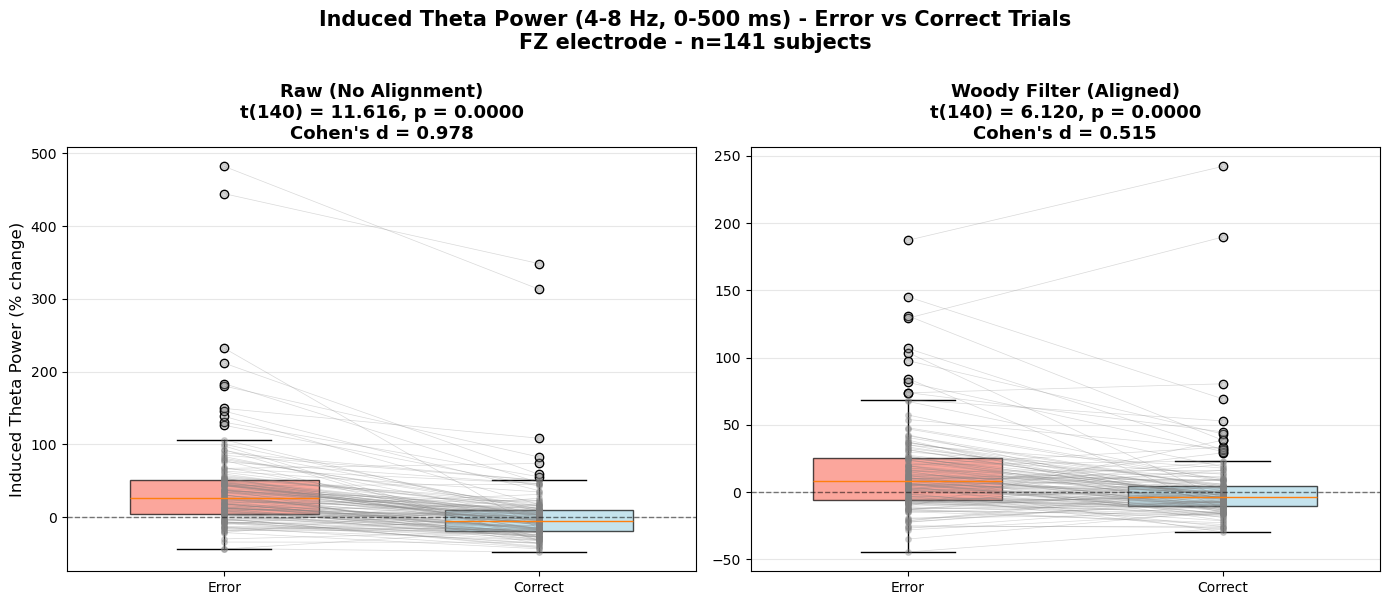

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

# Load results from both analyses
df_error = pd.read_csv('theta_analysis_results.csv')
df_correct = pd.read_csv('theta_analysis_correct.csv')

# Merge datasets on subject ID to ensure matched pairs
df_merged = pd.merge(df_error[['subject', 'theta_induced_raw', 'theta_induced_woody']], 
                     df_correct[['subject', 'theta_induced_raw', 'theta_induced_woody']], 
                     on='subject', 
                     suffixes=('_error', '_correct'))

print(f"Matched subjects: {len(df_merged)}")

# Perform paired t-tests
# Raw (no alignment)
t_raw, p_raw = stats.ttest_rel(df_merged['theta_induced_raw_error'], 
                                df_merged['theta_induced_raw_correct'])

# Woody filtered
t_woody, p_woody = stats.ttest_rel(df_merged['theta_induced_woody_error'], 
                                    df_merged['theta_induced_woody_correct'])

# Calculate effect sizes (Cohen's d for paired samples)
def cohens_d_paired(x, y):
    diff = x - y
    return diff.mean() / diff.std()

d_raw = cohens_d_paired(df_merged['theta_induced_raw_error'], 
                        df_merged['theta_induced_raw_correct'])
d_woody = cohens_d_paired(df_merged['theta_induced_woody_error'], 
                          df_merged['theta_induced_woody_correct'])

# Print statistics
print("\n=== PAIRED T-TEST RESULTS ===")
print(f"\nRaw (No Alignment):")
print(f"  Error:   M = {df_merged['theta_induced_raw_error'].mean():.2f}, SD = {df_merged['theta_induced_raw_error'].std():.2f}")
print(f"  Correct: M = {df_merged['theta_induced_raw_correct'].mean():.2f}, SD = {df_merged['theta_induced_raw_correct'].std():.2f}")
print(f"  t({len(df_merged)-1}) = {t_raw:.3f}, p = {p_raw:.4f}, d = {d_raw:.3f}")

print(f"\nWoody Filter (Aligned):")
print(f"  Error:   M = {df_merged['theta_induced_woody_error'].mean():.2f}, SD = {df_merged['theta_induced_woody_error'].std():.2f}")
print(f"  Correct: M = {df_merged['theta_induced_woody_correct'].mean():.2f}, SD = {df_merged['theta_induced_woody_correct'].std():.2f}")
print(f"  t({len(df_merged)-1}) = {t_woody:.3f}, p = {p_woody:.4f}, d = {d_woody:.3f}")

# Create visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Prepare data for boxplots
data_raw = [df_merged['theta_induced_raw_error'], df_merged['theta_induced_raw_correct']]
data_woody = [df_merged['theta_induced_woody_error'], df_merged['theta_induced_woody_correct']]

# Raw boxplot
bp1 = axes[0].boxplot(data_raw, labels=['Error', 'Correct'], patch_artist=True,
                      widths=0.6, showfliers=True)
for patch, color in zip(bp1['boxes'], ['salmon', 'lightblue']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

# Add individual points with connecting lines
for i in range(len(df_merged)):
    axes[0].plot([1, 2], 
                [df_merged['theta_induced_raw_error'].iloc[i], 
                 df_merged['theta_induced_raw_correct'].iloc[i]], 
                'o-', color='gray', alpha=0.3, markersize=4, linewidth=0.5)

axes[0].set_ylabel('Induced Theta Power (% change)', fontsize=12)
axes[0].set_title(f'Raw (No Alignment)\nt({len(df_merged)-1}) = {t_raw:.3f}, p = {p_raw:.4f}\nCohen\'s d = {d_raw:.3f}', 
                 fontsize=13, fontweight='bold')
axes[0].grid(alpha=0.3, axis='y')
axes[0].axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.5)

# Woody boxplot
bp2 = axes[1].boxplot(data_woody, labels=['Error', 'Correct'], patch_artist=True,
                      widths=0.6, showfliers=True)
for patch, color in zip(bp2['boxes'], ['salmon', 'lightblue']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

# Add individual points with connecting lines
for i in range(len(df_merged)):
    axes[1].plot([1, 2], 
                [df_merged['theta_induced_woody_error'].iloc[i], 
                 df_merged['theta_induced_woody_correct'].iloc[i]], 
                'o-', color='gray', alpha=0.3, markersize=4, linewidth=0.5)

axes[1].set_title(f'Woody Filter (Aligned)\nt({len(df_merged)-1}) = {t_woody:.3f}, p = {p_woody:.4f}\nCohen\'s d = {d_woody:.3f}', 
                 fontsize=13, fontweight='bold')
axes[1].grid(alpha=0.3, axis='y')
axes[1].axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.5)

plt.suptitle(f'Induced Theta Power (4-8 Hz, 0-500 ms) - Error vs Correct Trials\nFZ electrode - n={len(df_merged)} subjects', 
             fontsize=15, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()


In [10]:
import sys
sys.path.append('/Users/qmoreau/Documents/ERN_sim/lagged_hilbert_autocoherence/python')

from lagged_autocoherence import lagged_hilbert_autocoherence


Reading /Users/qmoreau/Documents/ERN_sim/ernpipeline/sub-AU09GE22/sub-AU09GE22_desc-epochs_eeg.fif ...
    Found the data of interest:
        t =   -5000.00 ...    5000.00 ms
        0 CTF compensation matrices available
Not setting metadata
228 matching events found
No baseline correction applied
0 projection items activated
Number of error trials: 60
Data shape: (60, 2501)
Time range: -5000 to 5000 ms

✓ Computed raw induced (trials - grand avg)
✓ Computed Woody induced (aligned trials - aligned grand avg)
  Mean lag: -20.6 ms

Computing autocoherence on induced signals...
  Frequencies: 4-29 Hz
  Lags: 0.5-4.75 cycles

  Computing raw induced autocoherence...
    ✓ Done! Shape: (60, 26, 18)
  Computing Woody induced autocoherence...
    ✓ Done! Shape: (60, 26, 18)


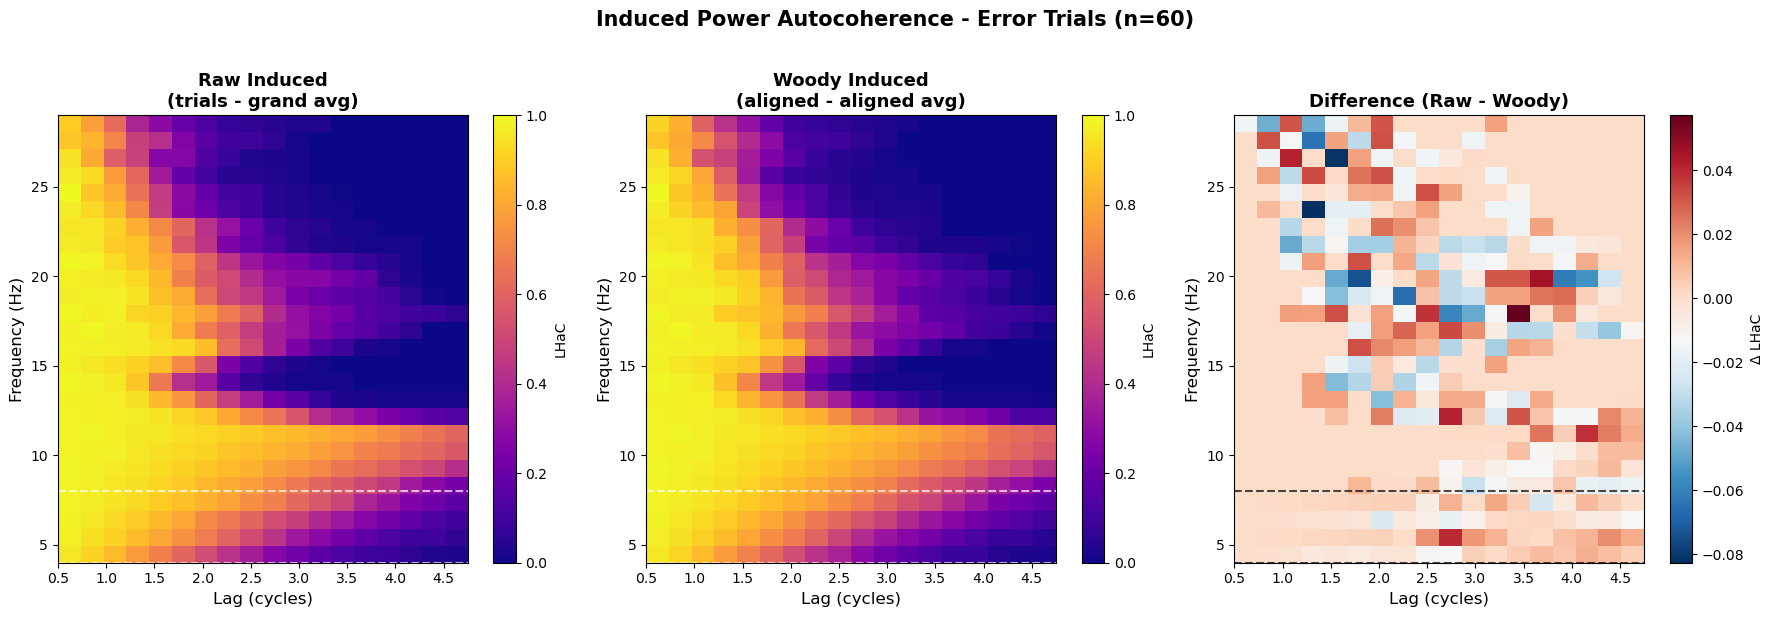


INDUCED THETA INTERPRETATION:
Raw induced:   0.558
Woody induced: 0.558
Reduction:     -0.0%


In [ ]:
from scipy import signal

example_data = "/Users/qmoreau/Documents/ERN_sim/ernpipeline/sub-AU09GE22/sub-AU09GE22_desc-epochs_eeg.fif"
# load epochs

epochs = mne.read_epochs(example_data, preload=True)

incorrect_codes = ['108', '109', '118', '119', '128', '129', '138', '139']
epochs_incorrect = epochs[incorrect_codes]

print(f"Number of error trials: {len(epochs_incorrect)}")

channel = 'FZ'

# Get data: trials x times
data = epochs_incorrect.copy().pick([channel]).get_data()[:, 0, :]  # (n_trials, n_times)
times = epochs_incorrect.times
grand_avg = data.mean(axis=0)

# Convert to microvolts
data_uv = data * 1e6


# Let's work with the full window
time_mask = (times >= -5) & (times <= 5)
data_test = data_uv[:, time_mask]
times_test = times[time_mask]

print(f"Data shape: {data_test.shape}")
print(f"Time range: {times_test[0]*1000:.0f} to {times_test[-1]*1000:.0f} ms")

# === METHOD 1: RAW INDUCED (subtract ERP from raw trials) ===
grand_avg_raw = data_test.mean(axis=0)
data_induced_raw = data_test - grand_avg_raw  # Subtract ERP from each trial

print(f"\n✓ Computed raw induced (trials - grand avg)")

# === METHOD 2: WOODY INDUCED (align, then subtract aligned ERP) ===
# First apply Woody filter on full data
data_T = data_uv.T
aligned_avg, detected_lags = woody(
    data_T,
    tol=0.1,
    max_it=100,
    est_mthd='woody',
    xcorr_mthd='unbiased',
    max_shift=100
)

# Reconstruct aligned trials
n_trials, n_times_full = data_uv.shape
aligned_trials = np.zeros_like(data_uv)

for i in range(n_trials):
    lag = detected_lags[i]
    if lag > 0:
        aligned_trials[i, :] = np.concatenate([data_uv[i, lag:], np.zeros(lag)])
    elif lag < 0:
        aligned_trials[i, :] = np.concatenate([np.zeros(-lag), data_uv[i, :lag]])
    else:
        aligned_trials[i, :] = data_uv[i, :]

# Crop aligned trials
data_woody = aligned_trials[:, time_mask]

# Subtract aligned grand average
grand_avg_woody = data_woody.mean(axis=0)
data_induced_woody = data_woody - grand_avg_woody

print(f"✓ Computed Woody induced (aligned trials - aligned grand avg)")
print(f"  Mean lag: {detected_lags.mean()/sfreq*1000:.1f} ms")

# === COMPUTE AUTOCOHERENCE ON BOTH ===
freqs_range = np.arange(1, 30, 0.5)
lags_range = np.arange(0.5, 5, 0.25)

print(f"\nComputing autocoherence on induced signals...")
print(f"  Frequencies: {freqs_range[0]}-{freqs_range[-1]} Hz")
print(f"  Lags: {lags_range[0]}-{lags_range[-1]} cycles")

# Raw induced
print("\n  Computing raw induced autocoherence...")
lcs_induced_raw = lagged_hilbert_autocoherence(
    data_induced_raw,
    freqs_range,
    lags_range, 
    srate=sfreq,
    df=1.0,
   # thresh_prctile=None
)
print(f"    ✓ Done! Shape: {lcs_induced_raw.shape}")

# Woody induced
print("  Computing Woody induced autocoherence...")
lcs_induced_woody = lagged_hilbert_autocoherence(
    data_induced_woody,
    freqs_range,
    lags_range, 
    srate=sfreq,
    df=1.0,
    #thresh_prctile=None
)
print(f"    ✓ Done! Shape: {lcs_induced_woody.shape}")

# Average over trials
lhc_induced_raw_mean = lcs_induced_raw.mean(axis=0)
lhc_induced_woody_mean = lcs_induced_woody.mean(axis=0)
lhc_induced_diff = lhc_induced_raw_mean - lhc_induced_woody_mean

# === PLOT ===
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Raw induced
im1 = axes[0].imshow(lhc_induced_raw_mean, aspect='auto', origin='lower', cmap='plasma', 
                     extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]],
                     vmin=0, vmax=1)
axes[0].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0].set_xlabel('Lag (cycles)', fontsize=12)
axes[0].set_ylabel('Frequency (Hz)', fontsize=12)
axes[0].set_title('Raw Induced\n(trials - grand avg)', fontsize=13, fontweight='bold')
plt.colorbar(im1, ax=axes[0], label='LHaC')

# Woody induced
im2 = axes[1].imshow(lhc_induced_woody_mean, aspect='auto', origin='lower', cmap='plasma', 
                     extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]],
                     vmin=0, vmax=1)
axes[1].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1].set_xlabel('Lag (cycles)', fontsize=12)
axes[1].set_ylabel('Frequency (Hz)', fontsize=12)
axes[1].set_title('Woody Induced\n(aligned - aligned avg)', fontsize=13, fontweight='bold')
plt.colorbar(im2, ax=axes[1], label='LHaC')

# Difference
im3 = axes[2].imshow(lhc_induced_diff, aspect='auto', origin='lower', cmap='RdBu_r', 
                     extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[2].axhline(4, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[2].axhline(8, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[2].set_xlabel('Lag (cycles)', fontsize=12)
axes[2].set_ylabel('Frequency (Hz)', fontsize=12)
axes[2].set_title('Difference (Raw - Woody)', fontsize=13, fontweight='bold')
plt.colorbar(im3, ax=axes[2], label='Δ LHaC')

plt.suptitle(f'Induced Power Autocoherence - Error Trials (n={len(data_test)})', 
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


In [17]:
from pathlib import Path
from tqdm import tqdm
import pandas as pd

def analyze_subject_induced_autocoherence(epochs_path, freqs_range, lags_range, time_window=(-5, 5)):
    """
    Compute autocoherence for raw induced and Woody induced error trials.
    """
    # Load epochs
    epochs = mne.read_epochs(epochs_path, preload=True, verbose=False)
    
    # Extract error trials
    incorrect_codes = ['108', '109', '118', '119', '128', '129', '138', '139']
    epochs_incorrect = epochs[incorrect_codes]
    
    n_trials = len(epochs_incorrect)
    if n_trials < 10:  # Need enough trials
        return None
    
    # Get data
    data = epochs_incorrect.copy().pick(['FZ']).get_data()[:, 0, :]
    times = epochs_incorrect.times
    data_uv = data * 1e6
    sfreq = epochs_incorrect.info['sfreq']
    
    # Crop to time window
    time_mask = (times >= time_window[0]) & (times <= time_window[1])
    data_cropped = data_uv[:, time_mask]
    
    # === RAW INDUCED (subtract grand average) ===
    grand_avg_raw = data_cropped.mean(axis=0)
    data_induced_raw = data_cropped - grand_avg_raw
    
    # === WOODY INDUCED (align, then subtract aligned grand average) ===
    # Apply Woody filter on full data
    data_T = data_uv.T
    aligned_avg, detected_lags = woody(
        data_T,
        tol=0.1,
        max_it=100,
        est_mthd='woody',
        xcorr_mthd='unbiased',
        max_shift=100
    )
    
    # Reconstruct aligned trials
    aligned_trials = np.zeros_like(data_uv)
    for i in range(n_trials):
        lag = detected_lags[i]
        if lag > 0:
            aligned_trials[i, :] = np.concatenate([data_uv[i, lag:], np.zeros(lag)])
        elif lag < 0:
            aligned_trials[i, :] = np.concatenate([np.zeros(-lag), data_uv[i, :lag]])
        else:
            aligned_trials[i, :] = data_uv[i, :]
    
    # Crop aligned trials
    data_woody_cropped = aligned_trials[:, time_mask]
    
    # Subtract aligned grand average
    grand_avg_woody = data_woody_cropped.mean(axis=0)
    data_induced_woody = data_woody_cropped - grand_avg_woody
    
    # === COMPUTE AUTOCOHERENCE ===
    lcs_induced_raw = lagged_hilbert_autocoherence(
        data_induced_raw,
        freqs_range,
        lags_range,
        srate=sfreq,
        df=1.0,
        # thresh_prctile=None
    )
    
    lcs_induced_woody = lagged_hilbert_autocoherence(
        data_induced_woody,
        freqs_range,
        lags_range,
        srate=sfreq,
        df=1.0,
        # thresh_prctile=None
    )
    
    results = {
        'subject': Path(epochs_path).parent.name,
        'n_trials': n_trials,
        'lcs_induced_raw': lcs_induced_raw,
        'lcs_induced_woody': lcs_induced_woody,
        'mean_lag_ms': detected_lags.mean() / sfreq * 1000,
        'std_lag_ms': detected_lags.std() / sfreq * 1000
    }
    
    return results


# === SETUP ===
subjects = ['sub-AG05AS29', 'sub-AH17AR05', 'sub-AL07NK06', 'sub-AL08AS02', 'sub-AR06AS06', 
            'sub-AR10IO04', 'sub-AT06ED25', 'sub-AU09GE22', 'sub-CH04ER19', 'sub-CH05NK28', 
            'sub-CH06UT07', 'sub-CH07AD15', 'sub-CH09AS13', 'sub-CK04NS18', 'sub-CK06ED08', 
            'sub-CK06ST11', 'sub-CK06US15', 'sub-DADARE11', 'sub-DT05EV26', 'sub-DT07ES22', 
            'sub-DTINTZ10', 'sub-EK05AN14', 'sub-EK06ER26', 'sub-EK07CH24', 'sub-EL05JO26', 
            'sub-EL06LD17', 'sub-EL07EL14', 'sub-EN04ER01', 'sub-EN05AN02', 'sub-EN05KT02', 
            'sub-EN05US05', 'sub-EN06AN21', 'sub-EN08CH27', 'sub-EP05EN09', 'sub-ER03ER09', 
            'sub-ER04ER12', 'sub-ER04RT24', 'sub-ER05AN13', 'sub-ER05AV01', 'sub-ER05EL09', 
            'sub-ER05EL26', 'sub-ER05ER07', 'sub-ER05IM29', 'sub-ER05MA17', 'sub-ER05NG11', 
            'sub-ER05RK06', 'sub-ER05RT24', 'sub-ER06EL06', 'sub-ER06EN27', 'sub-ER06ET15', 
            'sub-ER06IS22', 'sub-ER06US24', 'sub-ER07AN28', 'sub-ER07AS24', 'sub-ER07EF15', 
            'sub-ER07EL10', 'sub-ER07ER23', 'sub-ER07ER30', 'sub-ER07RL02', 'sub-ER08AS28', 
            'sub-ER08EN05', 'sub-ER09NK30', 'sub-ES06ER27', 'sub-ES06NK11', 'sub-EZ04SE15', 
            'sub-GA04LI18', 'sub-HEERLD19', 'sub-IA05NS20', 'sub-ID07EN28', 'sub-IG06AI28', 
            'sub-IG06LF01', 'sub-IG06NS07', 'sub-IG06WE03', 'sub-IG07RT16', 'sub-IK06ET06', 
            'sub-IK09LD05', 'sub-IN05ED23', 'sub-IN06AS14', 'sub-IS06RG09', 'sub-IT08ND26', 
            'sub-JU05IN24', 'sub-KA04LF11', 'sub-KE05AN23', 'sub-KE07AN05', 'sub-KE07ER04', 
            'sub-KE08AS23', 'sub-KN05EN09', 'sub-KO07EL16', 'sub-LA08RE26', 'sub-LO06RE10', 
            'sub-LY07EL23', 'sub-MA06LO21', 'sub-ME05NS04', 'sub-NA04AV25', 'sub-ND05NG06', 
            'sub-ND06EF01', 'sub-NE06AS01', 'sub-NE06EL01', 'sub-NG03YI17', 'sub-NG06EA08', 
            'sub-NK06AS24', 'sub-NK06RG30', 'sub-NN04AN24', 'sub-NN05AN05', 'sub-NN05IR17', 
            'sub-NN06TH16', 'sub-NN07EN14', 'sub-NN07ID18', 'sub-NN08AS03', 'sub-NN08EL29', 
            'sub-NN08ER22', 'sub-NN08LM06', 'sub-NN09LM18', 'sub-NN09NS31', 'sub-NO05RT22', 
            'sub-NS09EL05', 'sub-NY04DT26', 'sub-NZ04EN16', 'sub-NZ09ER04', 'sub-OH05NK29', 
            'sub-ON05EL22', 'sub-OW07RK26', 'sub-PP07AS29', 'sub-RASUAN07', 'sub-RF09EL18', 
            'sub-RG05RS16', 'sub-RG06AS09', 'sub-RO06AN18', 'sub-RT07LD06', 'sub-RYRAAN26', 
            'sub-RZ05ND19', 'sub-SA05AH22', 'sub-SE05AS26', 'sub-SE05ZI24', 'sub-SE06AM29', 
            'sub-SE06NS17', 'sub-ST03ED03', 'sub-ST07NK15', 'sub-TA03RL11', 'sub-TE05AS09', 
            'sub-TE05NS01', 'sub-TE10AN12', 'sub-TH07AR12', 'sub-TH08ER21', 'sub-TT06LF28', 
            'sub-TT08NS17', 'sub-TZ08US31', 'sub-US07US10', 'sub-US08KE27', 'sub-VA05AS27', 
            'sub-VA05OR26', 'sub-VA06NZ29', 'sub-VA06OV12', 'sub-WA04EJ22', 'sub-WA05EJ08', 
            'sub-XX04AS28']

data_dir = Path("/Users/qmoreau/Documents/ERN_sim/ernpipeline/")

freqs_range = np.arange(1, 30, 0.5)
lags_range = np.arange(0.5, 5, 0.25)

# Run analysis
all_results_induced = []
for sub_id in tqdm(subjects, desc="Processing subjects"):
    sub_file = data_dir / sub_id / f"{sub_id}_desc-epochs_eeg.fif"
    
    if not sub_file.exists():
        continue
    
    try:
        results = analyze_subject_induced_autocoherence(sub_file, freqs_range, lags_range)
        if results is not None:
            all_results_induced.append(results)
    except Exception as e:
        print(f"\nError with {sub_id}: {e}")
        continue



Processing subjects: 100%|██████████| 156/156 [28:24<00:00, 10.92s/it]


Group statistics (INDUCED):
  Raw induced - mean: 0.295, max: 0.990
  Woody induced - mean: 0.288, max: 0.991
  Difference - mean: 0.007, max: 0.055


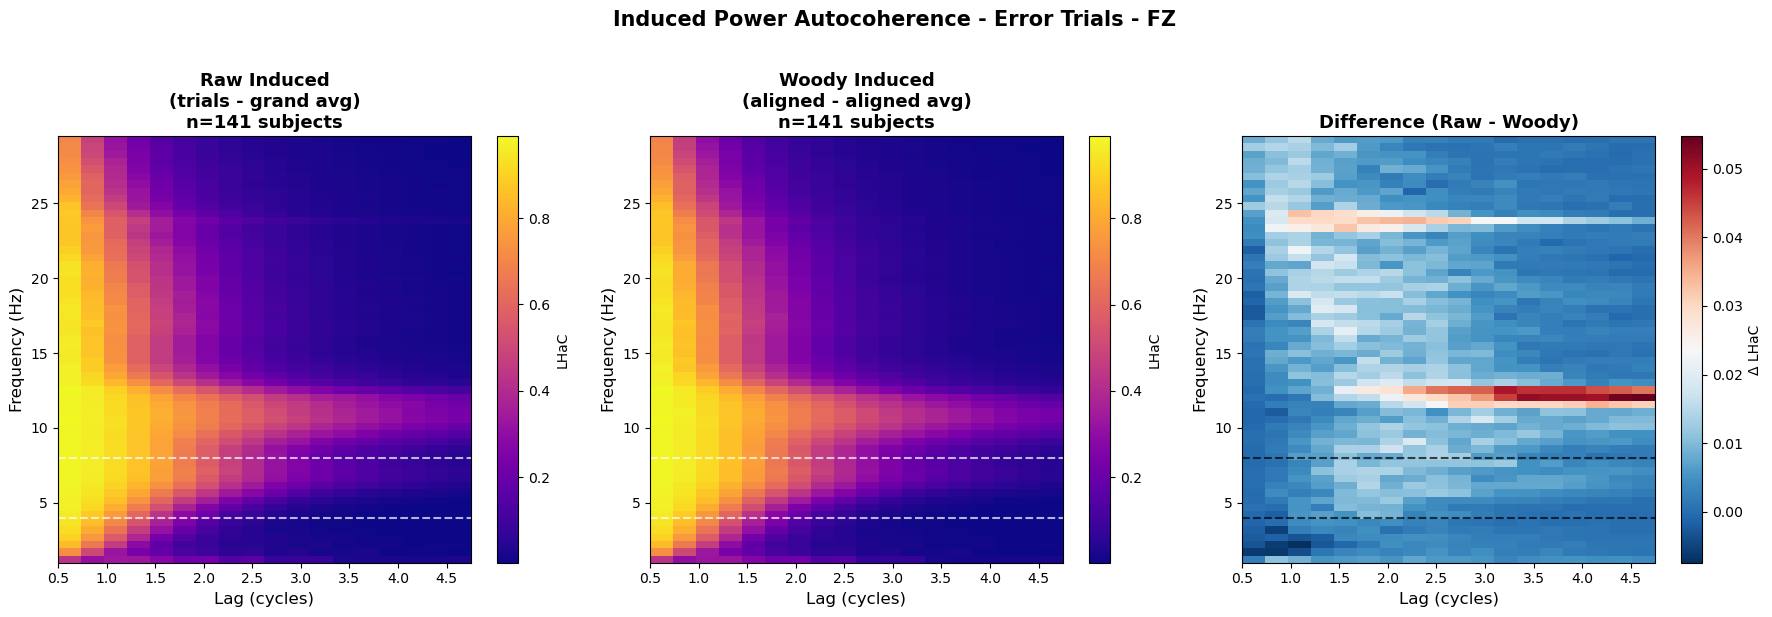


INTERPRETATION:

Induced theta band (4-8 Hz) average:
  Raw induced:   0.377
  Woody induced: 0.371
  Reduction:     1.5%

✓ MINIMAL REDUCTION + PRESERVED COHERENCE
→ The induced theta is likely a TRUE OSCILLATION
→ Alignment preserves oscillatory structure

→ CONCLUSION: Your TFR induced theta represents real oscillations

Beta band (13-30 Hz) for comparison:
  Raw induced:   0.234
  Woody induced: 0.227
  Reduction:     3.0%


In [ ]:
# Extract autocoherence data for induced power
lcs_induced_raw_all = []
lcs_induced_woody_all = []

for result in all_results_induced:
    # Average over trials for each subject
    lcs_induced_raw_all.append(result['lcs_induced_raw'].mean(axis=0))  # (n_freqs, n_lags)
    lcs_induced_woody_all.append(result['lcs_induced_woody'].mean(axis=0))

# Convert to arrays and average across subjects
lcs_induced_raw_all = np.array(lcs_induced_raw_all)
lcs_induced_woody_all = np.array(lcs_induced_woody_all)

lhc_induced_raw_mean = lcs_induced_raw_all.mean(axis=0)
lhc_induced_woody_mean = lcs_induced_woody_all.mean(axis=0)
lhc_induced_diff = lhc_induced_raw_mean - lhc_induced_woody_mean

print(f"Group statistics (INDUCED):")
print(f"  Raw induced - mean: {lhc_induced_raw_mean.mean():.3f}, max: {lhc_induced_raw_mean.max():.3f}")
print(f"  Woody induced - mean: {lhc_induced_woody_mean.mean():.3f}, max: {lhc_induced_woody_mean.max():.3f}")
print(f"  Difference - mean: {lhc_induced_diff.mean():.3f}, max: {lhc_induced_diff.max():.3f}")

# Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Raw induced
im1 = axes[0].imshow(lhc_induced_raw_mean, aspect='auto', origin='lower', cmap='plasma',
                     extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[0].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0].set_xlabel('Lag (cycles)', fontsize=12)
axes[0].set_ylabel('Frequency (Hz)', fontsize=12)
axes[0].set_title(f'Raw Induced\n(trials - grand avg)\nn={len(all_results_induced)} subjects', 
                  fontsize=13, fontweight='bold')
plt.colorbar(im1, ax=axes[0], label='LHaC')

# Woody induced
im2 = axes[1].imshow(lhc_induced_woody_mean, aspect='auto', origin='lower', cmap='plasma',
                     extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[1].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1].set_xlabel('Lag (cycles)', fontsize=12)
axes[1].set_ylabel('Frequency (Hz)', fontsize=12)
axes[1].set_title(f'Woody Induced\n(aligned - aligned avg)\nn={len(all_results_induced)} subjects', 
                  fontsize=13, fontweight='bold')
plt.colorbar(im2, ax=axes[1], label='LHaC')

# Difference (Raw - Woody)
im3 = axes[2].imshow(lhc_induced_diff, aspect='auto', origin='lower', cmap='RdBu_r',
                     extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[2].axhline(4, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[2].axhline(8, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[2].set_xlabel('Lag (cycles)', fontsize=12)
axes[2].set_ylabel('Frequency (Hz)', fontsize=12)
axes[2].set_title('Difference (Raw - Woody)', fontsize=13, fontweight='bold')
plt.colorbar(im3, ax=axes[2], label='Δ LHaC')

plt.suptitle('Induced Power Autocoherence - Error Trials - FZ', 
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


In [19]:
from pathlib import Path
from tqdm import tqdm
import pandas as pd

def analyze_subject_induced_autocoherence_correct(epochs_path, freqs_range, lags_range, time_window=(-5, 5)):
    """
    Compute autocoherence for raw induced and Woody induced correct trials.
    """
    # Load epochs
    epochs = mne.read_epochs(epochs_path, preload=True, verbose=False)
    
    # Extract correct trials
    correct_codes = ['106', '107', '116', '117', '126', '127', '136', '137']
    epochs_correct = epochs[correct_codes]
    
    n_trials = len(epochs_correct)
    if n_trials < 10:  # Need enough trials
        return None
    
    # Get data
    data = epochs_correct.copy().pick(['FZ']).get_data()[:, 0, :]
    times = epochs_correct.times
    data_uv = data * 1e6
    sfreq = epochs_correct.info['sfreq']
    
    # Crop to time window
    time_mask = (times >= time_window[0]) & (times <= time_window[1])
    data_cropped = data_uv[:, time_mask]
    
    # === RAW INDUCED (subtract grand average) ===
    grand_avg_raw = data_cropped.mean(axis=0)
    data_induced_raw = data_cropped - grand_avg_raw
    
    # === WOODY INDUCED (align, then subtract aligned grand average) ===
    # Apply Woody filter on full data
    data_T = data_uv.T
    aligned_avg, detected_lags = woody(
        data_T,
        tol=0.1,
        max_it=100,
        est_mthd='woody',
        xcorr_mthd='unbiased',
        max_shift=100
    )
    
    # Reconstruct aligned trials
    aligned_trials = np.zeros_like(data_uv)
    for i in range(n_trials):
        lag = detected_lags[i]
        if lag > 0:
            aligned_trials[i, :] = np.concatenate([data_uv[i, lag:], np.zeros(lag)])
        elif lag < 0:
            aligned_trials[i, :] = np.concatenate([np.zeros(-lag), data_uv[i, :lag]])
        else:
            aligned_trials[i, :] = data_uv[i, :]
    
    # Crop aligned trials
    data_woody_cropped = aligned_trials[:, time_mask]
    
    # Subtract aligned grand average
    grand_avg_woody = data_woody_cropped.mean(axis=0)
    data_induced_woody = data_woody_cropped - grand_avg_woody
    
    # === COMPUTE AUTOCOHERENCE ===
    lcs_induced_raw = lagged_hilbert_autocoherence(
        data_induced_raw,
        freqs_range,
        lags_range,
        srate=sfreq,
        df=1.0,
        # thresh_prctile=None
    )
    
    lcs_induced_woody = lagged_hilbert_autocoherence(
        data_induced_woody,
        freqs_range,
        lags_range,
        srate=sfreq,
        df=1.0,
        # thresh_prctile=None
    )
    
    results = {
        'subject': Path(epochs_path).parent.name,
        'n_trials': n_trials,
        'lcs_induced_raw': lcs_induced_raw,
        'lcs_induced_woody': lcs_induced_woody,
        'mean_lag_ms': detected_lags.mean() / sfreq * 1000,
        'std_lag_ms': detected_lags.std() / sfreq * 1000
    }
    
    return results


# === SETUP ===
subjects = ['sub-AG05AS29', 'sub-AH17AR05', 'sub-AL07NK06', 'sub-AL08AS02', 'sub-AR06AS06', 
            'sub-AR10IO04', 'sub-AT06ED25', 'sub-AU09GE22', 'sub-CH04ER19', 'sub-CH05NK28', 
            'sub-CH06UT07', 'sub-CH07AD15', 'sub-CH09AS13', 'sub-CK04NS18', 'sub-CK06ED08', 
            'sub-CK06ST11', 'sub-CK06US15', 'sub-DADARE11', 'sub-DT05EV26', 'sub-DT07ES22', 
            'sub-DTINTZ10', 'sub-EK05AN14', 'sub-EK06ER26', 'sub-EK07CH24', 'sub-EL05JO26', 
            'sub-EL06LD17', 'sub-EL07EL14', 'sub-EN04ER01', 'sub-EN05AN02', 'sub-EN05KT02', 
            'sub-EN05US05', 'sub-EN06AN21', 'sub-EN08CH27', 'sub-EP05EN09', 'sub-ER03ER09', 
            'sub-ER04ER12', 'sub-ER04RT24', 'sub-ER05AN13', 'sub-ER05AV01', 'sub-ER05EL09', 
            'sub-ER05EL26', 'sub-ER05ER07', 'sub-ER05IM29', 'sub-ER05MA17', 'sub-ER05NG11', 
            'sub-ER05RK06', 'sub-ER05RT24', 'sub-ER06EL06', 'sub-ER06EN27', 'sub-ER06ET15', 
            'sub-ER06IS22', 'sub-ER06US24', 'sub-ER07AN28', 'sub-ER07AS24', 'sub-ER07EF15', 
            'sub-ER07EL10', 'sub-ER07ER23', 'sub-ER07ER30', 'sub-ER07RL02', 'sub-ER08AS28', 
            'sub-ER08EN05', 'sub-ER09NK30', 'sub-ES06ER27', 'sub-ES06NK11', 'sub-EZ04SE15', 
            'sub-GA04LI18', 'sub-HEERLD19', 'sub-IA05NS20', 'sub-ID07EN28', 'sub-IG06AI28', 
            'sub-IG06LF01', 'sub-IG06NS07', 'sub-IG06WE03', 'sub-IG07RT16', 'sub-IK06ET06', 
            'sub-IK09LD05', 'sub-IN05ED23', 'sub-IN06AS14', 'sub-IS06RG09', 'sub-IT08ND26', 
            'sub-JU05IN24', 'sub-KA04LF11', 'sub-KE05AN23', 'sub-KE07AN05', 'sub-KE07ER04', 
            'sub-KE08AS23', 'sub-KN05EN09', 'sub-KO07EL16', 'sub-LA08RE26', 'sub-LO06RE10', 
            'sub-LY07EL23', 'sub-MA06LO21', 'sub-ME05NS04', 'sub-NA04AV25', 'sub-ND05NG06', 
            'sub-ND06EF01', 'sub-NE06AS01', 'sub-NE06EL01', 'sub-NG03YI17', 'sub-NG06EA08', 
            'sub-NK06AS24', 'sub-NK06RG30', 'sub-NN04AN24', 'sub-NN05AN05', 'sub-NN05IR17', 
            'sub-NN06TH16', 'sub-NN07EN14', 'sub-NN07ID18', 'sub-NN08AS03', 'sub-NN08EL29', 
            'sub-NN08ER22', 'sub-NN08LM06', 'sub-NN09LM18', 'sub-NN09NS31', 'sub-NO05RT22', 
            'sub-NS09EL05', 'sub-NY04DT26', 'sub-NZ04EN16', 'sub-NZ09ER04', 'sub-OH05NK29', 
            'sub-ON05EL22', 'sub-OW07RK26', 'sub-PP07AS29', 'sub-RASUAN07', 'sub-RF09EL18', 
            'sub-RG05RS16', 'sub-RG06AS09', 'sub-RO06AN18', 'sub-RT07LD06', 'sub-RYRAAN26', 
            'sub-RZ05ND19', 'sub-SA05AH22', 'sub-SE05AS26', 'sub-SE05ZI24', 'sub-SE06AM29', 
            'sub-SE06NS17', 'sub-ST03ED03', 'sub-ST07NK15', 'sub-TA03RL11', 'sub-TE05AS09', 
            'sub-TE05NS01', 'sub-TE10AN12', 'sub-TH07AR12', 'sub-TH08ER21', 'sub-TT06LF28', 
            'sub-TT08NS17', 'sub-TZ08US31', 'sub-US07US10', 'sub-US08KE27', 'sub-VA05AS27', 
            'sub-VA05OR26', 'sub-VA06NZ29', 'sub-VA06OV12', 'sub-WA04EJ22', 'sub-WA05EJ08', 
            'sub-XX04AS28']

data_dir = Path("/Users/qmoreau/Documents/ERN_sim/ernpipeline/")

freqs_range = np.arange(1, 30, 0.5)
lags_range = np.arange(0.5, 5, 0.25)

# Run analysis for CORRECT trials
all_results_correct = []
for sub_id in tqdm(subjects, desc="Processing subjects (correct trials)"):
    sub_file = data_dir / sub_id / f"{sub_id}_desc-epochs_eeg.fif"
    
    if not sub_file.exists():
        continue
    
    try:
        results = analyze_subject_induced_autocoherence_correct(sub_file, freqs_range, lags_range)
        if results is not None:
            all_results_correct.append(results)
    except Exception as e:
        print(f"\nError with {sub_id}: {e}")
        continue

Processing subjects (correct trials): 100%|██████████| 156/156 [2:00:41<00:00, 46.42s/it] 


Group statistics (INDUCED - CORRECT TRIALS):
  Raw induced - mean: 0.296, max: 0.990
  Woody induced - mean: 0.291, max: 0.987
  Difference - mean: 0.005, max: 0.051


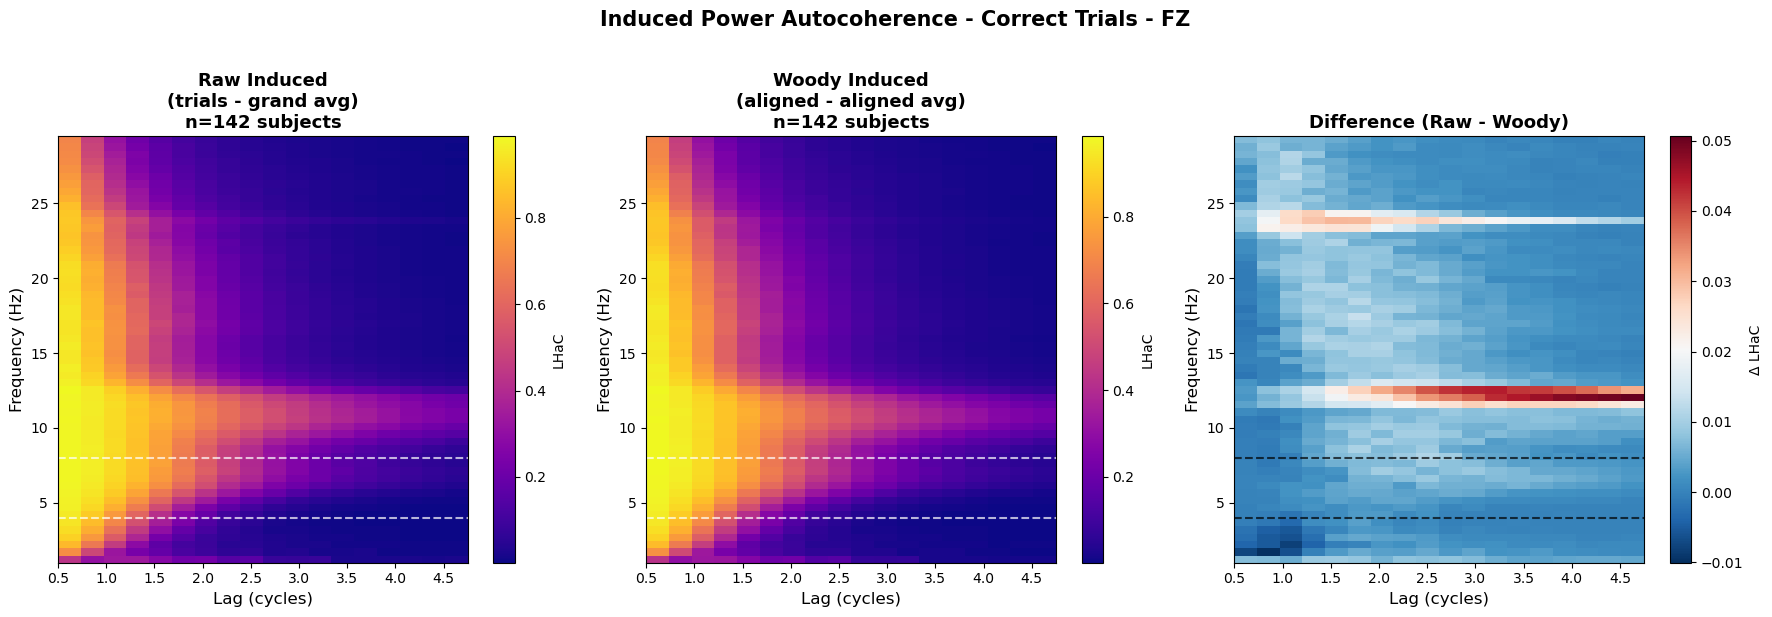


INTERPRETATION (CORRECT TRIALS):

Induced theta band (4-8 Hz) average:
  Raw induced:   0.373
  Woody induced: 0.370
  Reduction:     0.9%

✓ MINIMAL REDUCTION + PRESERVED COHERENCE
→ The induced theta is likely a TRUE OSCILLATION
→ Alignment preserves oscillatory structure

→ CONCLUSION: Your TFR induced theta represents real oscillations

Beta band (13-30 Hz) for comparison:
  Raw induced:   0.236
  Woody induced: 0.231
  Reduction:     2.1%


In [ ]:
# Extract autocoherence data for induced power (CORRECT TRIALS)
lcs_induced_raw_all_correct = []
lcs_induced_woody_all_correct = []

for result in all_results_correct:
    # Average over trials for each subject
    lcs_induced_raw_all_correct.append(result['lcs_induced_raw'].mean(axis=0))  # (n_freqs, n_lags)
    lcs_induced_woody_all_correct.append(result['lcs_induced_woody'].mean(axis=0))

# Convert to arrays and average across subjects
lcs_induced_raw_all_correct = np.array(lcs_induced_raw_all_correct)
lcs_induced_woody_all_correct = np.array(lcs_induced_woody_all_correct)

lhc_induced_raw_mean_correct = lcs_induced_raw_all_correct.mean(axis=0)
lhc_induced_woody_mean_correct = lcs_induced_woody_all_correct.mean(axis=0)
lhc_induced_diff_correct = lhc_induced_raw_mean_correct - lhc_induced_woody_mean_correct

print(f"Group statistics (INDUCED - CORRECT TRIALS):")
print(f"  Raw induced - mean: {lhc_induced_raw_mean_correct.mean():.3f}, max: {lhc_induced_raw_mean_correct.max():.3f}")
print(f"  Woody induced - mean: {lhc_induced_woody_mean_correct.mean():.3f}, max: {lhc_induced_woody_mean_correct.max():.3f}")
print(f"  Difference - mean: {lhc_induced_diff_correct.mean():.3f}, max: {lhc_induced_diff_correct.max():.3f}")

# Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Raw induced
im1 = axes[0].imshow(lhc_induced_raw_mean_correct, aspect='auto', origin='lower', cmap='plasma',
                     extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[0].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0].set_xlabel('Lag (cycles)', fontsize=12)
axes[0].set_ylabel('Frequency (Hz)', fontsize=12)
axes[0].set_title(f'Raw Induced\n(trials - grand avg)\nn={len(all_results_correct)} subjects', 
                  fontsize=13, fontweight='bold')
plt.colorbar(im1, ax=axes[0], label='LHaC')

# Woody induced
im2 = axes[1].imshow(lhc_induced_woody_mean_correct, aspect='auto', origin='lower', cmap='plasma',
                     extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[1].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1].set_xlabel('Lag (cycles)', fontsize=12)
axes[1].set_ylabel('Frequency (Hz)', fontsize=12)
axes[1].set_title(f'Woody Induced\n(aligned - aligned avg)\nn={len(all_results_correct)} subjects', 
                  fontsize=13, fontweight='bold')
plt.colorbar(im2, ax=axes[1], label='LHaC')

# Difference (Raw - Woody)
im3 = axes[2].imshow(lhc_induced_diff_correct, aspect='auto', origin='lower', cmap='RdBu_r',
                     extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[2].axhline(4, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[2].axhline(8, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[2].set_xlabel('Lag (cycles)', fontsize=12)
axes[2].set_ylabel('Frequency (Hz)', fontsize=12)
axes[2].set_title('Difference (Raw - Woody)', fontsize=13, fontweight='bold')
plt.colorbar(im3, ax=axes[2], label='Δ LHaC')

plt.suptitle('Induced Power Autocoherence - Correct Trials - FZ', 
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


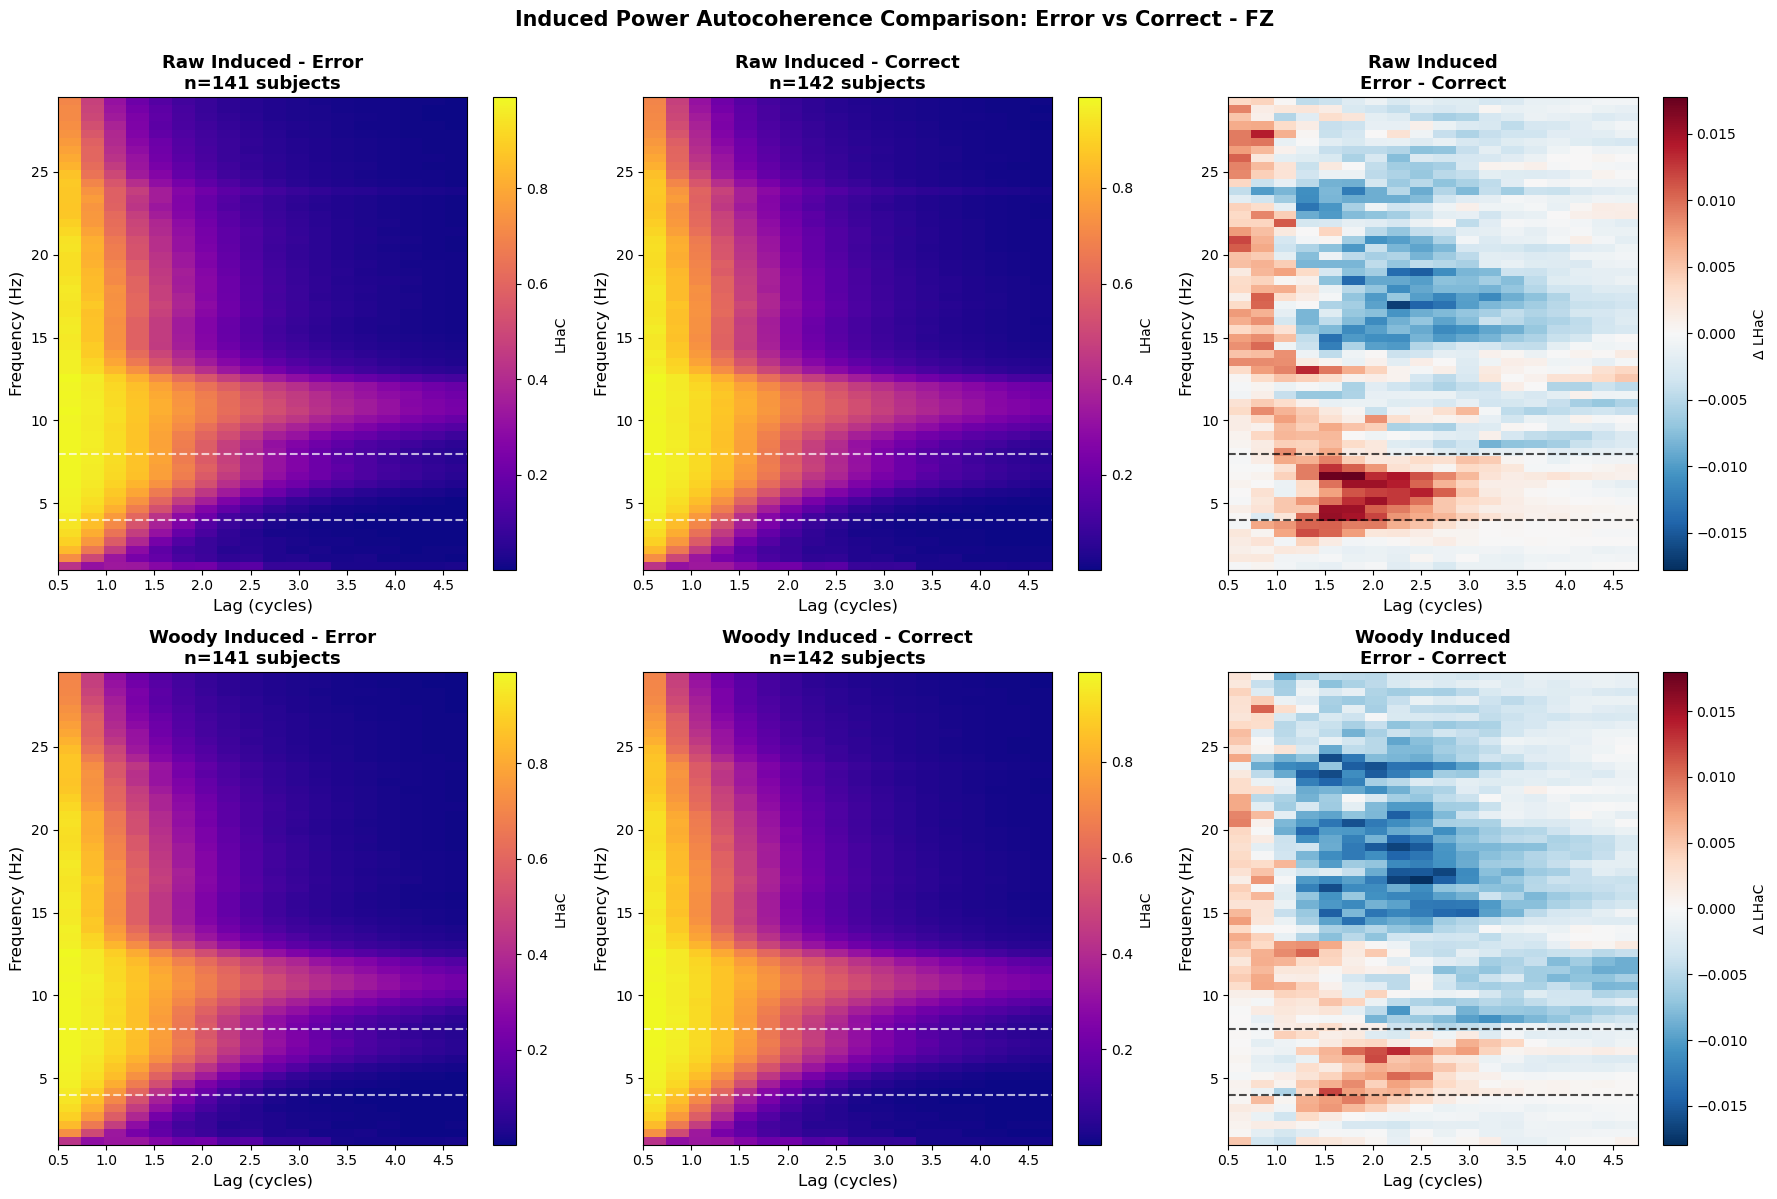


ERROR vs CORRECT COMPARISON:

RAW INDUCED - Theta (4-8 Hz):
  Error:      0.377
  Correct:    0.373
  Difference: 0.004 (+1.0%)

WOODY INDUCED - Theta (4-8 Hz):
  Error:      0.371
  Correct:    0.370
  Difference: 0.002 (+0.4%)

RAW INDUCED - Beta (13-30 Hz):
  Error:      0.234
  Correct:    0.236
  Difference: -0.002 (-1.0%)

WOODY INDUCED - Beta (13-30 Hz):
  Error:      0.227
  Correct:    0.231
  Difference: -0.004 (-1.9%)


In [ ]:
# Compute differences between Error and Correct
lhc_raw_diff_error_correct = lhc_induced_raw_mean - lhc_induced_raw_mean_correct
lhc_woody_diff_error_correct = lhc_induced_woody_mean - lhc_induced_woody_mean_correct

# Create 2x3 plot
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# ===== ROW 1: RAW INDUCED =====
# Raw Induced - Error
im1 = axes[0, 0].imshow(lhc_induced_raw_mean, aspect='auto', origin='lower', cmap='plasma',
                         extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[0, 0].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 0].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 0].set_xlabel('Lag (cycles)', fontsize=12)
axes[0, 0].set_ylabel('Frequency (Hz)', fontsize=12)
axes[0, 0].set_title(f'Raw Induced - Error\nn={len(all_results_induced)} subjects', 
                      fontsize=13, fontweight='bold')
plt.colorbar(im1, ax=axes[0, 0], label='LHaC')

# Raw Induced - Correct
im2 = axes[0, 1].imshow(lhc_induced_raw_mean_correct, aspect='auto', origin='lower', cmap='plasma',
                         extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[0, 1].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 1].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 1].set_xlabel('Lag (cycles)', fontsize=12)
axes[0, 1].set_ylabel('Frequency (Hz)', fontsize=12)
axes[0, 1].set_title(f'Raw Induced - Correct\nn={len(all_results_correct)} subjects', 
                      fontsize=13, fontweight='bold')
plt.colorbar(im2, ax=axes[0, 1], label='LHaC')

# Raw Induced - Difference (Error - Correct)
im3 = axes[0, 2].imshow(lhc_raw_diff_error_correct, aspect='auto', origin='lower', cmap='RdBu_r',
                         extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]],
                         vmin=-np.abs(lhc_raw_diff_error_correct).max(), 
                         vmax=np.abs(lhc_raw_diff_error_correct).max())
axes[0, 2].axhline(4, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 2].axhline(8, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 2].set_xlabel('Lag (cycles)', fontsize=12)
axes[0, 2].set_ylabel('Frequency (Hz)', fontsize=12)
axes[0, 2].set_title('Raw Induced\nError - Correct', fontsize=13, fontweight='bold')
plt.colorbar(im3, ax=axes[0, 2], label='Δ LHaC')

# ===== ROW 2: WOODY INDUCED =====
# Woody Induced - Error
im4 = axes[1, 0].imshow(lhc_induced_woody_mean, aspect='auto', origin='lower', cmap='plasma',
                         extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[1, 0].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1, 0].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1, 0].set_xlabel('Lag (cycles)', fontsize=12)
axes[1, 0].set_ylabel('Frequency (Hz)', fontsize=12)
axes[1, 0].set_title(f'Woody Induced - Error\nn={len(all_results_induced)} subjects', 
                      fontsize=13, fontweight='bold')
plt.colorbar(im4, ax=axes[1, 0], label='LHaC')

# Woody Induced - Correct
im5 = axes[1, 1].imshow(lhc_induced_woody_mean_correct, aspect='auto', origin='lower', cmap='plasma',
                         extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[1, 1].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1, 1].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1, 1].set_xlabel('Lag (cycles)', fontsize=12)
axes[1, 1].set_ylabel('Frequency (Hz)', fontsize=12)
axes[1, 1].set_title(f'Woody Induced - Correct\nn={len(all_results_correct)} subjects', 
                      fontsize=13, fontweight='bold')
plt.colorbar(im5, ax=axes[1, 1], label='LHaC')

# Woody Induced - Difference (Error - Correct)
im6 = axes[1, 2].imshow(lhc_woody_diff_error_correct, aspect='auto', origin='lower', cmap='RdBu_r',
                         extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]],
                         vmin=-np.abs(lhc_woody_diff_error_correct).max(), 
                         vmax=np.abs(lhc_woody_diff_error_correct).max())
axes[1, 2].axhline(4, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1, 2].axhline(8, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1, 2].set_xlabel('Lag (cycles)', fontsize=12)
axes[1, 2].set_ylabel('Frequency (Hz)', fontsize=12)
axes[1, 2].set_title('Woody Induced\nError - Correct', fontsize=13, fontweight='bold')
plt.colorbar(im6, ax=axes[1, 2], label='Δ LHaC')

plt.suptitle('Induced Power Autocoherence Comparison: Error vs Correct - FZ', 
             fontsize=15, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


In [25]:
from pathlib import Path
from tqdm import tqdm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================================
# ANALYSIS FUNCTIONS
# ============================================================================

def analyze_subject_induced_autocoherence_error(epochs_path, freqs_range, lags_range, time_window=(-5, 5)):
    """Compute autocoherence for raw induced and Woody induced error trials."""
    epochs = mne.read_epochs(epochs_path, preload=True, verbose=False)
    incorrect_codes = ['108', '109', '118', '119', '128', '129', '138', '139']
    epochs_incorrect = epochs[incorrect_codes]
    
    n_trials = len(epochs_incorrect)
    if n_trials < 10:
        return None
    
    data = epochs_incorrect.copy().pick(['FZ']).get_data()[:, 0, :]
    times = epochs_incorrect.times
    data_uv = data * 1e6
    sfreq = epochs_incorrect.info['sfreq']
    
    time_mask = (times >= time_window[0]) & (times <= time_window[1])
    data_cropped = data_uv[:, time_mask]
    
    grand_avg_raw = data_cropped.mean(axis=0)
    data_induced_raw = data_cropped - grand_avg_raw
    
    data_T = data_uv.T
    aligned_avg, detected_lags = woody(data_T, tol=0.1, max_it=100, 
                                        est_mthd='woody', xcorr_mthd='unbiased', max_shift=100)
    
    aligned_trials = np.zeros_like(data_uv)
    for i in range(n_trials):
        lag = detected_lags[i]
        if lag > 0:
            aligned_trials[i, :] = np.concatenate([data_uv[i, lag:], np.zeros(lag)])
        elif lag < 0:
            aligned_trials[i, :] = np.concatenate([np.zeros(-lag), data_uv[i, :lag]])
        else:
            aligned_trials[i, :] = data_uv[i, :]
    
    data_woody_cropped = aligned_trials[:, time_mask]
    grand_avg_woody = data_woody_cropped.mean(axis=0)
    data_induced_woody = data_woody_cropped - grand_avg_woody
    
    lcs_induced_raw = lagged_hilbert_autocoherence(data_induced_raw, freqs_range, lags_range, srate=sfreq, df=1.0)
    lcs_induced_woody = lagged_hilbert_autocoherence(data_induced_woody, freqs_range, lags_range, srate=sfreq, df=1.0)
    
    return {
        'subject': Path(epochs_path).parent.name,
        'n_trials': n_trials,
        'lcs_induced_raw': lcs_induced_raw,
        'lcs_induced_woody': lcs_induced_woody,
        'mean_lag_ms': detected_lags.mean() / sfreq * 1000,
        'std_lag_ms': detected_lags.std() / sfreq * 1000
    }


def analyze_subject_induced_autocoherence_correct(epochs_path, freqs_range, lags_range, time_window=(-5, 5)):
    """Compute autocoherence for raw induced and Woody induced correct trials."""
    epochs = mne.read_epochs(epochs_path, preload=True, verbose=False)
    correct_codes = ['106', '107', '116', '117', '126', '127', '136', '137']
    epochs_correct = epochs[correct_codes]
    
    n_trials = len(epochs_correct)
    if n_trials < 10:
        return None
    
    data = epochs_correct.copy().pick(['FZ']).get_data()[:, 0, :]
    times = epochs_correct.times
    data_uv = data * 1e6
    sfreq = epochs_correct.info['sfreq']
    
    time_mask = (times >= time_window[0]) & (times <= time_window[1])
    data_cropped = data_uv[:, time_mask]
    
    grand_avg_raw = data_cropped.mean(axis=0)
    data_induced_raw = data_cropped - grand_avg_raw
    
    data_T = data_uv.T
    aligned_avg, detected_lags = woody(data_T, tol=0.1, max_it=100, 
                                        est_mthd='woody', xcorr_mthd='unbiased', max_shift=100)
    
    aligned_trials = np.zeros_like(data_uv)
    for i in range(n_trials):
        lag = detected_lags[i]
        if lag > 0:
            aligned_trials[i, :] = np.concatenate([data_uv[i, lag:], np.zeros(lag)])
        elif lag < 0:
            aligned_trials[i, :] = np.concatenate([np.zeros(-lag), data_uv[i, :lag]])
        else:
            aligned_trials[i, :] = data_uv[i, :]
    
    data_woody_cropped = aligned_trials[:, time_mask]
    grand_avg_woody = data_woody_cropped.mean(axis=0)
    data_induced_woody = data_woody_cropped - grand_avg_woody
    
    lcs_induced_raw = lagged_hilbert_autocoherence(data_induced_raw, freqs_range, lags_range, srate=sfreq, df=1.0)
    lcs_induced_woody = lagged_hilbert_autocoherence(data_induced_woody, freqs_range, lags_range, srate=sfreq, df=1.0)
    
    return {
        'subject': Path(epochs_path).parent.name,
        'n_trials': n_trials,
        'lcs_induced_raw': lcs_induced_raw,
        'lcs_induced_woody': lcs_induced_woody,
        'mean_lag_ms': detected_lags.mean() / sfreq * 1000,
        'std_lag_ms': detected_lags.std() / sfreq * 1000
    }


# ============================================================================
# SETUP
# ============================================================================

subjects = ['sub-AG05AS29', 'sub-AH17AR05', 'sub-AL07NK06', 'sub-AL08AS02', 'sub-AR06AS06', 
            'sub-AR10IO04', 'sub-AT06ED25', 'sub-AU09GE22', 'sub-CH04ER19', 'sub-CH05NK28', 
            'sub-CH06UT07', 'sub-CH07AD15', 'sub-CH09AS13', 'sub-CK04NS18', 'sub-CK06ED08', 
            'sub-CK06ST11', 'sub-CK06US15', 'sub-DADARE11', 'sub-DT05EV26', 'sub-DT07ES22', 
            'sub-DTINTZ10', 'sub-EK05AN14', 'sub-EK06ER26', 'sub-EK07CH24', 'sub-EL05JO26', 
            'sub-EL06LD17', 'sub-EL07EL14', 'sub-EN04ER01', 'sub-EN05AN02', 'sub-EN05KT02', 
            'sub-EN05US05', 'sub-EN06AN21', 'sub-EN08CH27', 'sub-EP05EN09', 'sub-ER03ER09', 
            'sub-ER04ER12', 'sub-ER04RT24', 'sub-ER05AN13', 'sub-ER05AV01', 'sub-ER05EL09', 
            'sub-ER05EL26', 'sub-ER05ER07', 'sub-ER05IM29', 'sub-ER05MA17', 'sub-ER05NG11', 
            'sub-ER05RK06', 'sub-ER05RT24', 'sub-ER06EL06', 'sub-ER06EN27', 'sub-ER06ET15', 
            'sub-ER06IS22', 'sub-ER06US24', 'sub-ER07AN28', 'sub-ER07AS24', 'sub-ER07EF15', 
            'sub-ER07EL10', 'sub-ER07ER23', 'sub-ER07ER30', 'sub-ER07RL02', 'sub-ER08AS28', 
            'sub-ER08EN05', 'sub-ER09NK30', 'sub-ES06ER27', 'sub-ES06NK11', 'sub-EZ04SE15', 
            'sub-GA04LI18', 'sub-HEERLD19', 'sub-IA05NS20', 'sub-ID07EN28', 'sub-IG06AI28', 
            'sub-IG06LF01', 'sub-IG06NS07', 'sub-IG06WE03', 'sub-IG07RT16', 'sub-IK06ET06', 
            'sub-IK09LD05', 'sub-IN05ED23', 'sub-IN06AS14', 'sub-IS06RG09', 'sub-IT08ND26', 
            'sub-JU05IN24', 'sub-KA04LF11', 'sub-KE05AN23', 'sub-KE07AN05', 'sub-KE07ER04', 
            'sub-KE08AS23', 'sub-KN05EN09', 'sub-KO07EL16', 'sub-LA08RE26', 'sub-LO06RE10', 
            'sub-LY07EL23', 'sub-MA06LO21', 'sub-ME05NS04', 'sub-NA04AV25', 'sub-ND05NG06', 
            'sub-ND06EF01', 'sub-NE06AS01', 'sub-NE06EL01', 'sub-NG03YI17', 'sub-NG06EA08', 
            'sub-NK06AS24', 'sub-NK06RG30', 'sub-NN04AN24', 'sub-NN05AN05', 'sub-NN05IR17', 
            'sub-NN06TH16', 'sub-NN07EN14', 'sub-NN07ID18', 'sub-NN08AS03', 'sub-NN08EL29', 
            'sub-NN08ER22', 'sub-NN08LM06', 'sub-NN09LM18', 'sub-NN09NS31', 'sub-NO05RT22', 
            'sub-NS09EL05', 'sub-NY04DT26', 'sub-NZ04EN16', 'sub-NZ09ER04', 'sub-OH05NK29', 
            'sub-ON05EL22', 'sub-OW07RK26', 'sub-PP07AS29', 'sub-RASUAN07', 'sub-RF09EL18', 
            'sub-RG05RS16', 'sub-RG06AS09', 'sub-RO06AN18', 'sub-RT07LD06', 'sub-RYRAAN26', 
            'sub-RZ05ND19', 'sub-SA05AH22', 'sub-SE05AS26', 'sub-SE05ZI24', 'sub-SE06AM29', 
            'sub-SE06NS17', 'sub-ST03ED03', 'sub-ST07NK15', 'sub-TA03RL11', 'sub-TE05AS09', 
            'sub-TE05NS01', 'sub-TE10AN12', 'sub-TH07AR12', 'sub-TH08ER21', 'sub-TT06LF28', 
            'sub-TT08NS17', 'sub-TZ08US31', 'sub-US07US10', 'sub-US08KE27', 'sub-VA05AS27', 
            'sub-VA05OR26', 'sub-VA06NZ29', 'sub-VA06OV12', 'sub-WA04EJ22', 'sub-WA05EJ08', 
            'sub-XX04AS28']

data_dir = Path("/Users/qmoreau/Documents/ERN_sim/ernpipeline/")
freqs_range = np.arange(2, 30, 0.5)
lags_range = np.arange(0.5, 5, 0.25)

# ============================================================================
# PRE-RESPONSE ANALYSIS (-5 to 0)
# ============================================================================

all_results_error_pre = []
all_results_correct_pre = []

for sub_id in tqdm(subjects, desc="PRE-RESPONSE (-5 to 0)"):
    sub_file = data_dir / sub_id / f"{sub_id}_desc-epochs_eeg.fif"
    if not sub_file.exists():
        continue
    
    try:
        results_err = analyze_subject_induced_autocoherence_error(sub_file, freqs_range, lags_range, time_window=(-5, 0))
        if results_err is not None:
            all_results_error_pre.append(results_err)
        
        results_cor = analyze_subject_induced_autocoherence_correct(sub_file, freqs_range, lags_range, time_window=(-5, 0))
        if results_cor is not None:
            all_results_correct_pre.append(results_cor)
    except Exception as e:
        print(f"\nError with {sub_id}: {e}")
        continue

# ============================================================================
# POST-RESPONSE ANALYSIS (0 to +5)
# ============================================================================

all_results_error_post = []
all_results_correct_post = []

for sub_id in tqdm(subjects, desc="POST-RESPONSE (0 to +5)"):
    sub_file = data_dir / sub_id / f"{sub_id}_desc-epochs_eeg.fif"
    if not sub_file.exists():
        continue
    
    try:
        results_err = analyze_subject_induced_autocoherence_error(sub_file, freqs_range, lags_range, time_window=(0, 5))
        if results_err is not None:
            all_results_error_post.append(results_err)
        
        results_cor = analyze_subject_induced_autocoherence_correct(sub_file, freqs_range, lags_range, time_window=(0, 5))
        if results_cor is not None:
            all_results_correct_post.append(results_cor)
    except Exception as e:
        print(f"\nError with {sub_id}: {e}")
        continue

POST-RESPONSE (0 to +5): 100%|██████████| 156/156 [1:08:54<00:00, 26.50s/it]


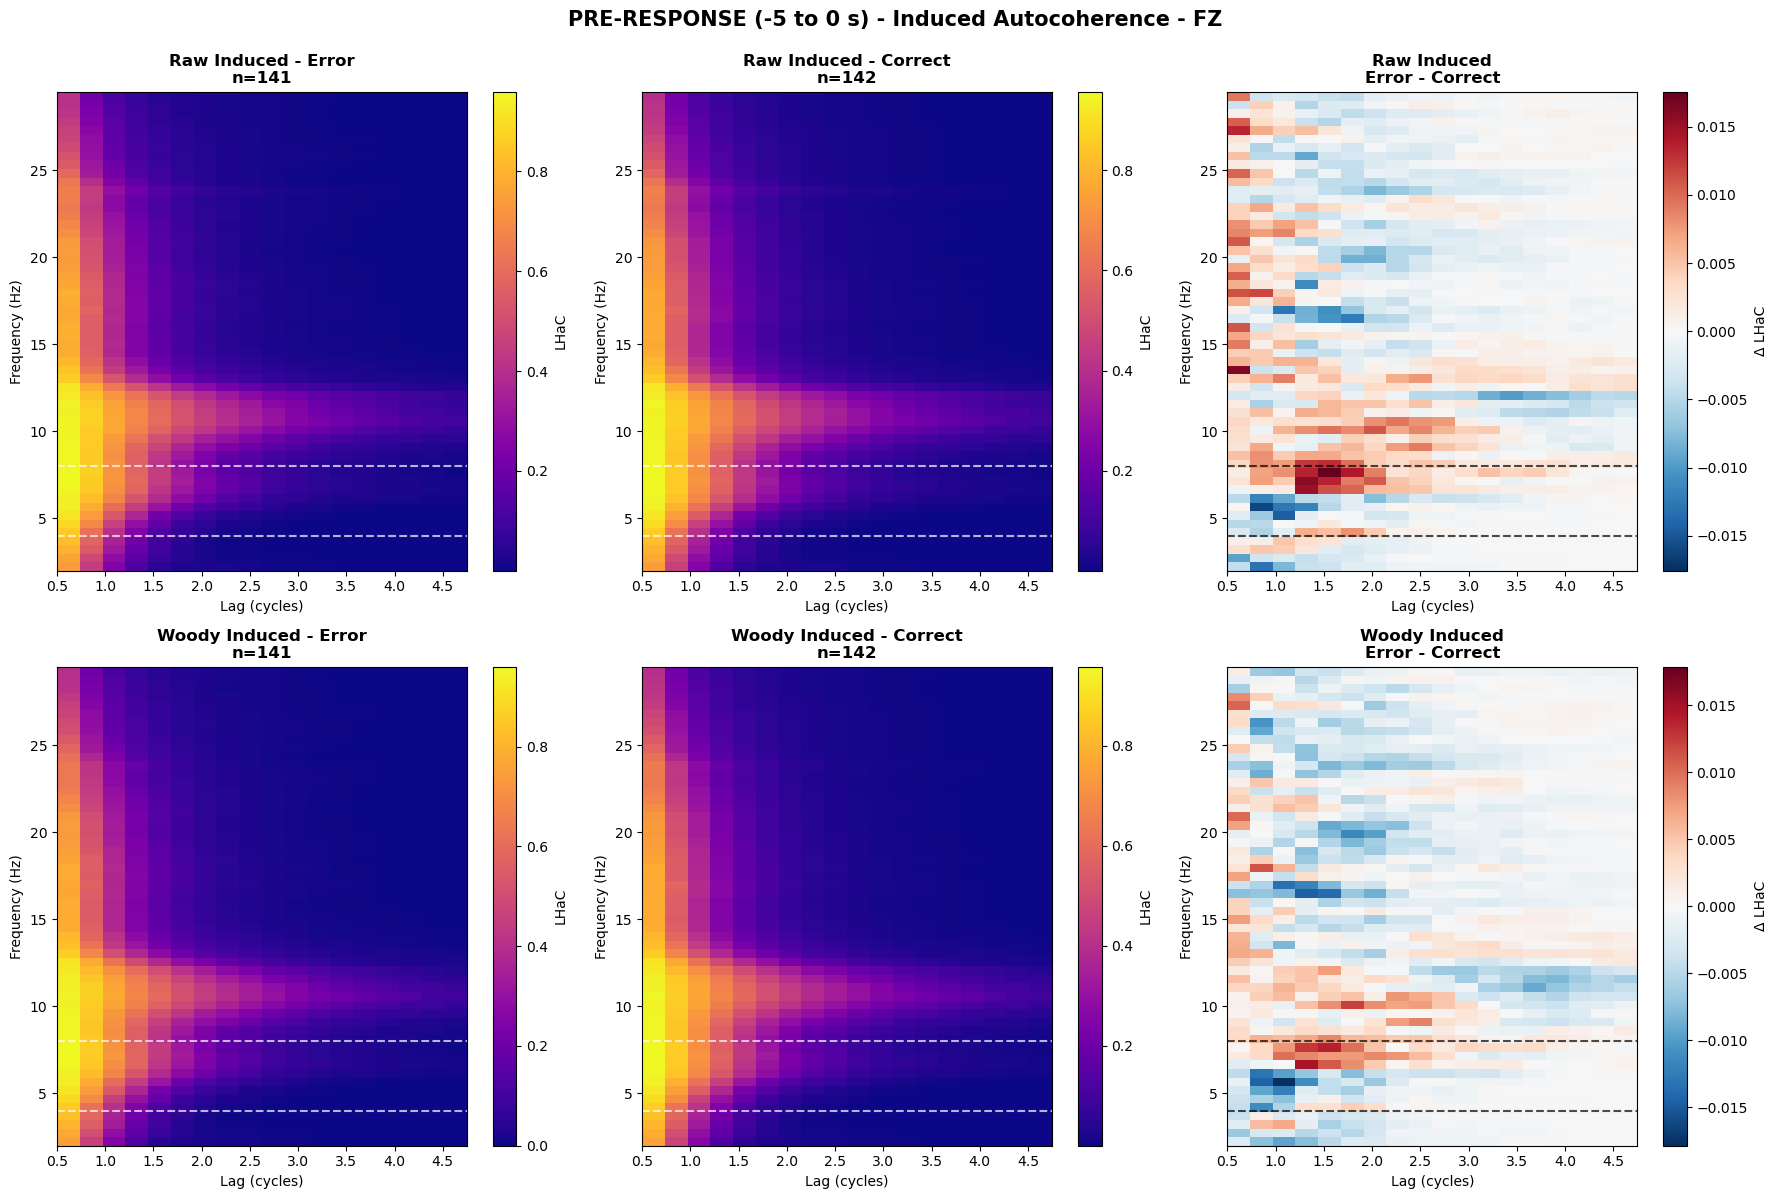

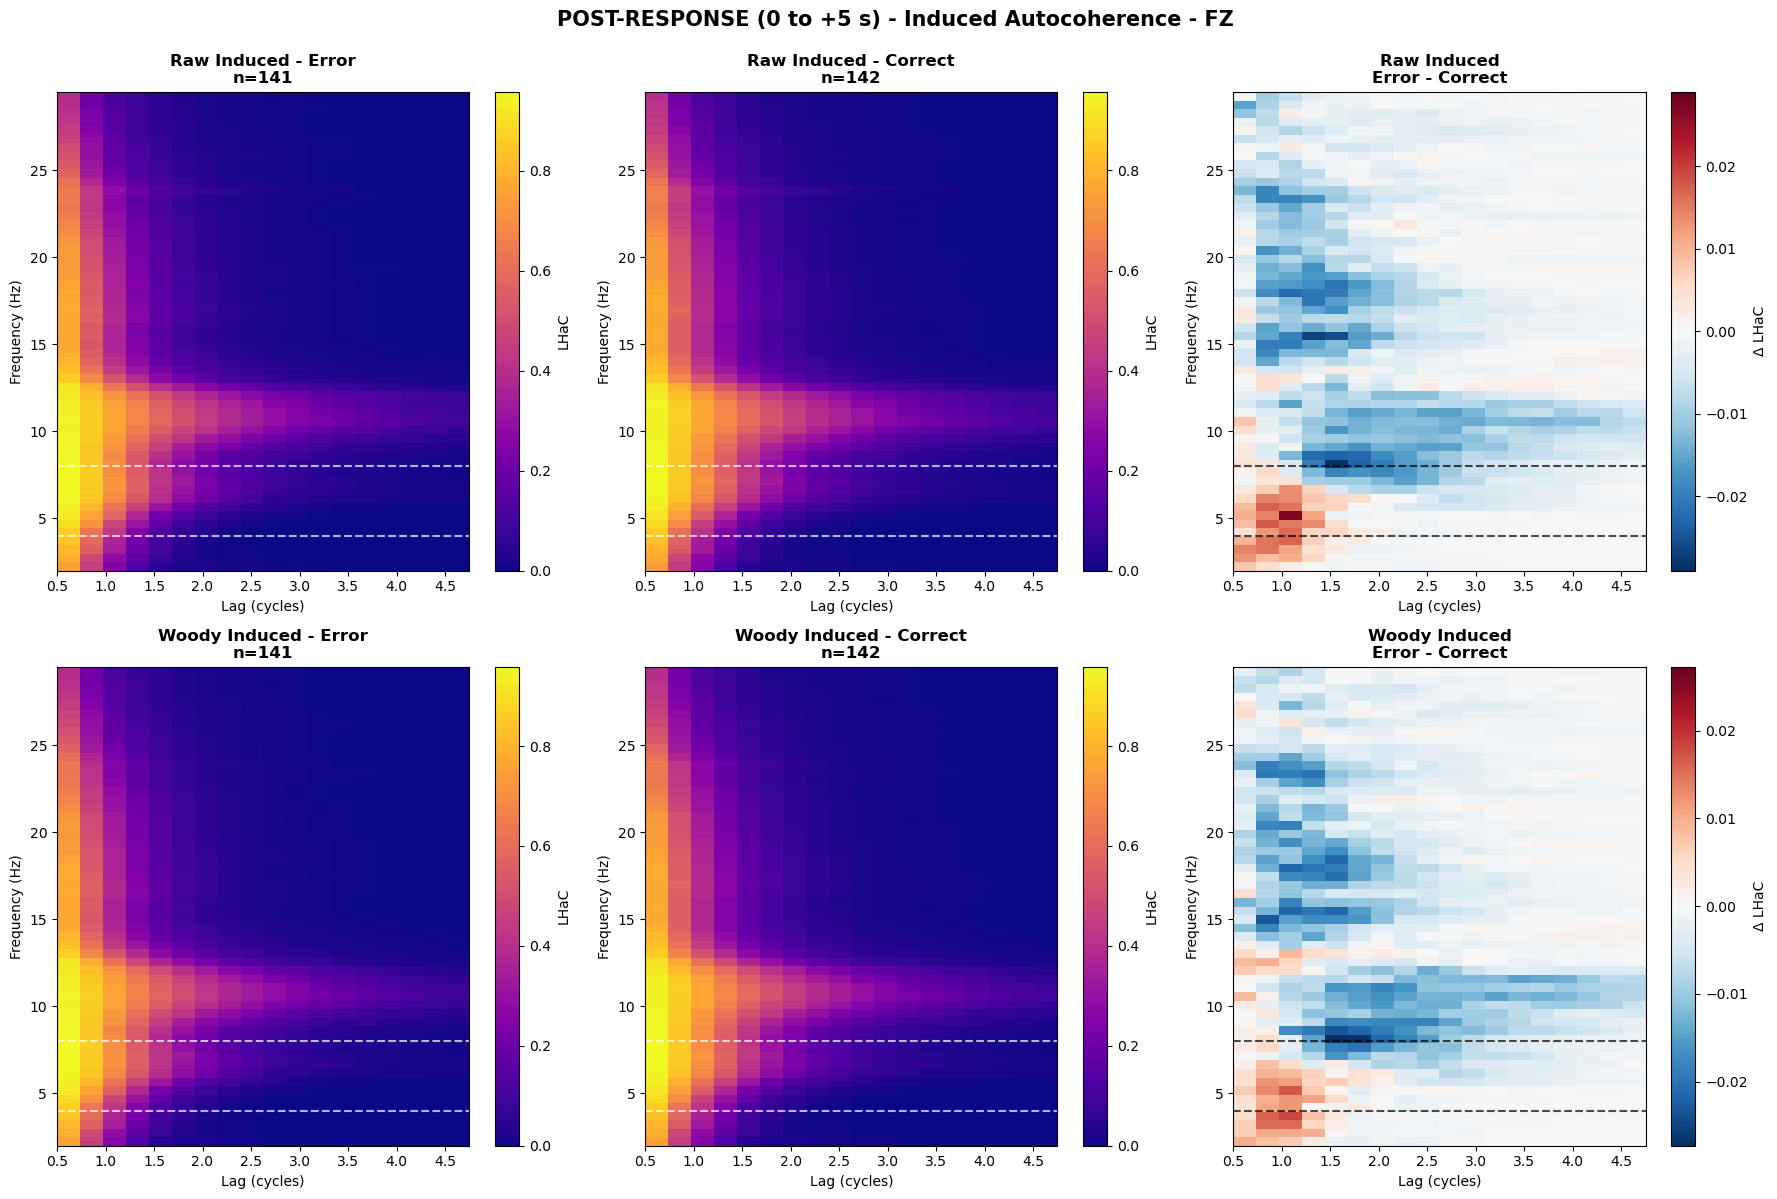

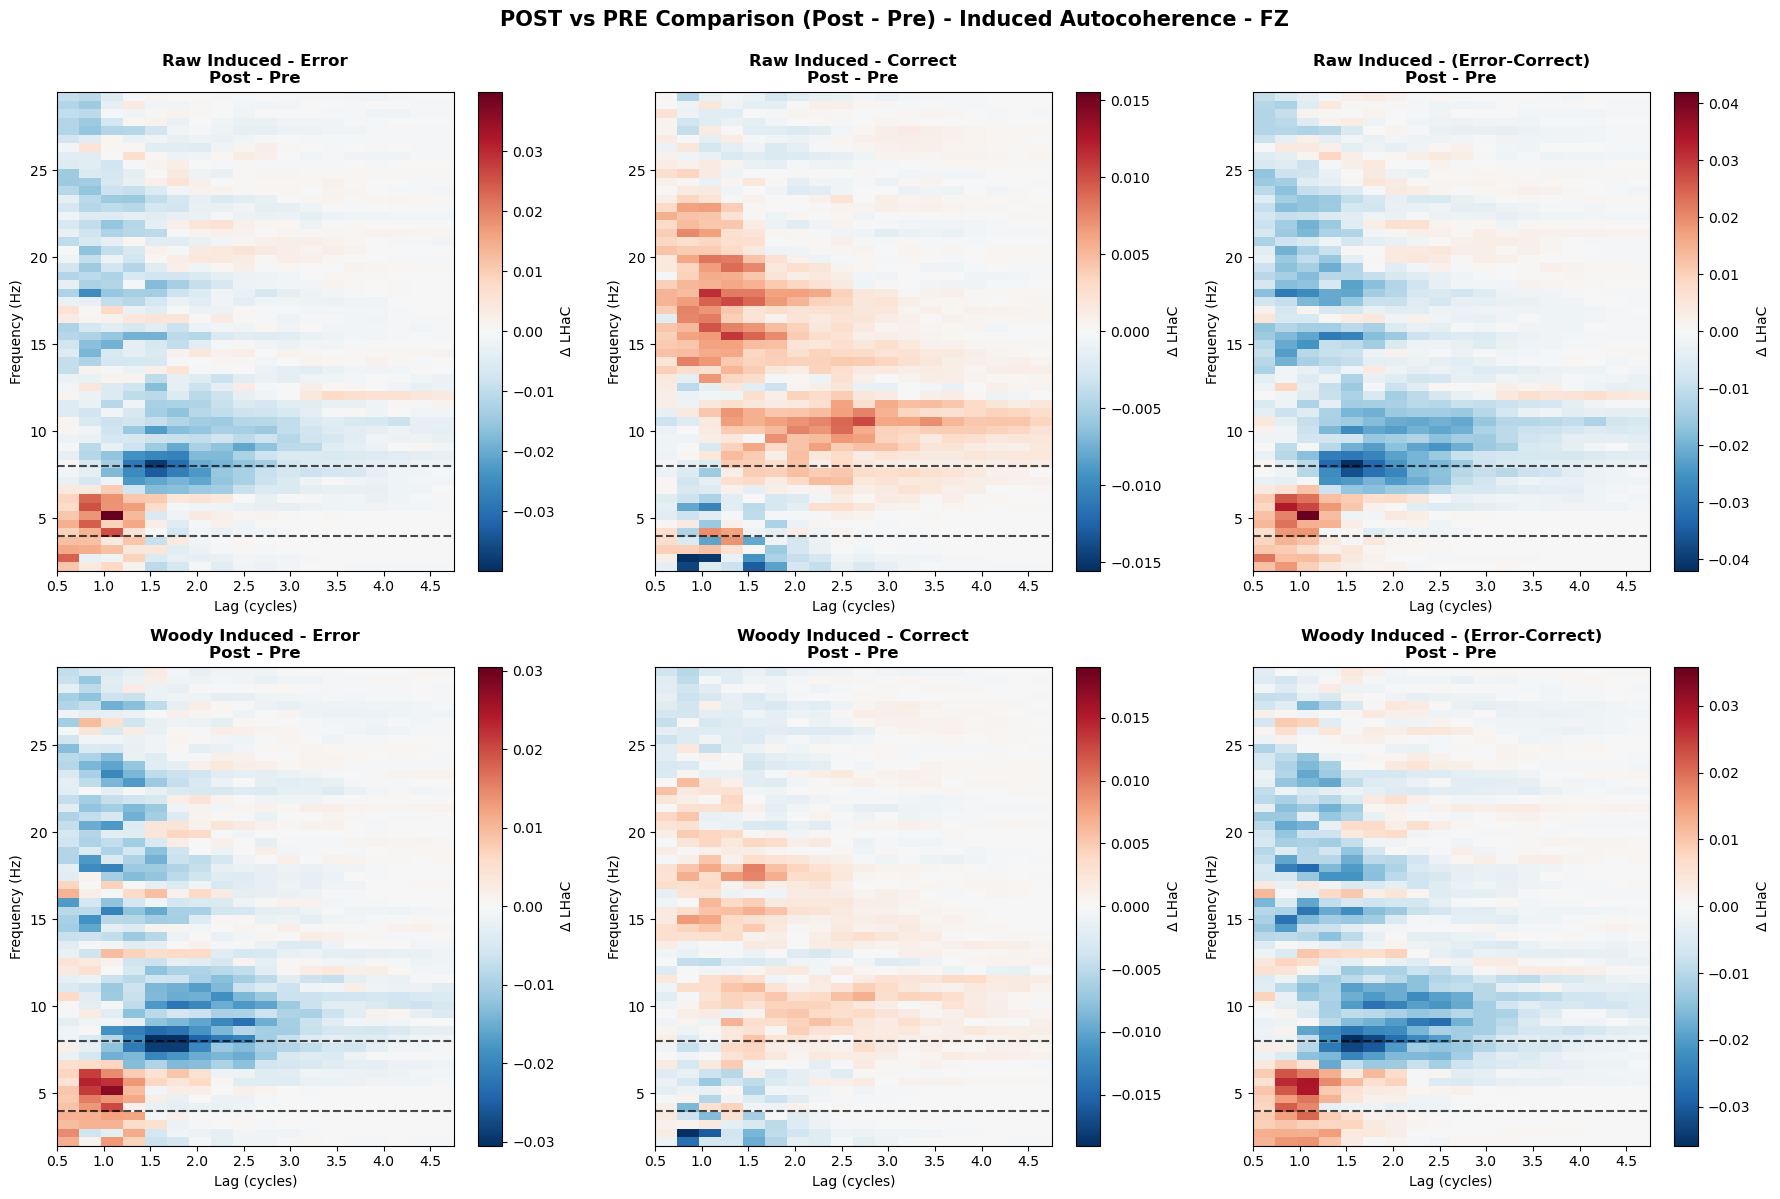

In [28]:
# ============================================================================
# PROCESS PRE-RESPONSE DATA
# ============================================================================

# Error
lcs_raw_error_pre = np.array([r['lcs_induced_raw'].mean(axis=0) for r in all_results_error_pre])
lcs_woody_error_pre = np.array([r['lcs_induced_woody'].mean(axis=0) for r in all_results_error_pre])
lhc_raw_error_pre = lcs_raw_error_pre.mean(axis=0)
lhc_woody_error_pre = lcs_woody_error_pre.mean(axis=0)

# Correct
lcs_raw_correct_pre = np.array([r['lcs_induced_raw'].mean(axis=0) for r in all_results_correct_pre])
lcs_woody_correct_pre = np.array([r['lcs_induced_woody'].mean(axis=0) for r in all_results_correct_pre])
lhc_raw_correct_pre = lcs_raw_correct_pre.mean(axis=0)
lhc_woody_correct_pre = lcs_woody_correct_pre.mean(axis=0)

# Differences
lhc_raw_diff_pre = lhc_raw_error_pre - lhc_raw_correct_pre
lhc_woody_diff_pre = lhc_woody_error_pre - lhc_woody_correct_pre

# ============================================================================
# PROCESS POST-RESPONSE DATA
# ============================================================================

# Error
lcs_raw_error_post = np.array([r['lcs_induced_raw'].mean(axis=0) for r in all_results_error_post])
lcs_woody_error_post = np.array([r['lcs_induced_woody'].mean(axis=0) for r in all_results_error_post])
lhc_raw_error_post = lcs_raw_error_post.mean(axis=0)
lhc_woody_error_post = lcs_woody_error_post.mean(axis=0)

# Correct
lcs_raw_correct_post = np.array([r['lcs_induced_raw'].mean(axis=0) for r in all_results_correct_post])
lcs_woody_correct_post = np.array([r['lcs_induced_woody'].mean(axis=0) for r in all_results_correct_post])
lhc_raw_correct_post = lcs_raw_correct_post.mean(axis=0)
lhc_woody_correct_post = lcs_woody_correct_post.mean(axis=0)

# Differences
lhc_raw_diff_post = lhc_raw_error_post - lhc_raw_correct_post
lhc_woody_diff_post = lhc_woody_error_post - lhc_woody_correct_post

# ============================================================================
# COMPUTE POST vs PRE DIFFERENCES (POST - PRE)
# ============================================================================

# Raw Induced differences
lhc_raw_error_postpre = lhc_raw_error_post - lhc_raw_error_pre
lhc_raw_correct_postpre = lhc_raw_correct_post - lhc_raw_correct_pre
lhc_raw_diff_postpre = lhc_raw_diff_post - lhc_raw_diff_pre

# Woody Induced differences
lhc_woody_error_postpre = lhc_woody_error_post - lhc_woody_error_pre
lhc_woody_correct_postpre = lhc_woody_correct_post - lhc_woody_correct_pre
lhc_woody_diff_postpre = lhc_woody_diff_post - lhc_woody_diff_pre

# ============================================================================
# PLOT PRE-RESPONSE
# ============================================================================

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

im1 = axes[0, 0].imshow(lhc_raw_error_pre, aspect='auto', origin='lower', cmap='plasma',
                         extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[0, 0].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 0].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 0].set_xlabel('Lag (cycles)')
axes[0, 0].set_ylabel('Frequency (Hz)')
axes[0, 0].set_title(f'Raw Induced - Error\nn={len(all_results_error_pre)}', fontweight='bold')
plt.colorbar(im1, ax=axes[0, 0], label='LHaC')

im2 = axes[0, 1].imshow(lhc_raw_correct_pre, aspect='auto', origin='lower', cmap='plasma',
                         extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[0, 1].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 1].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 1].set_xlabel('Lag (cycles)')
axes[0, 1].set_ylabel('Frequency (Hz)')
axes[0, 1].set_title(f'Raw Induced - Correct\nn={len(all_results_correct_pre)}', fontweight='bold')
plt.colorbar(im2, ax=axes[0, 1], label='LHaC')

im3 = axes[0, 2].imshow(lhc_raw_diff_pre, aspect='auto', origin='lower', cmap='RdBu_r',
                         extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]],
                         vmin=-np.abs(lhc_raw_diff_pre).max(), vmax=np.abs(lhc_raw_diff_pre).max())
axes[0, 2].axhline(4, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 2].axhline(8, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 2].set_xlabel('Lag (cycles)')
axes[0, 2].set_ylabel('Frequency (Hz)')
axes[0, 2].set_title('Raw Induced\nError - Correct', fontweight='bold')
plt.colorbar(im3, ax=axes[0, 2], label='Δ LHaC')

im4 = axes[1, 0].imshow(lhc_woody_error_pre, aspect='auto', origin='lower', cmap='plasma',
                         extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[1, 0].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1, 0].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1, 0].set_xlabel('Lag (cycles)')
axes[1, 0].set_ylabel('Frequency (Hz)')
axes[1, 0].set_title(f'Woody Induced - Error\nn={len(all_results_error_pre)}', fontweight='bold')
plt.colorbar(im4, ax=axes[1, 0], label='LHaC')

im5 = axes[1, 1].imshow(lhc_woody_correct_pre, aspect='auto', origin='lower', cmap='plasma',
                         extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[1, 1].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1, 1].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1, 1].set_xlabel('Lag (cycles)')
axes[1, 1].set_ylabel('Frequency (Hz)')
axes[1, 1].set_title(f'Woody Induced - Correct\nn={len(all_results_correct_pre)}', fontweight='bold')
plt.colorbar(im5, ax=axes[1, 1], label='LHaC')

im6 = axes[1, 2].imshow(lhc_woody_diff_pre, aspect='auto', origin='lower', cmap='RdBu_r',
                         extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]],
                         vmin=-np.abs(lhc_woody_diff_pre).max(), vmax=np.abs(lhc_woody_diff_pre).max())
axes[1, 2].axhline(4, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1, 2].axhline(8, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1, 2].set_xlabel('Lag (cycles)')
axes[1, 2].set_ylabel('Frequency (Hz)')
axes[1, 2].set_title('Woody Induced\nError - Correct', fontweight='bold')
plt.colorbar(im6, ax=axes[1, 2], label='Δ LHaC')

plt.suptitle('PRE-RESPONSE (-5 to 0 s) - Induced Autocoherence - FZ', fontsize=15, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

# ============================================================================
# PLOT POST-RESPONSE
# ============================================================================

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

im1 = axes[0, 0].imshow(lhc_raw_error_post, aspect='auto', origin='lower', cmap='plasma',
                         extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[0, 0].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 0].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 0].set_xlabel('Lag (cycles)')
axes[0, 0].set_ylabel('Frequency (Hz)')
axes[0, 0].set_title(f'Raw Induced - Error\nn={len(all_results_error_post)}', fontweight='bold')
plt.colorbar(im1, ax=axes[0, 0], label='LHaC')

im2 = axes[0, 1].imshow(lhc_raw_correct_post, aspect='auto', origin='lower', cmap='plasma',
                         extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[0, 1].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 1].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 1].set_xlabel('Lag (cycles)')
axes[0, 1].set_ylabel('Frequency (Hz)')
axes[0, 1].set_title(f'Raw Induced - Correct\nn={len(all_results_correct_post)}', fontweight='bold')
plt.colorbar(im2, ax=axes[0, 1], label='LHaC')

im3 = axes[0, 2].imshow(lhc_raw_diff_post, aspect='auto', origin='lower', cmap='RdBu_r',
                         extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]],
                         vmin=-np.abs(lhc_raw_diff_post).max(), vmax=np.abs(lhc_raw_diff_post).max())
axes[0, 2].axhline(4, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 2].axhline(8, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 2].set_xlabel('Lag (cycles)')
axes[0, 2].set_ylabel('Frequency (Hz)')
axes[0, 2].set_title('Raw Induced\nError - Correct', fontweight='bold')
plt.colorbar(im3, ax=axes[0, 2], label='Δ LHaC')

im4 = axes[1, 0].imshow(lhc_woody_error_post, aspect='auto', origin='lower', cmap='plasma',
                         extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[1, 0].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1, 0].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1, 0].set_xlabel('Lag (cycles)')
axes[1, 0].set_ylabel('Frequency (Hz)')
axes[1, 0].set_title(f'Woody Induced - Error\nn={len(all_results_error_post)}', fontweight='bold')
plt.colorbar(im4, ax=axes[1, 0], label='LHaC')

im5 = axes[1, 1].imshow(lhc_woody_correct_post, aspect='auto', origin='lower', cmap='plasma',
                         extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
axes[1, 1].axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1, 1].axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1, 1].set_xlabel('Lag (cycles)')
axes[1, 1].set_ylabel('Frequency (Hz)')
axes[1, 1].set_title(f'Woody Induced - Correct\nn={len(all_results_correct_post)}', fontweight='bold')
plt.colorbar(im5, ax=axes[1, 1], label='LHaC')

im6 = axes[1, 2].imshow(lhc_woody_diff_post, aspect='auto', origin='lower', cmap='RdBu_r',
                         extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]],
                         vmin=-np.abs(lhc_woody_diff_post).max(), vmax=np.abs(lhc_woody_diff_post).max())
axes[1, 2].axhline(4, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1, 2].axhline(8, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1, 2].set_xlabel('Lag (cycles)')
axes[1, 2].set_ylabel('Frequency (Hz)')
axes[1, 2].set_title('Woody Induced\nError - Correct', fontweight='bold')
plt.colorbar(im6, ax=axes[1, 2], label='Δ LHaC')

plt.suptitle('POST-RESPONSE (0 to +5 s) - Induced Autocoherence - FZ', fontsize=15, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

# ============================================================================
# PLOT POST vs PRE COMPARISON (POST - PRE)
# ============================================================================

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Row 1: Raw Induced
im1 = axes[0, 0].imshow(lhc_raw_error_postpre, aspect='auto', origin='lower', cmap='RdBu_r',
                         extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]],
                         vmin=-np.abs(lhc_raw_error_postpre).max(), vmax=np.abs(lhc_raw_error_postpre).max())
axes[0, 0].axhline(4, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 0].axhline(8, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 0].set_xlabel('Lag (cycles)')
axes[0, 0].set_ylabel('Frequency (Hz)')
axes[0, 0].set_title('Raw Induced - Error\nPost - Pre', fontweight='bold')
plt.colorbar(im1, ax=axes[0, 0], label='Δ LHaC')

im2 = axes[0, 1].imshow(lhc_raw_correct_postpre, aspect='auto', origin='lower', cmap='RdBu_r',
                         extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]],
                         vmin=-np.abs(lhc_raw_correct_postpre).max(), vmax=np.abs(lhc_raw_correct_postpre).max())
axes[0, 1].axhline(4, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 1].axhline(8, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 1].set_xlabel('Lag (cycles)')
axes[0, 1].set_ylabel('Frequency (Hz)')
axes[0, 1].set_title('Raw Induced - Correct\nPost - Pre', fontweight='bold')
plt.colorbar(im2, ax=axes[0, 1], label='Δ LHaC')

im3 = axes[0, 2].imshow(lhc_raw_diff_postpre, aspect='auto', origin='lower', cmap='RdBu_r',
                         extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]],
                         vmin=-np.abs(lhc_raw_diff_postpre).max(), vmax=np.abs(lhc_raw_diff_postpre).max())
axes[0, 2].axhline(4, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 2].axhline(8, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 2].set_xlabel('Lag (cycles)')
axes[0, 2].set_ylabel('Frequency (Hz)')
axes[0, 2].set_title('Raw Induced - (Error-Correct)\nPost - Pre', fontweight='bold')
plt.colorbar(im3, ax=axes[0, 2], label='Δ LHaC')

# Row 2: Woody Induced
im4 = axes[1, 0].imshow(lhc_woody_error_postpre, aspect='auto', origin='lower', cmap='RdBu_r',
                         extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]],
                         vmin=-np.abs(lhc_woody_error_postpre).max(), vmax=np.abs(lhc_woody_error_postpre).max())
axes[1, 0].axhline(4, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1, 0].axhline(8, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1, 0].set_xlabel('Lag (cycles)')
axes[1, 0].set_ylabel('Frequency (Hz)')
axes[1, 0].set_title('Woody Induced - Error\nPost - Pre', fontweight='bold')
plt.colorbar(im4, ax=axes[1, 0], label='Δ LHaC')

im5 = axes[1, 1].imshow(lhc_woody_correct_postpre, aspect='auto', origin='lower', cmap='RdBu_r',
                         extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]],
                         vmin=-np.abs(lhc_woody_correct_postpre).max(), vmax=np.abs(lhc_woody_correct_postpre).max())
axes[1, 1].axhline(4, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1, 1].axhline(8, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1, 1].set_xlabel('Lag (cycles)')
axes[1, 1].set_ylabel('Frequency (Hz)')
axes[1, 1].set_title('Woody Induced - Correct\nPost - Pre', fontweight='bold')
plt.colorbar(im5, ax=axes[1, 1], label='Δ LHaC')

im6 = axes[1, 2].imshow(lhc_woody_diff_postpre, aspect='auto', origin='lower', cmap='RdBu_r',
                         extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]],
                         vmin=-np.abs(lhc_woody_diff_postpre).max(), vmax=np.abs(lhc_woody_diff_postpre).max())
axes[1, 2].axhline(4, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1, 2].axhline(8, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1, 2].set_xlabel('Lag (cycles)')
axes[1, 2].set_ylabel('Frequency (Hz)')
axes[1, 2].set_title('Woody Induced - (Error-Correct)\nPost - Pre', fontweight='bold')
plt.colorbar(im6, ax=axes[1, 2], label='Δ LHaC')

plt.suptitle('POST vs PRE Comparison (Post - Pre) - Induced Autocoherence - FZ', fontsize=15, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

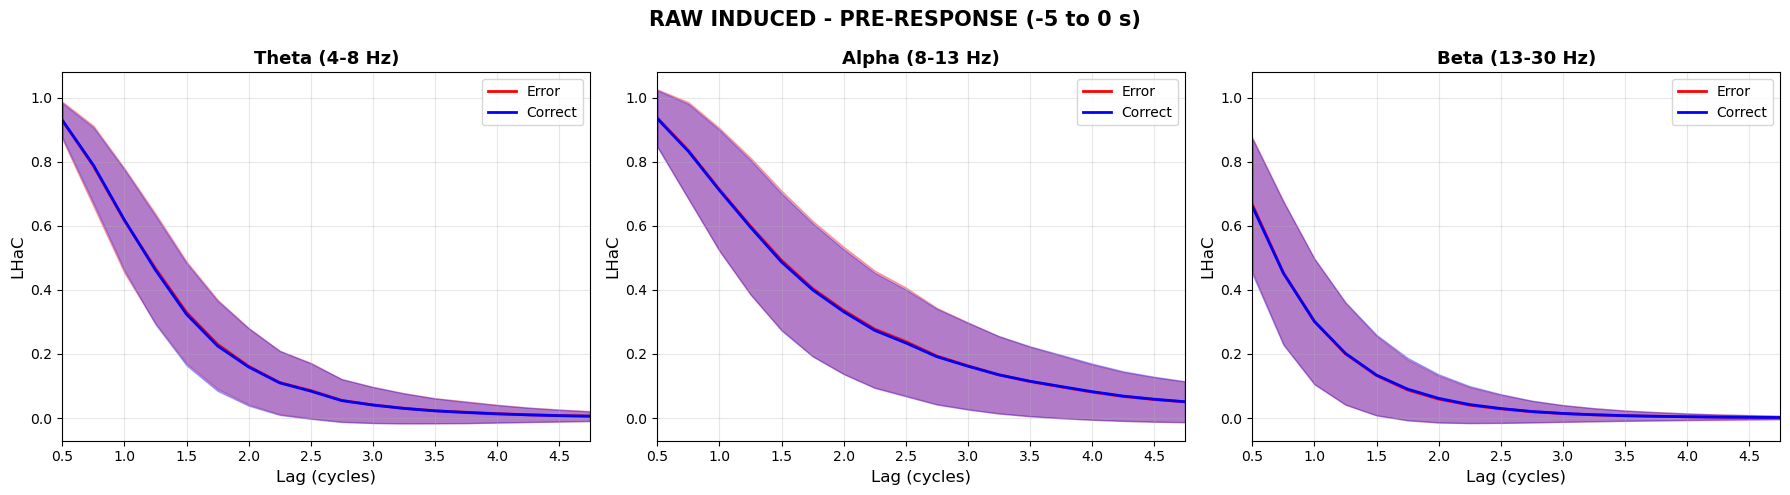

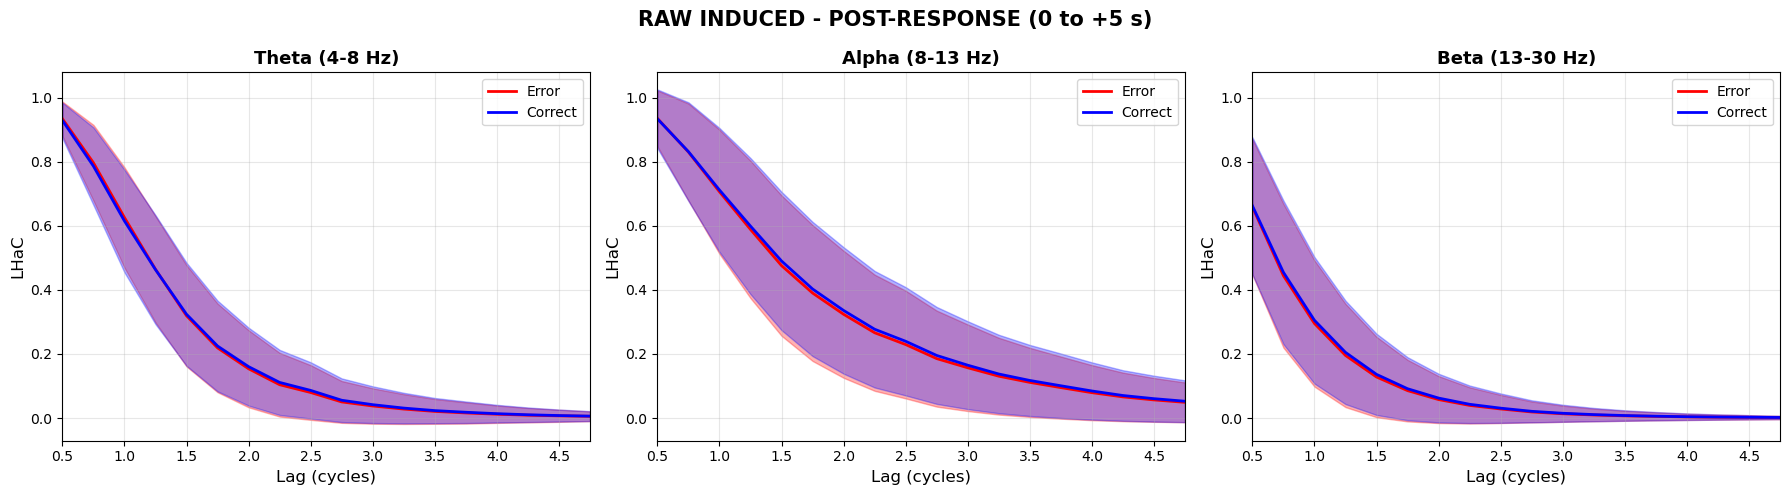

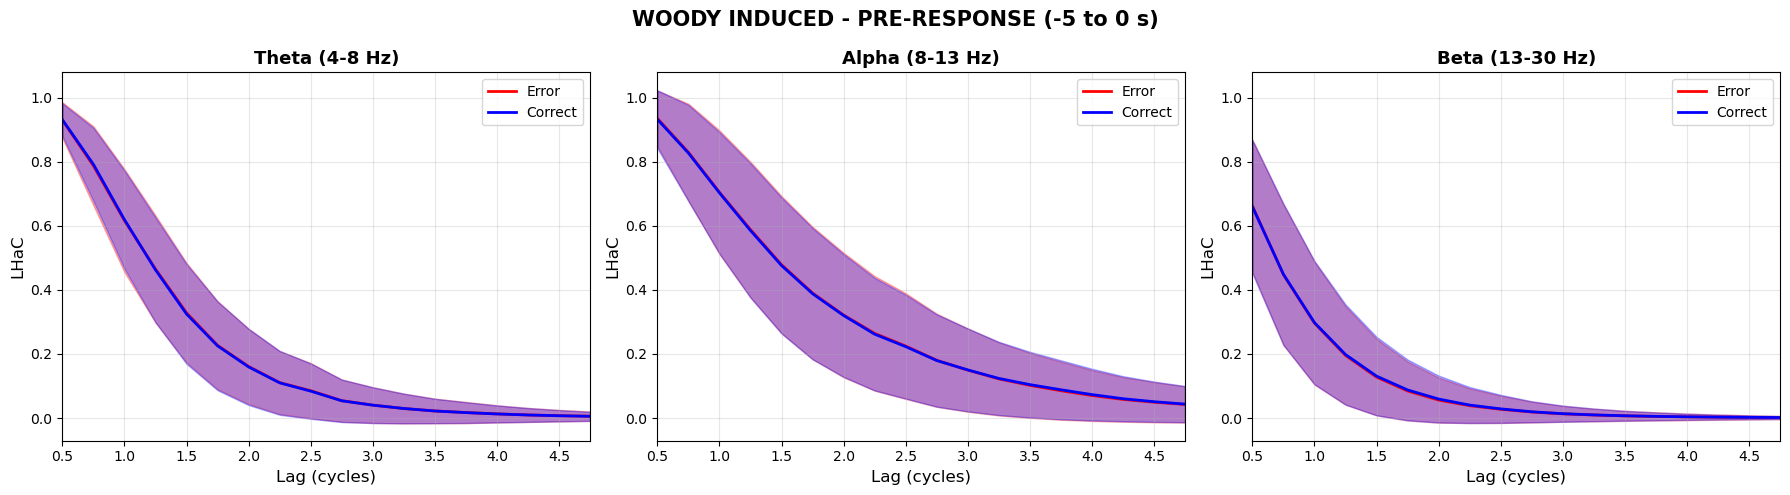

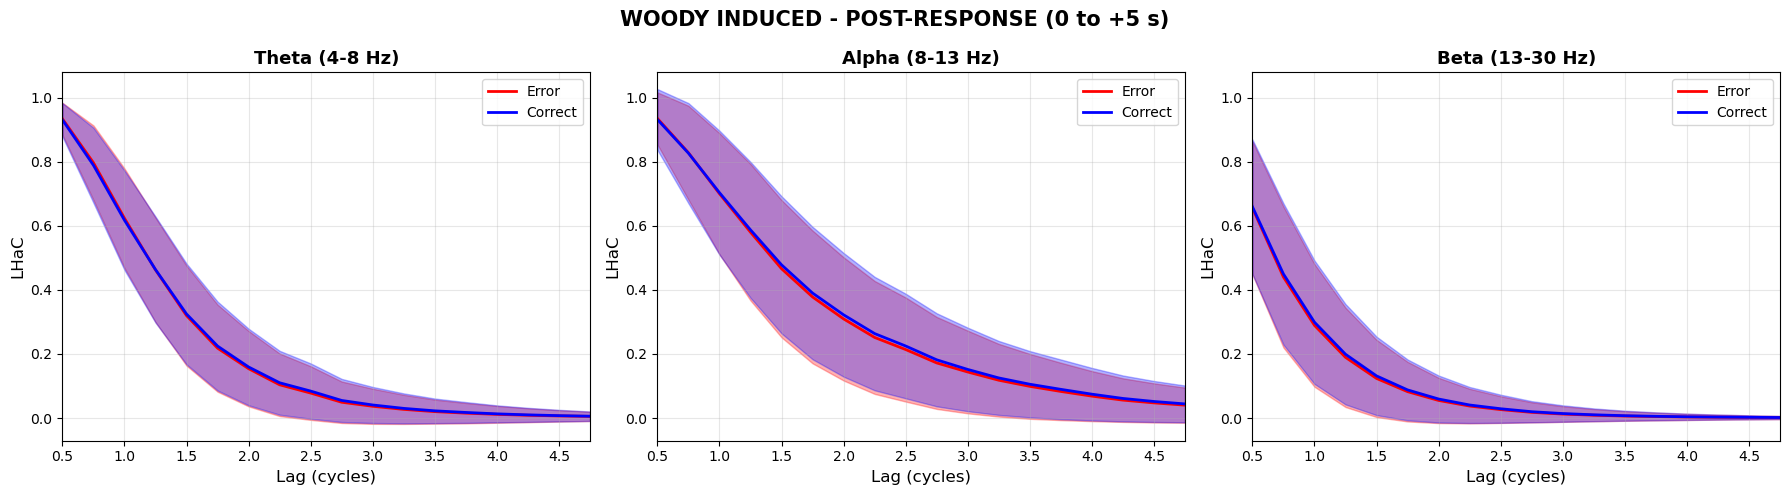

In [30]:
# ============================================================================
# EXTRACT BAND-AVERAGED DATA WITH SD
# ============================================================================

# Define frequency bands
theta_mask = (freqs_range >= 4) & (freqs_range <= 8)
alpha_mask = (freqs_range >= 8) & (freqs_range <= 13)
beta_mask = (freqs_range >= 13) & (freqs_range <= 30)

# PRE-RESPONSE - Extract single-subject data averaged over frequency bands
# Error - Raw
theta_raw_error_pre_subj = np.array([r['lcs_induced_raw'].mean(axis=0)[theta_mask, :].mean(axis=0) for r in all_results_error_pre])
alpha_raw_error_pre_subj = np.array([r['lcs_induced_raw'].mean(axis=0)[alpha_mask, :].mean(axis=0) for r in all_results_error_pre])
beta_raw_error_pre_subj = np.array([r['lcs_induced_raw'].mean(axis=0)[beta_mask, :].mean(axis=0) for r in all_results_error_pre])

# Correct - Raw
theta_raw_correct_pre_subj = np.array([r['lcs_induced_raw'].mean(axis=0)[theta_mask, :].mean(axis=0) for r in all_results_correct_pre])
alpha_raw_correct_pre_subj = np.array([r['lcs_induced_raw'].mean(axis=0)[alpha_mask, :].mean(axis=0) for r in all_results_correct_pre])
beta_raw_correct_pre_subj = np.array([r['lcs_induced_raw'].mean(axis=0)[beta_mask, :].mean(axis=0) for r in all_results_correct_pre])

# Error - Woody
theta_woody_error_pre_subj = np.array([r['lcs_induced_woody'].mean(axis=0)[theta_mask, :].mean(axis=0) for r in all_results_error_pre])
alpha_woody_error_pre_subj = np.array([r['lcs_induced_woody'].mean(axis=0)[alpha_mask, :].mean(axis=0) for r in all_results_error_pre])
beta_woody_error_pre_subj = np.array([r['lcs_induced_woody'].mean(axis=0)[beta_mask, :].mean(axis=0) for r in all_results_error_pre])

# Correct - Woody
theta_woody_correct_pre_subj = np.array([r['lcs_induced_woody'].mean(axis=0)[theta_mask, :].mean(axis=0) for r in all_results_correct_pre])
alpha_woody_correct_pre_subj = np.array([r['lcs_induced_woody'].mean(axis=0)[alpha_mask, :].mean(axis=0) for r in all_results_correct_pre])
beta_woody_correct_pre_subj = np.array([r['lcs_induced_woody'].mean(axis=0)[beta_mask, :].mean(axis=0) for r in all_results_correct_pre])

# POST-RESPONSE - Extract single-subject data averaged over frequency bands
# Error - Raw
theta_raw_error_post_subj = np.array([r['lcs_induced_raw'].mean(axis=0)[theta_mask, :].mean(axis=0) for r in all_results_error_post])
alpha_raw_error_post_subj = np.array([r['lcs_induced_raw'].mean(axis=0)[alpha_mask, :].mean(axis=0) for r in all_results_error_post])
beta_raw_error_post_subj = np.array([r['lcs_induced_raw'].mean(axis=0)[beta_mask, :].mean(axis=0) for r in all_results_error_post])

# Correct - Raw
theta_raw_correct_post_subj = np.array([r['lcs_induced_raw'].mean(axis=0)[theta_mask, :].mean(axis=0) for r in all_results_correct_post])
alpha_raw_correct_post_subj = np.array([r['lcs_induced_raw'].mean(axis=0)[alpha_mask, :].mean(axis=0) for r in all_results_correct_post])
beta_raw_correct_post_subj = np.array([r['lcs_induced_raw'].mean(axis=0)[beta_mask, :].mean(axis=0) for r in all_results_correct_post])

# Error - Woody
theta_woody_error_post_subj = np.array([r['lcs_induced_woody'].mean(axis=0)[theta_mask, :].mean(axis=0) for r in all_results_error_post])
alpha_woody_error_post_subj = np.array([r['lcs_induced_woody'].mean(axis=0)[alpha_mask, :].mean(axis=0) for r in all_results_error_post])
beta_woody_error_post_subj = np.array([r['lcs_induced_woody'].mean(axis=0)[beta_mask, :].mean(axis=0) for r in all_results_error_post])

# Correct - Woody
theta_woody_correct_post_subj = np.array([r['lcs_induced_woody'].mean(axis=0)[theta_mask, :].mean(axis=0) for r in all_results_correct_post])
alpha_woody_correct_post_subj = np.array([r['lcs_induced_woody'].mean(axis=0)[alpha_mask, :].mean(axis=0) for r in all_results_correct_post])
beta_woody_correct_post_subj = np.array([r['lcs_induced_woody'].mean(axis=0)[beta_mask, :].mean(axis=0) for r in all_results_correct_post])

# ============================================================================
# CALCULATE GLOBAL Y-AXIS LIMITS
# ============================================================================

# Collect all data to find global min/max
all_data = []

# Raw Pre
all_data.extend([theta_raw_error_pre_subj, alpha_raw_error_pre_subj, beta_raw_error_pre_subj,
                 theta_raw_correct_pre_subj, alpha_raw_correct_pre_subj, beta_raw_correct_pre_subj])

# Raw Post
all_data.extend([theta_raw_error_post_subj, alpha_raw_error_post_subj, beta_raw_error_post_subj,
                 theta_raw_correct_post_subj, alpha_raw_correct_post_subj, beta_raw_correct_post_subj])

# Woody Pre
all_data.extend([theta_woody_error_pre_subj, alpha_woody_error_pre_subj, beta_woody_error_pre_subj,
                 theta_woody_correct_pre_subj, alpha_woody_correct_pre_subj, beta_woody_correct_pre_subj])

# Woody Post
all_data.extend([theta_woody_error_post_subj, alpha_woody_error_post_subj, beta_woody_error_post_subj,
                 theta_woody_correct_post_subj, alpha_woody_correct_post_subj, beta_woody_correct_post_subj])

# Calculate global limits (mean ± std)
y_min = min([np.min(d.mean(axis=0) - d.std(axis=0)) for d in all_data])
y_max = max([np.max(d.mean(axis=0) + d.std(axis=0)) for d in all_data])

# Add some padding
y_range = y_max - y_min
y_min -= 0.05 * y_range
y_max += 0.05 * y_range

# X-axis limits
x_min = lags_range[0]
x_max = lags_range[-1]

# ============================================================================
# PLOT RAW INDUCED - PRE-RESPONSE
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Theta
axes[0].plot(lags_range, theta_raw_error_pre_subj.mean(axis=0), 'r-', linewidth=2, label='Error')
axes[0].fill_between(lags_range, 
                      theta_raw_error_pre_subj.mean(axis=0) - theta_raw_error_pre_subj.std(axis=0),
                      theta_raw_error_pre_subj.mean(axis=0) + theta_raw_error_pre_subj.std(axis=0),
                      color='r', alpha=0.3)
axes[0].plot(lags_range, theta_raw_correct_pre_subj.mean(axis=0), 'b-', linewidth=2, label='Correct')
axes[0].fill_between(lags_range,
                      theta_raw_correct_pre_subj.mean(axis=0) - theta_raw_correct_pre_subj.std(axis=0),
                      theta_raw_correct_pre_subj.mean(axis=0) + theta_raw_correct_pre_subj.std(axis=0),
                      color='b', alpha=0.3)
axes[0].set_xlabel('Lag (cycles)', fontsize=12)
axes[0].set_ylabel('LHaC', fontsize=12)
axes[0].set_title('Theta (4-8 Hz)', fontsize=13, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[0].set_xlim([x_min, x_max])
axes[0].set_ylim([y_min, y_max])

# Alpha
axes[1].plot(lags_range, alpha_raw_error_pre_subj.mean(axis=0), 'r-', linewidth=2, label='Error')
axes[1].fill_between(lags_range,
                      alpha_raw_error_pre_subj.mean(axis=0) - alpha_raw_error_pre_subj.std(axis=0),
                      alpha_raw_error_pre_subj.mean(axis=0) + alpha_raw_error_pre_subj.std(axis=0),
                      color='r', alpha=0.3)
axes[1].plot(lags_range, alpha_raw_correct_pre_subj.mean(axis=0), 'b-', linewidth=2, label='Correct')
axes[1].fill_between(lags_range,
                      alpha_raw_correct_pre_subj.mean(axis=0) - alpha_raw_correct_pre_subj.std(axis=0),
                      alpha_raw_correct_pre_subj.mean(axis=0) + alpha_raw_correct_pre_subj.std(axis=0),
                      color='b', alpha=0.3)
axes[1].set_xlabel('Lag (cycles)', fontsize=12)
axes[1].set_ylabel('LHaC', fontsize=12)
axes[1].set_title('Alpha (8-13 Hz)', fontsize=13, fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)
axes[1].set_xlim([x_min, x_max])
axes[1].set_ylim([y_min, y_max])

# Beta
axes[2].plot(lags_range, beta_raw_error_pre_subj.mean(axis=0), 'r-', linewidth=2, label='Error')
axes[2].fill_between(lags_range,
                      beta_raw_error_pre_subj.mean(axis=0) - beta_raw_error_pre_subj.std(axis=0),
                      beta_raw_error_pre_subj.mean(axis=0) + beta_raw_error_pre_subj.std(axis=0),
                      color='r', alpha=0.3)
axes[2].plot(lags_range, beta_raw_correct_pre_subj.mean(axis=0), 'b-', linewidth=2, label='Correct')
axes[2].fill_between(lags_range,
                      beta_raw_correct_pre_subj.mean(axis=0) - beta_raw_correct_pre_subj.std(axis=0),
                      beta_raw_correct_pre_subj.mean(axis=0) + beta_raw_correct_pre_subj.std(axis=0),
                      color='b', alpha=0.3)
axes[2].set_xlabel('Lag (cycles)', fontsize=12)
axes[2].set_ylabel('LHaC', fontsize=12)
axes[2].set_title('Beta (13-30 Hz)', fontsize=13, fontweight='bold')
axes[2].legend()
axes[2].grid(alpha=0.3)
axes[2].set_xlim([x_min, x_max])
axes[2].set_ylim([y_min, y_max])

plt.suptitle('RAW INDUCED - PRE-RESPONSE (-5 to 0 s)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

# ============================================================================
# PLOT RAW INDUCED - POST-RESPONSE
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Theta
axes[0].plot(lags_range, theta_raw_error_post_subj.mean(axis=0), 'r-', linewidth=2, label='Error')
axes[0].fill_between(lags_range,
                      theta_raw_error_post_subj.mean(axis=0) - theta_raw_error_post_subj.std(axis=0),
                      theta_raw_error_post_subj.mean(axis=0) + theta_raw_error_post_subj.std(axis=0),
                      color='r', alpha=0.3)
axes[0].plot(lags_range, theta_raw_correct_post_subj.mean(axis=0), 'b-', linewidth=2, label='Correct')
axes[0].fill_between(lags_range,
                      theta_raw_correct_post_subj.mean(axis=0) - theta_raw_correct_post_subj.std(axis=0),
                      theta_raw_correct_post_subj.mean(axis=0) + theta_raw_correct_post_subj.std(axis=0),
                      color='b', alpha=0.3)
axes[0].set_xlabel('Lag (cycles)', fontsize=12)
axes[0].set_ylabel('LHaC', fontsize=12)
axes[0].set_title('Theta (4-8 Hz)', fontsize=13, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[0].set_xlim([x_min, x_max])
axes[0].set_ylim([y_min, y_max])

# Alpha
axes[1].plot(lags_range, alpha_raw_error_post_subj.mean(axis=0), 'r-', linewidth=2, label='Error')
axes[1].fill_between(lags_range,
                      alpha_raw_error_post_subj.mean(axis=0) - alpha_raw_error_post_subj.std(axis=0),
                      alpha_raw_error_post_subj.mean(axis=0) + alpha_raw_error_post_subj.std(axis=0),
                      color='r', alpha=0.3)
axes[1].plot(lags_range, alpha_raw_correct_post_subj.mean(axis=0), 'b-', linewidth=2, label='Correct')
axes[1].fill_between(lags_range,
                      alpha_raw_correct_post_subj.mean(axis=0) - alpha_raw_correct_post_subj.std(axis=0),
                      alpha_raw_correct_post_subj.mean(axis=0) + alpha_raw_correct_post_subj.std(axis=0),
                      color='b', alpha=0.3)
axes[1].set_xlabel('Lag (cycles)', fontsize=12)
axes[1].set_ylabel('LHaC', fontsize=12)
axes[1].set_title('Alpha (8-13 Hz)', fontsize=13, fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)
axes[1].set_xlim([x_min, x_max])
axes[1].set_ylim([y_min, y_max])

# Beta
axes[2].plot(lags_range, beta_raw_error_post_subj.mean(axis=0), 'r-', linewidth=2, label='Error')
axes[2].fill_between(lags_range,
                      beta_raw_error_post_subj.mean(axis=0) - beta_raw_error_post_subj.std(axis=0),
                      beta_raw_error_post_subj.mean(axis=0) + beta_raw_error_post_subj.std(axis=0),
                      color='r', alpha=0.3)
axes[2].plot(lags_range, beta_raw_correct_post_subj.mean(axis=0), 'b-', linewidth=2, label='Correct')
axes[2].fill_between(lags_range,
                      beta_raw_correct_post_subj.mean(axis=0) - beta_raw_correct_post_subj.std(axis=0),
                      beta_raw_correct_post_subj.mean(axis=0) + beta_raw_correct_post_subj.std(axis=0),
                      color='b', alpha=0.3)
axes[2].set_xlabel('Lag (cycles)', fontsize=12)
axes[2].set_ylabel('LHaC', fontsize=12)
axes[2].set_title('Beta (13-30 Hz)', fontsize=13, fontweight='bold')
axes[2].legend()
axes[2].grid(alpha=0.3)
axes[2].set_xlim([x_min, x_max])
axes[2].set_ylim([y_min, y_max])

plt.suptitle('RAW INDUCED - POST-RESPONSE (0 to +5 s)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

# ============================================================================
# PLOT WOODY INDUCED - PRE-RESPONSE
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Theta
axes[0].plot(lags_range, theta_woody_error_pre_subj.mean(axis=0), 'r-', linewidth=2, label='Error')
axes[0].fill_between(lags_range,
                      theta_woody_error_pre_subj.mean(axis=0) - theta_woody_error_pre_subj.std(axis=0),
                      theta_woody_error_pre_subj.mean(axis=0) + theta_woody_error_pre_subj.std(axis=0),
                      color='r', alpha=0.3)
axes[0].plot(lags_range, theta_woody_correct_pre_subj.mean(axis=0), 'b-', linewidth=2, label='Correct')
axes[0].fill_between(lags_range,
                      theta_woody_correct_pre_subj.mean(axis=0) - theta_woody_correct_pre_subj.std(axis=0),
                      theta_woody_correct_pre_subj.mean(axis=0) + theta_woody_correct_pre_subj.std(axis=0),
                      color='b', alpha=0.3)
axes[0].set_xlabel('Lag (cycles)', fontsize=12)
axes[0].set_ylabel('LHaC', fontsize=12)
axes[0].set_title('Theta (4-8 Hz)', fontsize=13, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[0].set_xlim([x_min, x_max])
axes[0].set_ylim([y_min, y_max])

# Alpha
axes[1].plot(lags_range, alpha_woody_error_pre_subj.mean(axis=0), 'r-', linewidth=2, label='Error')
axes[1].fill_between(lags_range,
                      alpha_woody_error_pre_subj.mean(axis=0) - alpha_woody_error_pre_subj.std(axis=0),
                      alpha_woody_error_pre_subj.mean(axis=0) + alpha_woody_error_pre_subj.std(axis=0),
                      color='r', alpha=0.3)
axes[1].plot(lags_range, alpha_woody_correct_pre_subj.mean(axis=0), 'b-', linewidth=2, label='Correct')
axes[1].fill_between(lags_range,
                      alpha_woody_correct_pre_subj.mean(axis=0) - alpha_woody_correct_pre_subj.std(axis=0),
                      alpha_woody_correct_pre_subj.mean(axis=0) + alpha_woody_correct_pre_subj.std(axis=0),
                      color='b', alpha=0.3)
axes[1].set_xlabel('Lag (cycles)', fontsize=12)
axes[1].set_ylabel('LHaC', fontsize=12)
axes[1].set_title('Alpha (8-13 Hz)', fontsize=13, fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)
axes[1].set_xlim([x_min, x_max])
axes[1].set_ylim([y_min, y_max])

# Beta
axes[2].plot(lags_range, beta_woody_error_pre_subj.mean(axis=0), 'r-', linewidth=2, label='Error')
axes[2].fill_between(lags_range,
                      beta_woody_error_pre_subj.mean(axis=0) - beta_woody_error_pre_subj.std(axis=0),
                      beta_woody_error_pre_subj.mean(axis=0) + beta_woody_error_pre_subj.std(axis=0),
                      color='r', alpha=0.3)
axes[2].plot(lags_range, beta_woody_correct_pre_subj.mean(axis=0), 'b-', linewidth=2, label='Correct')
axes[2].fill_between(lags_range,
                      beta_woody_correct_pre_subj.mean(axis=0) - beta_woody_correct_pre_subj.std(axis=0),
                      beta_woody_correct_pre_subj.mean(axis=0) + beta_woody_correct_pre_subj.std(axis=0),
                      color='b', alpha=0.3)
axes[2].set_xlabel('Lag (cycles)', fontsize=12)
axes[2].set_ylabel('LHaC', fontsize=12)
axes[2].set_title('Beta (13-30 Hz)', fontsize=13, fontweight='bold')
axes[2].legend()
axes[2].grid(alpha=0.3)
axes[2].set_xlim([x_min, x_max])
axes[2].set_ylim([y_min, y_max])

plt.suptitle('WOODY INDUCED - PRE-RESPONSE (-5 to 0 s)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

# ============================================================================
# PLOT WOODY INDUCED - POST-RESPONSE
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Theta
axes[0].plot(lags_range, theta_woody_error_post_subj.mean(axis=0), 'r-', linewidth=2, label='Error')
axes[0].fill_between(lags_range,
                      theta_woody_error_post_subj.mean(axis=0) - theta_woody_error_post_subj.std(axis=0),
                      theta_woody_error_post_subj.mean(axis=0) + theta_woody_error_post_subj.std(axis=0),
                      color='r', alpha=0.3)
axes[0].plot(lags_range, theta_woody_correct_post_subj.mean(axis=0), 'b-', linewidth=2, label='Correct')
axes[0].fill_between(lags_range,
                      theta_woody_correct_post_subj.mean(axis=0) - theta_woody_correct_post_subj.std(axis=0),
                      theta_woody_correct_post_subj.mean(axis=0) + theta_woody_correct_post_subj.std(axis=0),
                      color='b', alpha=0.3)
axes[0].set_xlabel('Lag (cycles)', fontsize=12)
axes[0].set_ylabel('LHaC', fontsize=12)
axes[0].set_title('Theta (4-8 Hz)', fontsize=13, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[0].set_xlim([x_min, x_max])
axes[0].set_ylim([y_min, y_max])

# Alpha
axes[1].plot(lags_range, alpha_woody_error_post_subj.mean(axis=0), 'r-', linewidth=2, label='Error')
axes[1].fill_between(lags_range,
                      alpha_woody_error_post_subj.mean(axis=0) - alpha_woody_error_post_subj.std(axis=0),
                      alpha_woody_error_post_subj.mean(axis=0) + alpha_woody_error_post_subj.std(axis=0),
                      color='r', alpha=0.3)
axes[1].plot(lags_range, alpha_woody_correct_post_subj.mean(axis=0), 'b-', linewidth=2, label='Correct')
axes[1].fill_between(lags_range,
                      alpha_woody_correct_post_subj.mean(axis=0) - alpha_woody_correct_post_subj.std(axis=0),
                      alpha_woody_correct_post_subj.mean(axis=0) + alpha_woody_correct_post_subj.std(axis=0),
                      color='b', alpha=0.3)
axes[1].set_xlabel('Lag (cycles)', fontsize=12)
axes[1].set_ylabel('LHaC', fontsize=12)
axes[1].set_title('Alpha (8-13 Hz)', fontsize=13, fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)
axes[1].set_xlim([x_min, x_max])
axes[1].set_ylim([y_min, y_max])

# Beta
axes[2].plot(lags_range, beta_woody_error_post_subj.mean(axis=0), 'r-', linewidth=2, label='Error')
axes[2].fill_between(lags_range,
                      beta_woody_error_post_subj.mean(axis=0) - beta_woody_error_post_subj.std(axis=0),
                      beta_woody_error_post_subj.mean(axis=0) + beta_woody_error_post_subj.std(axis=0),
                      color='r', alpha=0.3)
axes[2].plot(lags_range, beta_woody_correct_post_subj.mean(axis=0), 'b-', linewidth=2, label='Correct')
axes[2].fill_between(lags_range,
                      beta_woody_correct_post_subj.mean(axis=0) - beta_woody_correct_post_subj.std(axis=0),
                      beta_woody_correct_post_subj.mean(axis=0) + beta_woody_correct_post_subj.std(axis=0),
                      color='b', alpha=0.3)
axes[2].set_xlabel('Lag (cycles)', fontsize=12)
axes[2].set_ylabel('LHaC', fontsize=12)
axes[2].set_title('Beta (13-30 Hz)', fontsize=13, fontweight='bold')
axes[2].legend()
axes[2].grid(alpha=0.3)
axes[2].set_xlim([x_min, x_max])
axes[2].set_ylim([y_min, y_max])

plt.suptitle('WOODY INDUCED - POST-RESPONSE (0 to +5 s)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

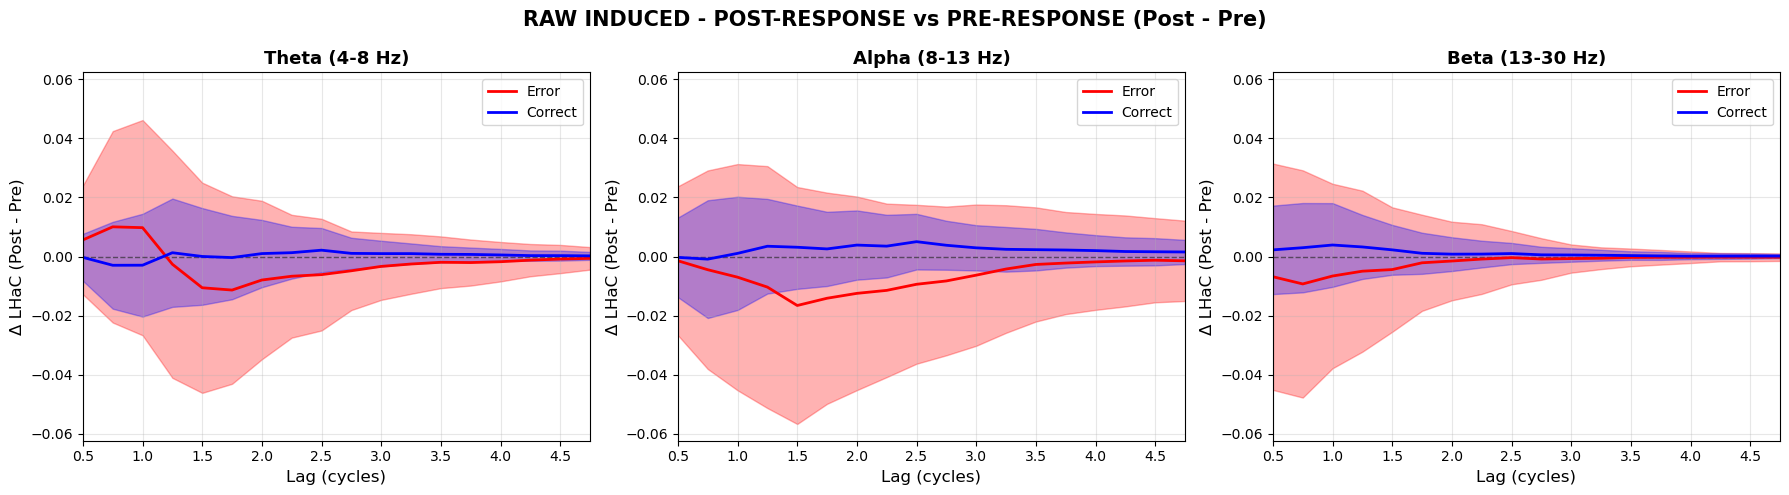

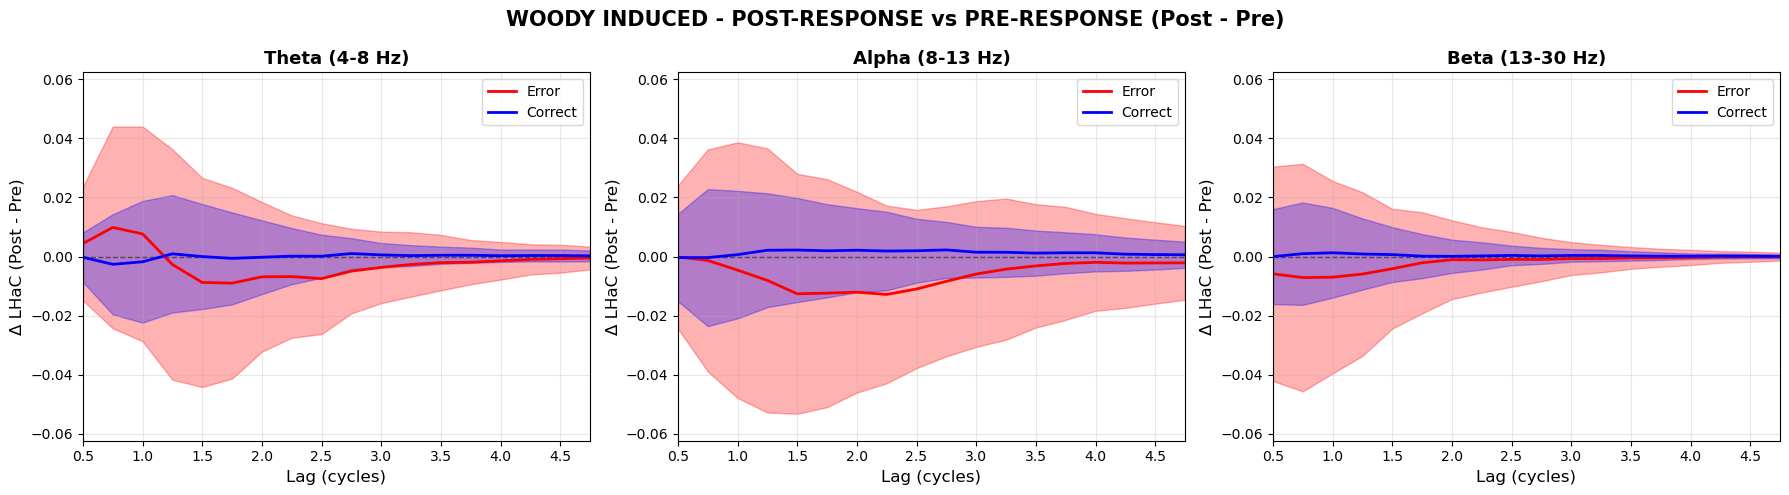

In [31]:
# ============================================================================
# COMPUTE POST - PRE DIFFERENCES
# ============================================================================

# Raw Induced - Error (post - pre)
theta_raw_error_postpre_subj = theta_raw_error_post_subj - theta_raw_error_pre_subj
alpha_raw_error_postpre_subj = alpha_raw_error_post_subj - alpha_raw_error_pre_subj
beta_raw_error_postpre_subj = beta_raw_error_post_subj - beta_raw_error_pre_subj

# Raw Induced - Correct (post - pre)
theta_raw_correct_postpre_subj = theta_raw_correct_post_subj - theta_raw_correct_pre_subj
alpha_raw_correct_postpre_subj = alpha_raw_correct_post_subj - alpha_raw_correct_pre_subj
beta_raw_correct_postpre_subj = beta_raw_correct_post_subj - beta_raw_correct_pre_subj

# Woody Induced - Error (post - pre)
theta_woody_error_postpre_subj = theta_woody_error_post_subj - theta_woody_error_pre_subj
alpha_woody_error_postpre_subj = alpha_woody_error_post_subj - alpha_woody_error_pre_subj
beta_woody_error_postpre_subj = beta_woody_error_post_subj - beta_woody_error_pre_subj

# Woody Induced - Correct (post - pre)
theta_woody_correct_postpre_subj = theta_woody_correct_post_subj - theta_woody_correct_pre_subj
alpha_woody_correct_postpre_subj = alpha_woody_correct_post_subj - alpha_woody_correct_pre_subj
beta_woody_correct_postpre_subj = beta_woody_correct_post_subj - beta_woody_correct_pre_subj

# ============================================================================
# CALCULATE Y-AXIS LIMITS FOR DIFFERENCE PLOTS
# ============================================================================

# Collect all difference data
all_diff_data = [
    theta_raw_error_postpre_subj, alpha_raw_error_postpre_subj, beta_raw_error_postpre_subj,
    theta_raw_correct_postpre_subj, alpha_raw_correct_postpre_subj, beta_raw_correct_postpre_subj,
    theta_woody_error_postpre_subj, alpha_woody_error_postpre_subj, beta_woody_error_postpre_subj,
    theta_woody_correct_postpre_subj, alpha_woody_correct_postpre_subj, beta_woody_correct_postpre_subj
]

# Calculate global limits for differences
y_min_diff = min([np.min(d.mean(axis=0) - d.std(axis=0)) for d in all_diff_data])
y_max_diff = max([np.max(d.mean(axis=0) + d.std(axis=0)) for d in all_diff_data])

# Add some padding and ensure symmetric around zero
y_abs_max = max(abs(y_min_diff), abs(y_max_diff))
y_min_diff = -y_abs_max * 1.1
y_max_diff = y_abs_max * 1.1

# ============================================================================
# PLOT RAW INDUCED - POST vs PRE (POST - PRE)
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Theta
axes[0].axhline(0, color='k', linestyle='--', linewidth=1, alpha=0.5)
axes[0].plot(lags_range, theta_raw_error_postpre_subj.mean(axis=0), 'r-', linewidth=2, label='Error')
axes[0].fill_between(lags_range,
                      theta_raw_error_postpre_subj.mean(axis=0) - theta_raw_error_postpre_subj.std(axis=0),
                      theta_raw_error_postpre_subj.mean(axis=0) + theta_raw_error_postpre_subj.std(axis=0),
                      color='r', alpha=0.3)
axes[0].plot(lags_range, theta_raw_correct_postpre_subj.mean(axis=0), 'b-', linewidth=2, label='Correct')
axes[0].fill_between(lags_range,
                      theta_raw_correct_postpre_subj.mean(axis=0) - theta_raw_correct_postpre_subj.std(axis=0),
                      theta_raw_correct_postpre_subj.mean(axis=0) + theta_raw_correct_postpre_subj.std(axis=0),
                      color='b', alpha=0.3)
axes[0].set_xlabel('Lag (cycles)', fontsize=12)
axes[0].set_ylabel('Δ LHaC (Post - Pre)', fontsize=12)
axes[0].set_title('Theta (4-8 Hz)', fontsize=13, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[0].set_xlim([x_min, x_max])
axes[0].set_ylim([y_min_diff, y_max_diff])

# Alpha
axes[1].axhline(0, color='k', linestyle='--', linewidth=1, alpha=0.5)
axes[1].plot(lags_range, alpha_raw_error_postpre_subj.mean(axis=0), 'r-', linewidth=2, label='Error')
axes[1].fill_between(lags_range,
                      alpha_raw_error_postpre_subj.mean(axis=0) - alpha_raw_error_postpre_subj.std(axis=0),
                      alpha_raw_error_postpre_subj.mean(axis=0) + alpha_raw_error_postpre_subj.std(axis=0),
                      color='r', alpha=0.3)
axes[1].plot(lags_range, alpha_raw_correct_postpre_subj.mean(axis=0), 'b-', linewidth=2, label='Correct')
axes[1].fill_between(lags_range,
                      alpha_raw_correct_postpre_subj.mean(axis=0) - alpha_raw_correct_postpre_subj.std(axis=0),
                      alpha_raw_correct_postpre_subj.mean(axis=0) + alpha_raw_correct_postpre_subj.std(axis=0),
                      color='b', alpha=0.3)
axes[1].set_xlabel('Lag (cycles)', fontsize=12)
axes[1].set_ylabel('Δ LHaC (Post - Pre)', fontsize=12)
axes[1].set_title('Alpha (8-13 Hz)', fontsize=13, fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)
axes[1].set_xlim([x_min, x_max])
axes[1].set_ylim([y_min_diff, y_max_diff])

# Beta
axes[2].axhline(0, color='k', linestyle='--', linewidth=1, alpha=0.5)
axes[2].plot(lags_range, beta_raw_error_postpre_subj.mean(axis=0), 'r-', linewidth=2, label='Error')
axes[2].fill_between(lags_range,
                      beta_raw_error_postpre_subj.mean(axis=0) - beta_raw_error_postpre_subj.std(axis=0),
                      beta_raw_error_postpre_subj.mean(axis=0) + beta_raw_error_postpre_subj.std(axis=0),
                      color='r', alpha=0.3)
axes[2].plot(lags_range, beta_raw_correct_postpre_subj.mean(axis=0), 'b-', linewidth=2, label='Correct')
axes[2].fill_between(lags_range,
                      beta_raw_correct_postpre_subj.mean(axis=0) - beta_raw_correct_postpre_subj.std(axis=0),
                      beta_raw_correct_postpre_subj.mean(axis=0) + beta_raw_correct_postpre_subj.std(axis=0),
                      color='b', alpha=0.3)
axes[2].set_xlabel('Lag (cycles)', fontsize=12)
axes[2].set_ylabel('Δ LHaC (Post - Pre)', fontsize=12)
axes[2].set_title('Beta (13-30 Hz)', fontsize=13, fontweight='bold')
axes[2].legend()
axes[2].grid(alpha=0.3)
axes[2].set_xlim([x_min, x_max])
axes[2].set_ylim([y_min_diff, y_max_diff])

plt.suptitle('RAW INDUCED - POST-RESPONSE vs PRE-RESPONSE (Post - Pre)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

# ============================================================================
# PLOT WOODY INDUCED - POST vs PRE (POST - PRE)
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Theta
axes[0].axhline(0, color='k', linestyle='--', linewidth=1, alpha=0.5)
axes[0].plot(lags_range, theta_woody_error_postpre_subj.mean(axis=0), 'r-', linewidth=2, label='Error')
axes[0].fill_between(lags_range,
                      theta_woody_error_postpre_subj.mean(axis=0) - theta_woody_error_postpre_subj.std(axis=0),
                      theta_woody_error_postpre_subj.mean(axis=0) + theta_woody_error_postpre_subj.std(axis=0),
                      color='r', alpha=0.3)
axes[0].plot(lags_range, theta_woody_correct_postpre_subj.mean(axis=0), 'b-', linewidth=2, label='Correct')
axes[0].fill_between(lags_range,
                      theta_woody_correct_postpre_subj.mean(axis=0) - theta_woody_correct_postpre_subj.std(axis=0),
                      theta_woody_correct_postpre_subj.mean(axis=0) + theta_woody_correct_postpre_subj.std(axis=0),
                      color='b', alpha=0.3)
axes[0].set_xlabel('Lag (cycles)', fontsize=12)
axes[0].set_ylabel('Δ LHaC (Post - Pre)', fontsize=12)
axes[0].set_title('Theta (4-8 Hz)', fontsize=13, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[0].set_xlim([x_min, x_max])
axes[0].set_ylim([y_min_diff, y_max_diff])

# Alpha
axes[1].axhline(0, color='k', linestyle='--', linewidth=1, alpha=0.5)
axes[1].plot(lags_range, alpha_woody_error_postpre_subj.mean(axis=0), 'r-', linewidth=2, label='Error')
axes[1].fill_between(lags_range,
                      alpha_woody_error_postpre_subj.mean(axis=0) - alpha_woody_error_postpre_subj.std(axis=0),
                      alpha_woody_error_postpre_subj.mean(axis=0) + alpha_woody_error_postpre_subj.std(axis=0),
                      color='r', alpha=0.3)
axes[1].plot(lags_range, alpha_woody_correct_postpre_subj.mean(axis=0), 'b-', linewidth=2, label='Correct')
axes[1].fill_between(lags_range,
                      alpha_woody_correct_postpre_subj.mean(axis=0) - alpha_woody_correct_postpre_subj.std(axis=0),
                      alpha_woody_correct_postpre_subj.mean(axis=0) + alpha_woody_correct_postpre_subj.std(axis=0),
                      color='b', alpha=0.3)
axes[1].set_xlabel('Lag (cycles)', fontsize=12)
axes[1].set_ylabel('Δ LHaC (Post - Pre)', fontsize=12)
axes[1].set_title('Alpha (8-13 Hz)', fontsize=13, fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)
axes[1].set_xlim([x_min, x_max])
axes[1].set_ylim([y_min_diff, y_max_diff])

# Beta
axes[2].axhline(0, color='k', linestyle='--', linewidth=1, alpha=0.5)
axes[2].plot(lags_range, beta_woody_error_postpre_subj.mean(axis=0), 'r-', linewidth=2, label='Error')
axes[2].fill_between(lags_range,
                      beta_woody_error_postpre_subj.mean(axis=0) - beta_woody_error_postpre_subj.std(axis=0),
                      beta_woody_error_postpre_subj.mean(axis=0) + beta_woody_error_postpre_subj.std(axis=0),
                      color='r', alpha=0.3)
axes[2].plot(lags_range, beta_woody_correct_postpre_subj.mean(axis=0), 'b-', linewidth=2, label='Correct')
axes[2].fill_between(lags_range,
                      beta_woody_correct_postpre_subj.mean(axis=0) - beta_woody_correct_postpre_subj.std(axis=0),
                      beta_woody_correct_postpre_subj.mean(axis=0) + beta_woody_correct_postpre_subj.std(axis=0),
                      color='b', alpha=0.3)
axes[2].set_xlabel('Lag (cycles)', fontsize=12)
axes[2].set_ylabel('Δ LHaC (Post - Pre)', fontsize=12)
axes[2].set_title('Beta (13-30 Hz)', fontsize=13, fontweight='bold')
axes[2].legend()
axes[2].grid(alpha=0.3)
axes[2].set_xlim([x_min, x_max])
axes[2].set_ylim([y_min_diff, y_max_diff])

plt.suptitle('WOODY INDUCED - POST-RESPONSE vs PRE-RESPONSE (Post - Pre)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

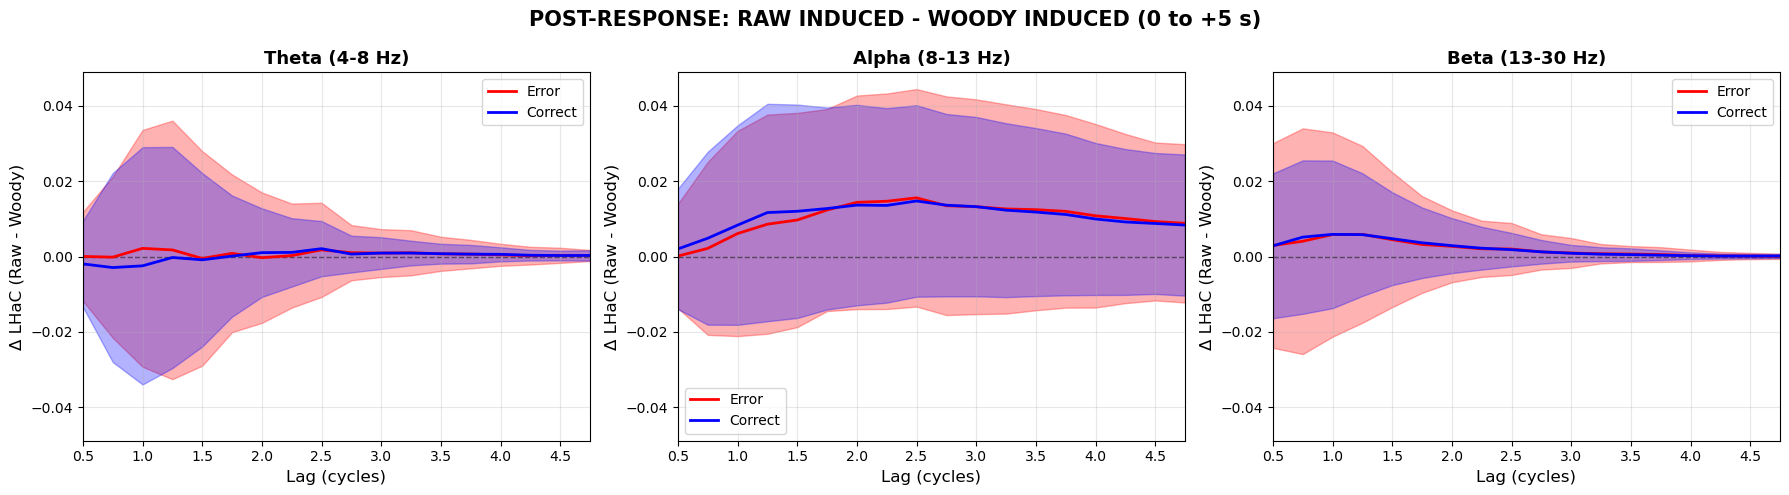

In [32]:
# ============================================================================
# COMPUTE POST: RAW - WOODY DIFFERENCES
# ============================================================================

# Post-Response - Error (raw - woody)
theta_error_rawwoody_post_subj = theta_raw_error_post_subj - theta_woody_error_post_subj
alpha_error_rawwoody_post_subj = alpha_raw_error_post_subj - alpha_woody_error_post_subj
beta_error_rawwoody_post_subj = beta_raw_error_post_subj - beta_woody_error_post_subj

# Post-Response - Correct (raw - woody)
theta_correct_rawwoody_post_subj = theta_raw_correct_post_subj - theta_woody_correct_post_subj
alpha_correct_rawwoody_post_subj = alpha_raw_correct_post_subj - alpha_woody_correct_post_subj
beta_correct_rawwoody_post_subj = beta_raw_correct_post_subj - beta_woody_correct_post_subj

# ============================================================================
# CALCULATE Y-AXIS LIMITS FOR RAW-WOODY DIFFERENCE PLOTS
# ============================================================================

# Collect all raw-woody difference data
all_rawwoody_data = [
    theta_error_rawwoody_post_subj, alpha_error_rawwoody_post_subj, beta_error_rawwoody_post_subj,
    theta_correct_rawwoody_post_subj, alpha_correct_rawwoody_post_subj, beta_correct_rawwoody_post_subj
]

# Calculate global limits for raw-woody differences
y_min_rawwoody = min([np.min(d.mean(axis=0) - d.std(axis=0)) for d in all_rawwoody_data])
y_max_rawwoody = max([np.max(d.mean(axis=0) + d.std(axis=0)) for d in all_rawwoody_data])

# Add some padding and ensure symmetric around zero
y_abs_max_rawwoody = max(abs(y_min_rawwoody), abs(y_max_rawwoody))
y_min_rawwoody = -y_abs_max_rawwoody * 1.1
y_max_rawwoody = y_abs_max_rawwoody * 1.1

# ============================================================================
# PLOT POST-RESPONSE: RAW - WOODY
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Theta
axes[0].axhline(0, color='k', linestyle='--', linewidth=1, alpha=0.5)
axes[0].plot(lags_range, theta_error_rawwoody_post_subj.mean(axis=0), 'r-', linewidth=2, label='Error')
axes[0].fill_between(lags_range,
                      theta_error_rawwoody_post_subj.mean(axis=0) - theta_error_rawwoody_post_subj.std(axis=0),
                      theta_error_rawwoody_post_subj.mean(axis=0) + theta_error_rawwoody_post_subj.std(axis=0),
                      color='r', alpha=0.3)
axes[0].plot(lags_range, theta_correct_rawwoody_post_subj.mean(axis=0), 'b-', linewidth=2, label='Correct')
axes[0].fill_between(lags_range,
                      theta_correct_rawwoody_post_subj.mean(axis=0) - theta_correct_rawwoody_post_subj.std(axis=0),
                      theta_correct_rawwoody_post_subj.mean(axis=0) + theta_correct_rawwoody_post_subj.std(axis=0),
                      color='b', alpha=0.3)
axes[0].set_xlabel('Lag (cycles)', fontsize=12)
axes[0].set_ylabel('Δ LHaC (Raw - Woody)', fontsize=12)
axes[0].set_title('Theta (4-8 Hz)', fontsize=13, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[0].set_xlim([x_min, x_max])
axes[0].set_ylim([y_min_rawwoody, y_max_rawwoody])

# Alpha
axes[1].axhline(0, color='k', linestyle='--', linewidth=1, alpha=0.5)
axes[1].plot(lags_range, alpha_error_rawwoody_post_subj.mean(axis=0), 'r-', linewidth=2, label='Error')
axes[1].fill_between(lags_range,
                      alpha_error_rawwoody_post_subj.mean(axis=0) - alpha_error_rawwoody_post_subj.std(axis=0),
                      alpha_error_rawwoody_post_subj.mean(axis=0) + alpha_error_rawwoody_post_subj.std(axis=0),
                      color='r', alpha=0.3)
axes[1].plot(lags_range, alpha_correct_rawwoody_post_subj.mean(axis=0), 'b-', linewidth=2, label='Correct')
axes[1].fill_between(lags_range,
                      alpha_correct_rawwoody_post_subj.mean(axis=0) - alpha_correct_rawwoody_post_subj.std(axis=0),
                      alpha_correct_rawwoody_post_subj.mean(axis=0) + alpha_correct_rawwoody_post_subj.std(axis=0),
                      color='b', alpha=0.3)
axes[1].set_xlabel('Lag (cycles)', fontsize=12)
axes[1].set_ylabel('Δ LHaC (Raw - Woody)', fontsize=12)
axes[1].set_title('Alpha (8-13 Hz)', fontsize=13, fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)
axes[1].set_xlim([x_min, x_max])
axes[1].set_ylim([y_min_rawwoody, y_max_rawwoody])

# Beta
axes[2].axhline(0, color='k', linestyle='--', linewidth=1, alpha=0.5)
axes[2].plot(lags_range, beta_error_rawwoody_post_subj.mean(axis=0), 'r-', linewidth=2, label='Error')
axes[2].fill_between(lags_range,
                      beta_error_rawwoody_post_subj.mean(axis=0) - beta_error_rawwoody_post_subj.std(axis=0),
                      beta_error_rawwoody_post_subj.mean(axis=0) + beta_error_rawwoody_post_subj.std(axis=0),
                      color='r', alpha=0.3)
axes[2].plot(lags_range, beta_correct_rawwoody_post_subj.mean(axis=0), 'b-', linewidth=2, label='Correct')
axes[2].fill_between(lags_range,
                      beta_correct_rawwoody_post_subj.mean(axis=0) - beta_correct_rawwoody_post_subj.std(axis=0),
                      beta_correct_rawwoody_post_subj.mean(axis=0) + beta_correct_rawwoody_post_subj.std(axis=0),
                      color='b', alpha=0.3)
axes[2].set_xlabel('Lag (cycles)', fontsize=12)
axes[2].set_ylabel('Δ LHaC (Raw - Woody)', fontsize=12)
axes[2].set_title('Beta (13-30 Hz)', fontsize=13, fontweight='bold')
axes[2].legend()
axes[2].grid(alpha=0.3)
axes[2].set_xlim([x_min, x_max])
axes[2].set_ylim([y_min_rawwoody, y_max_rawwoody])

plt.suptitle('POST-RESPONSE: RAW INDUCED - WOODY INDUCED (0 to +5 s)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

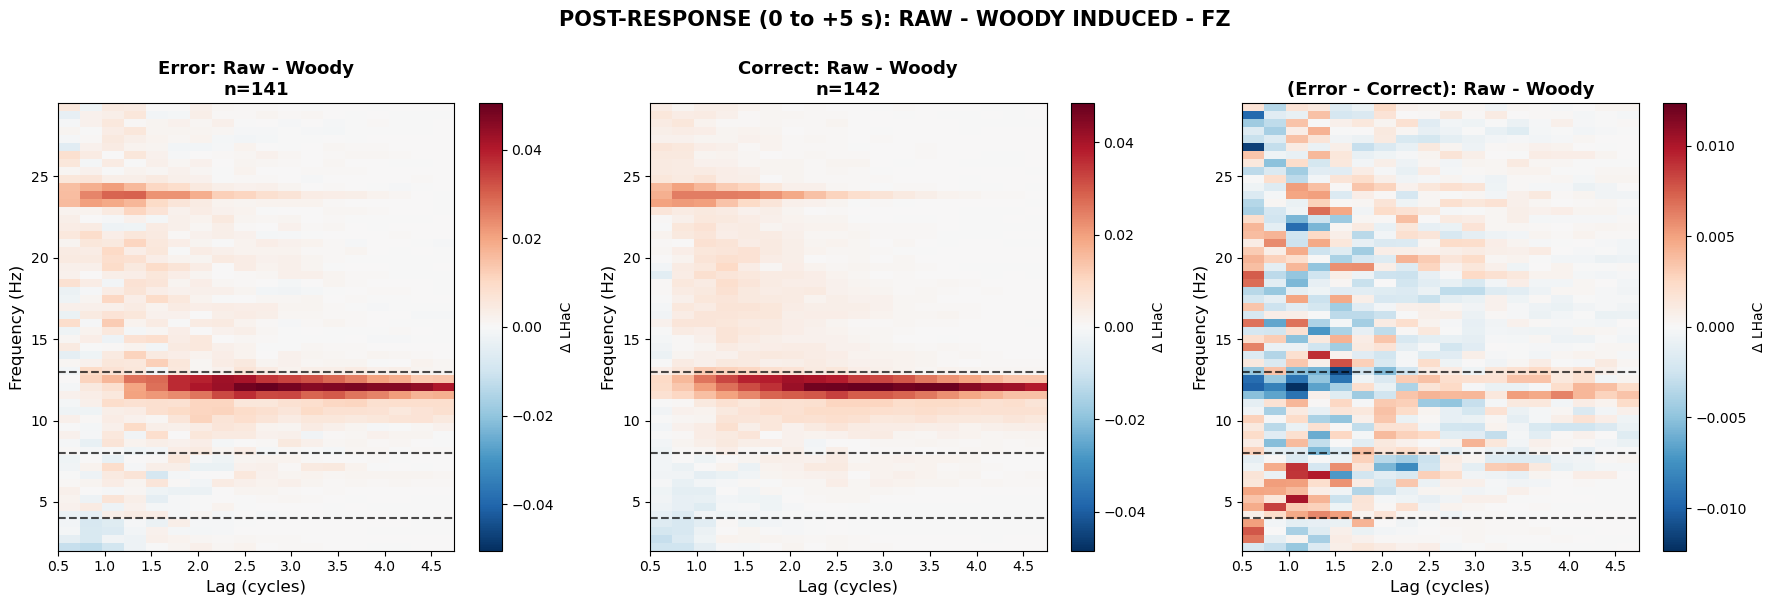

In [33]:
# ============================================================================
# COMPUTE POST: RAW - WOODY DIFFERENCES (for heatmaps)
# ============================================================================

# Post-Response - Error (raw - woody)
lhc_error_rawwoody_post = lhc_raw_error_post - lhc_woody_error_post

# Post-Response - Correct (raw - woody)
lhc_correct_rawwoody_post = lhc_raw_correct_post - lhc_woody_correct_post

# Post-Response - Error-Correct difference (raw - woody)
lhc_diff_rawwoody_post = lhc_raw_diff_post - lhc_woody_diff_post

# ============================================================================
# PLOT POST-RESPONSE: RAW - WOODY (HEATMAPS)
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Error: Raw - Woody
im1 = axes[0].imshow(lhc_error_rawwoody_post, aspect='auto', origin='lower', cmap='RdBu_r',
                     extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]],
                     vmin=-np.abs(lhc_error_rawwoody_post).max(), vmax=np.abs(lhc_error_rawwoody_post).max())
axes[0].axhline(4, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0].axhline(8, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0].axhline(13, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0].set_xlabel('Lag (cycles)', fontsize=12)
axes[0].set_ylabel('Frequency (Hz)', fontsize=12)
axes[0].set_title(f'Error: Raw - Woody\nn={len(all_results_error_post)}', fontweight='bold', fontsize=13)
plt.colorbar(im1, ax=axes[0], label='Δ LHaC')

# Correct: Raw - Woody
im2 = axes[1].imshow(lhc_correct_rawwoody_post, aspect='auto', origin='lower', cmap='RdBu_r',
                     extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]],
                     vmin=-np.abs(lhc_correct_rawwoody_post).max(), vmax=np.abs(lhc_correct_rawwoody_post).max())
axes[1].axhline(4, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1].axhline(8, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1].axhline(13, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1].set_xlabel('Lag (cycles)', fontsize=12)
axes[1].set_ylabel('Frequency (Hz)', fontsize=12)
axes[1].set_title(f'Correct: Raw - Woody\nn={len(all_results_correct_post)}', fontweight='bold', fontsize=13)
plt.colorbar(im2, ax=axes[1], label='Δ LHaC')

# (Error - Correct): Raw - Woody
im3 = axes[2].imshow(lhc_diff_rawwoody_post, aspect='auto', origin='lower', cmap='RdBu_r',
                     extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]],
                     vmin=-np.abs(lhc_diff_rawwoody_post).max(), vmax=np.abs(lhc_diff_rawwoody_post).max())
axes[2].axhline(4, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[2].axhline(8, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[2].axhline(13, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
axes[2].set_xlabel('Lag (cycles)', fontsize=12)
axes[2].set_ylabel('Frequency (Hz)', fontsize=12)
axes[2].set_title('(Error - Correct): Raw - Woody', fontweight='bold', fontsize=13)
plt.colorbar(im3, ax=axes[2], label='Δ LHaC')

plt.suptitle('POST-RESPONSE (0 to +5 s): RAW - WOODY INDUCED - FZ', fontsize=15, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

In [37]:
import numpy as np
import pickle
from pathlib import Path

# ============================================================================
# CREATE OUTPUT DIRECTORY
# ============================================================================

output_dir = Path("/Users/qmoreau/Documents/ERN_sim/autocoherence_results/")
output_dir.mkdir(parents=True, exist_ok=True)

In [40]:
# Pre-response period (-5 to 0s)
np.save(output_dir / "group_lhc_raw_error_pre.npy", lhc_raw_error_pre)
np.save(output_dir / "group_lhc_raw_correct_pre.npy", lhc_raw_correct_pre)
np.save(output_dir / "group_lhc_raw_diff_pre.npy", lhc_raw_diff_pre)

np.save(output_dir / "group_lhc_woody_error_pre.npy", lhc_woody_error_pre)
np.save(output_dir / "group_lhc_woody_correct_pre.npy", lhc_woody_correct_pre)
np.save(output_dir / "group_lhc_woody_diff_pre.npy", lhc_woody_diff_pre)

# Post-response period (0 to +5s)
np.save(output_dir / "group_lhc_raw_error_post.npy", lhc_raw_error_post)
np.save(output_dir / "group_lhc_raw_correct_post.npy", lhc_raw_correct_post)
np.save(output_dir / "group_lhc_raw_diff_post.npy", lhc_raw_diff_post)

np.save(output_dir / "group_lhc_woody_error_post.npy", lhc_woody_error_post)
np.save(output_dir / "group_lhc_woody_correct_post.npy", lhc_woody_correct_post)
np.save(output_dir / "group_lhc_woody_diff_post.npy", lhc_woody_diff_post)

In [41]:
# Pre-response - subject-level matrices (averaged over trials)
np.save(output_dir / "subjects_lhc_raw_error_pre.npy", lcs_raw_error_pre)
np.save(output_dir / "subjects_lhc_raw_correct_pre.npy", lcs_raw_correct_pre)
np.save(output_dir / "subjects_lhc_woody_error_pre.npy", lcs_woody_error_pre)
np.save(output_dir / "subjects_lhc_woody_correct_pre.npy", lcs_woody_correct_pre)

# Post-response - subject-level matrices
np.save(output_dir / "subjects_lhc_raw_error_post.npy", lcs_raw_error_post)
np.save(output_dir / "subjects_lhc_raw_correct_post.npy", lcs_raw_correct_post)
np.save(output_dir / "subjects_lhc_woody_error_post.npy", lcs_woody_error_post)
np.save(output_dir / "subjects_lhc_woody_correct_post.npy", lcs_woody_correct_post)
